# Nairobi rental market: the complete pipeline

One notebook, one run. `main.ipynb` contains the entire analysis inline, from
the raw portal export to the figures, model and rent guide. There are no
helper scripts to install or import.

| Stage | What it produces |
|---|---|
| Setup | paths, libraries, brand palette and plotting defaults |
| 1. Profile | `reports/data_profile.md` and `.json`, with database reconciliation |
| 2. Clean | 11,645-row cleaned table, step log and row log in `data/clean/` |
| 3. Explore | RQ1 tables and 7 figures in `reports/tables/` and `reports/figures/` |
| 4. Model | RQ2/RQ3 metrics, SHAP, segments, value measures, 5 figures |
| 5. Guide | rent-guide tables and the assembled draft |
| 6. Audit | data invariants and the headline model numbers |
| 7. Bundle | a private zip for the deployed dashboard |

**Data:** the raw export must be in `data/raw/rentals.csv`. It is not in the
repository, because it contains listing URLs and contact details.

**Run:** open the notebook and run every cell, top to bottom. A full run takes
about eight minutes, dominated by the boosted models.

**Privacy:** no listing, URL, contact detail or raw description is displayed.
Cells show aggregates and counts only.

## 0. Setup

Locate the project root, set display options and record the library versions so
the run can be reproduced.

In [1]:
import io
import json
import sys
import tempfile
import time
import types
import zipfile
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import numpy as np
import pandas as pd

# Works whether the notebook is opened at the project root or one level down.
ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("project root:", ROOT)
print("python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("raw export present:", (ROOT / "data" / "raw" / "rentals.csv").exists())

project root: C:\Users\hp\Downloads\applied research project 1
python: 3.12.4
pandas: 3.1.1
raw export present: True


## Brand and plotting defaults

One palette for every figure: burnt orange `#CE5A31` as the single accent,
near-black text, grey hints, light rules and a warm callout fill. Documents and
figures use a serif stack; the dashboard uses its own UI font.

In [2]:
from __future__ import annotations

import matplotlib
from matplotlib.colors import LinearSegmentedColormap

# --------------------------------------------------------------------------
# Palette
# --------------------------------------------------------------------------
PRIMARY = "#CE5A31"        # burnt orange - the single accent
PRIMARY_DARK = "#A34420"   # darker shade for emphasis and gradients
TEXT = "#1A1A1A"           # near-black body text
MUTED = "#666666"          # grey hints and secondary marks
RULE = "#CCCCCC"           # light grey rules, borders and grid
CALLOUT = "#F4EDE9"        # warm callout fill
PAPER = "#FFFFFF"

# Two-tone emphasis used where a chart needs a positive/negative direction.
POSITIVE = PRIMARY
NEGATIVE = MUTED

SERIF = ["Georgia", "Cambria", "Times New Roman", "DejaVu Serif", "serif"]


def sequential_cmap() -> LinearSegmentedColormap:
    """Warm sequential colormap for heatmaps: callout -> orange -> dark."""
    return LinearSegmentedColormap.from_list(
        "brand_orange", [CALLOUT, "#E8B39C", PRIMARY, PRIMARY_DARK, "#6E2B13"])


def diverging_cmap() -> LinearSegmentedColormap:
    """Muted two-tone scale: grey (negative) -> callout -> orange (positive)."""
    return LinearSegmentedColormap.from_list(
        "brand_diverging", [MUTED, "#B9B9B9", CALLOUT, "#E8B39C", PRIMARY])


def apply_theme() -> None:
    """Set Matplotlib defaults to the project identity."""
    matplotlib.rcParams.update({
        "font.family": "serif",
        "font.serif": SERIF,
        "font.size": 11,
        "text.color": TEXT,
        "axes.labelcolor": TEXT,
        "axes.edgecolor": RULE,
        "axes.linewidth": 0.9,
        "axes.facecolor": PAPER,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlecolor": TEXT,
        "axes.titlepad": 12,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": RULE,
        "grid.linewidth": 0.7,
        "grid.alpha": 0.9,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": TEXT,
        "ytick.labelcolor": TEXT,
        "legend.frameon": True,
        "legend.facecolor": PAPER,
        "legend.edgecolor": RULE,
        "legend.fontsize": 9,
        "figure.facecolor": PAPER,
        "figure.dpi": 110,
        "savefig.dpi": 160,
        "savefig.facecolor": PAPER,
        "lines.linewidth": 2.0,
    })


def soften(ax, grid_axis: str = "y") -> None:
    """Hide the top/right spines and grid only on the value axis."""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(True, axis=grid_axis, color=RULE, linewidth=0.7)
    ax.grid(False, axis="x" if grid_axis == "y" else "y")


def hint(fig, text: str, y: float = 0.005) -> None:
    """Small italic grey note along the bottom of a figure."""
    fig.text(0.01, y, text, fontsize=8, style="italic", color=MUTED,
             ha="left", va="bottom")


def enforce_fonts(fig=None) -> None:
    """Re-apply the serif stack to every text artist on a figure.

    Third-party plotting helpers (SHAP's summary plot, for example) set their
    own fonts after the global theme is applied; this brings them back
    on-brand without changing the data shown.
    """
    import matplotlib.pyplot as plt

    fig = fig or plt.gcf()
    for ax in fig.axes:
        for text in (ax.title, ax.xaxis.label, ax.yaxis.label):
            text.set_fontfamily(SERIF)
            text.set_color(TEXT)
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_fontfamily(SERIF)
            label.set_color(TEXT)
        legend = ax.get_legend()
        if legend is not None:
            for text in legend.get_texts():
                text.set_fontfamily(SERIF)
    for text in fig.texts:
        text.set_fontfamily(SERIF)

In [3]:
# Expose the brand helpers as a module so the stage code can call
# brand.apply_theme() exactly as it always has.
brand = types.ModuleType("brand")
for _name in ("PRIMARY", "PRIMARY_DARK", "TEXT", "MUTED", "RULE", "CALLOUT",
              "PAPER", "POSITIVE", "NEGATIVE", "SERIF", "sequential_cmap",
              "diverging_cmap", "apply_theme", "soften", "hint",
              "enforce_fonts"):
    setattr(brand, _name, globals()[_name])
sys.modules["brand"] = brand
brand.apply_theme()
print("brand theme applied")

brand theme applied


## 1. Data understanding

Profile the raw export and the SQLite cache without modifying either. This
quantifies every issue the cleaning rules then address: duplicate adverts,
periods and currencies, the Property24 `Erf Size` parser artefact, and the
Kenya Property Centre suburb hierarchy.

In [4]:
from __future__ import annotations

import argparse
import json
import sqlite3
import sys
import zlib
from pathlib import Path

import pandas as pd
from bs4 import BeautifulSoup

PERIOD_PATTERNS = {
    "per night / nightly": r"(?:per\s*night|nightly|/night|per\s*nights?)",
    "daily rate / per day": r"(?:daily\s*rate|per\s*day|/day)",
    "per week / weekly": r"(?:per\s*week|weekly|/week|per\s*weeks?)",
    "per annum / yearly": r"(?:per\s*annum|per\s*year|yearly|/year|p\.a\.)",
    "airbnb / short stay": (
        r"(?:airbnb|short[\s-]?let|short[\s-]?stay|serviced|guest\s*house|"
        r"self[\s-]?catering)"
    ),
    "for sale": r"\bfor\s*sale\b",
}

SIZE_FLAG_LOW, SIZE_FLAG_HIGH = 15.0, 1200.0   # sqm
PRICE_FLAG_LOW, PRICE_FLAG_HIGH = 8_000.0, 1_000_000.0   # KSh / month


def load(csv_path: Path) -> pd.DataFrame:
    return pd.read_csv(csv_path, low_memory=False)


def inspect_db(db_path: Path) -> dict:
    """Read-only inspection of rentals.db and Property24 cached pages."""
    if not db_path.exists():
        return {}
    con = sqlite3.connect(db_path.resolve().as_uri() + "?mode=ro", uri=True)
    cur = con.cursor()
    tables = {
        r[0]: cur.execute(f"SELECT COUNT(*) FROM {r[0]}").fetchone()[0]
        for r in cur.execute(
            "SELECT name FROM sqlite_master WHERE type='table'"
        ).fetchall()
    }
    p24_pages = cur.execute(
        "SELECT COUNT(*) FROM pages WHERE url LIKE '%property24%'"
    ).fetchone()[0]
    kpc_pages = cur.execute(
        "SELECT COUNT(*) FROM pages WHERE url NOT LIKE '%property24%'"
    ).fetchone()[0]

    # Scan cached Property24 pages for listing IDs and Erf Size vs Floor Size.
    all_ids: set[str] = set()
    cards_total = 0
    erf_only_urls: set[str] = set()
    floor_urls: set[str] = set()
    for _, body in cur.execute(
            "SELECT url, body FROM pages WHERE url LIKE '%property24%'"):
        html = zlib.decompress(body).decode("utf-8", "replace")
        soup = BeautifulSoup(html, "html.parser")
        tiles = soup.select("div.js_listingTile")
        cards_total += len(tiles)
        for t in tiles:
            lid = t.get("data-listing-number")
            if lid:
                all_ids.add(lid)
            a = t.find("a", href=True)
            if not a:
                continue
            u = "https://www.property24.co.ke" + a["href"].split("#")[0]
            titles = {
                el.get("title", "").strip().lower()
                for el in t.find_all(attrs={"title": True})
            }
            if "floor size" in titles:
                floor_urls.add(u)
            elif "erf size" in titles:
                erf_only_urls.add(u)

    con.close()
    return {
        "tables": tables,
        "p24_pages": p24_pages,
        "kpc_pages": kpc_pages,
        "p24_cards_total": cards_total,
        "p24_distinct_ids_on_pages": len(all_ids),
        "p24_erf_only_urls": len(erf_only_urls),
        "p24_floor_urls": len(floor_urls),
    }


def section_overview(df: pd.DataFrame, db_info: dict) -> str:
    lines = ["## 1. Overview and Database Reconciliation", ""]
    lines.append(f"- Raw export rows (`rentals.csv`): **{len(df):,}**")
    lines.append(
        f"- Columns: **{df.shape[1]}** ({', '.join(df.columns)}) "
        f" - note `n_obs` (always 1) is added by `export_csv` from "
        f"`price_history`"
    )
    lines.append(
        f"- Memory use: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB"
    )
    if db_info:
        t = db_info["tables"]
        lines.append(
            f"- SQLite database (`rentals.db`): `listings` = "
            f"**{t.get('listings', 0):,}** rows, `pages` = "
            f"**{t.get('pages', 0):,}** cached HTML pages "
            f"(**{db_info['p24_pages']:,}** Property24 + "
            f"**{db_info['kpc_pages']:,}** Kenya Property Centre), "
            f"`price_history` = **{t.get('price_history', 0):,}** rows"
        )
        lines.append(
            f"- Property24 parser coverage (`check_coverage.py` "
            f"reconciliation): **{db_info['p24_pages']:,}** pages x 21 cards = "
            f"**{db_info['p24_cards_total']:,}** cards, **12,596** parsed "
            f"(4 cards had no price), covering "
            f"**{db_info['p24_distinct_ids_on_pages']:,}** distinct "
            f"`data-listing-number` IDs (12,380 with prices). Because **137** "
            f"Property24 listing IDs appear under multiple URL slugs in "
            f"`listings`, the table holds **12,517** unique Property24 URLs."
        )
    lines.append("")
    lines.append("### Missing values per column")
    lines.append("")
    lines.append("| Column | Missing | Missing % | Distinct |")
    lines.append("|---|---:|---:|---:|")
    for col in df.columns:
        n_missing = int(df[col].isna().sum())
        lines.append(
            f"| {col} | {n_missing:,} | {100 * n_missing / len(df):.1f}% "
            f"| {df[col].nunique(dropna=True):,} |"
        )
    lines.append("")
    return "\n".join(lines)


def section_sources(df: pd.DataFrame) -> str:
    counts = df["source"].value_counts(dropna=False)
    lines = ["## 2. Source Split", ""]
    lines.append("```sql")
    lines.append("SELECT source, COUNT(*) FROM listings GROUP BY source;")
    lines.append("```")
    lines.append("")
    lines.append("| Source | Listings (URLs) | Share | Distinct Portal IDs | "
                 "Repeated IDs |")
    lines.append("|---|---:|---:|---:|---:|")
    for src, n in counts.items():
        sub = df[df["source"] == src]
        if src == "property24":
            lids = sub["url"].str.extract(r"-(\d+)$")[0]
        else:
            lids = sub["url"].str.extract(r"/(\d+)-")[0]
        n_id = int(lids.nunique())
        lines.append(
            f"| {src} | {n:,} | {100 * n / len(df):.1f}% | {n_id:,} | "
            f"{n - n_id:,} |"
        )
    lines.append("")
    return "\n".join(lines)


def section_duplicates(df: pd.DataFrame) -> str:
    lines = ["## 3. Duplicates (rules C2, C4)", ""]
    lines.append("### C2 - within-source duplicates")
    lines.append("")
    p24 = df[df["source"] == "property24"]
    p24_lids = p24["url"].str.extract(r"-(\d+)$")[0]
    n_dup_lid = int(p24_lids.duplicated().sum())
    n_dup_exact = int(
        df.duplicated(subset=["source", "title", "price_kes", "raw_text"]).sum()
    )
    lines.append(
        f"- Exact duplicate `url` rows: "
        f"**{int(df.duplicated(subset=['url']).sum()):,}**")
    lines.append(
        f"- Duplicate Property24 `data-listing-number` IDs across different "
        f"URL slugs: **{n_dup_lid:,}**")
    lines.append(
        f"- Byte-identical re-posted cards (`source`, `title`, `price_kes`, "
        f"`raw_text`): **{n_dup_exact:,}**")

    # Badge text ("Featured 18", "AVAILABLE NOW", "Added today") differs
    # between re-posts of the same advert, so C2b compares normalised text.
    normalised = (df["raw_text"].fillna("").astype(str).str.lower()
                    .str.replace(r"^(?:featured|premium|standard|spotlight)?\s*\d*\s*"
                                 r"(?:video\s*)?(?:available\s+now\s*)?", "",
                                 regex=True)
                    .str.replace(r"\badded\s+(?:today|yesterday|\d+\s+\w+\s+ago)\b",
                                 "", regex=True)
                    .str.replace(r"\b(?:featured|premium)\b", "", regex=True)
                    .str.replace(r"\s+", " ", regex=True).str.strip())
    n_dup_norm = int(df.assign(_s=normalised).duplicated(
        subset=["source", "title", "price_kes", "_s"]).sum())
    lines.append(
        f"- Re-posted cards after normalising badge text (the figure rule C2b "
        f"uses): **{n_dup_norm:,}**")
    lines.append("")

    lines.append("### C4 - cross-source duplicate candidates")
    lines.append("")
    a = df[df["source"] == "property24"].copy()
    b = df[df["source"] != "property24"].copy()
    for frame in (a, b):
        frame["nb_key"] = (
            frame["neighborhood"]
            .astype(str)
            .str.lower()
            .str.replace(r"[^a-z0-9]+", " ", regex=True)
            .str.strip()
        )
    a_sz = a[a["size_sqm"].notna()]
    b_sz = b[b["size_sqm"].notna()]
    m_strict = a_sz.merge(
        b_sz,
        on=["nb_key", "bedrooms", "bathrooms", "size_sqm", "price_kes"],
        how="inner",
    )
    m_loose = a.merge(
        b,
        on=["nb_key", "bedrooms", "bathrooms", "price_kes"],
        how="inner",
    )
    lines.append(
        f"- Strict match before neighbourhood normalisation: "
        f"**{len(m_strict):,}** pairs ({m_strict['url_y'].nunique():,} "
        f"distinct KPC rows); increases once KPC suburbs in `location_text` "
        f"are normalised in rule C6.")
    lines.append(
        f"- Loose match (ignoring `size_sqm`, which is 52% missing): "
        f"**{len(m_loose):,}** pairs covering "
        f"{m_loose['url_y'].nunique():,} distinct KPC rows (flagged, not "
        f"auto-dropped).")
    lines.append("")
    return "\n".join(lines)


def section_prices(df: pd.DataFrame) -> str:
    lines = ["## 4. Rent Values, Periods, and Currency (rules C1, C3, C5)", ""]
    price = pd.to_numeric(df["price_kes"], errors="coerce")
    desc = price.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    lines.append("### `price_kes` distribution (raw, all rows)")
    lines.append("")
    lines.append("| Stat | Value (KSh) |")
    lines.append("|---|---:|")
    labels = {
        "count": "Count",
        "mean": "Mean",
        "std": "Std dev",
        "min": "Min",
        "1%": "1st percentile",
        "5%": "5th percentile",
        "25%": "25th percentile",
        "50%": "Median",
        "75%": "75th percentile",
        "95%": "95th percentile",
        "99%": "99th percentile",
        "max": "Max",
    }
    for key, label in labels.items():
        if key in desc.index:
            lines.append(f"| {label} | {desc[key]:,.0f} |")
    lines.append("")

    lines.append("### Period column and text keywords (rule C3, question Q7)")
    lines.append("")
    lines.append("| Period / Keyword | Rows matching |")
    lines.append("|---|---:|")
    for per, n in df["period"].value_counts(dropna=False).items():
        lines.append(f"| `period == '{per}'` | {n:,} "
                     f"({100 * n / len(df):.1f}%) |")
    text = (df["title"].fillna("") + " " + df["raw_text"].fillna("")).str.lower()
    for label, pattern in PERIOD_PATTERNS.items():
        mask = text.str.contains(pattern, regex=True, na=False)
        lines.append(f"| text: {label} | {int(mask.sum()):,} |")
    usd = text.str.contains(r"(?:usd\s*[\d,]+|[\d,]+\s*usd|\$[\d,]+)",
                            regex=True)
    lines.append(f"| text: quotes USD / `$` amount | {int(usd.sum()):,} |")
    lines.append(
        f"| text: quotes USD with `price_kes < 50,000` (price is USD) | "
        f"{int((usd & (price < 50_000)).sum()):,} |")
    lines.append("")
    return "\n".join(lines)


def section_features(df: pd.DataFrame, db_info: dict) -> str:
    lines = ["## 5. Feature Plausibility and `Erf Size` Parser Artefact "
             "(rules C5, C7)", ""]
    for col, label, low, high in [
        ("size_sqm", "Floor size (m²)", SIZE_FLAG_LOW, SIZE_FLAG_HIGH),
        ("bedrooms", "Bedrooms", 0, 10),
        ("bathrooms", "Bathrooms", 1, 12),
        ("parking", "Parking spaces", 1, 10),
        ("toilets", "Toilets (KPC only)", 1, 10),
    ]:
        s = pd.to_numeric(df[col], errors="coerce")
        lines.append(f"### {label} (`{col}`)")
        lines.append(
            f"- Present: {int(s.notna().sum()):,} / {len(df):,} "
            f"({100 * s.notna().mean():.1f}%)")
        if s.notna().any():
            lines.append(
                f"- Min {s.min():,.1f} | p25 {s.quantile(0.25):,.1f} | "
                f"median {s.median():,.1f} | p75 {s.quantile(0.75):,.1f} | "
                f"max {s.max():,.1f}")
            lines.append(
                f"- Outside [{low:g}, {high:g}]: below = "
                f"**{int((s < low).sum()):,}**, above = "
                f"**{int((s > high).sum()):,}**")
        lines.append("")

    if db_info:
        lines.append("### Property24 `Erf Size` (Land Size) vs `Floor Size` "
                     "Artefact")
        lines.append(
            f"- In `rentals.db`, **{db_info['p24_erf_only_urls']:,}** Property24 "
            f"cards provide `title='Erf Size'` (land/plot area, e.g. "
            f"`2 025 m²` for 0.5 acres or `4 046.86 m²` for 1 acre) and no "
            f"`Floor Size`.")
        lines.append(
            "- When `Erf Size` was formatted with a thousands space "
            "(`2 025 m²`, `1 000 m²`, `1 234 m²`), the fallback regex "
            "`SQM_RE` captured only the digits after the space (`25.0`, "
            "`0.0`, `234.0`), making 4-6 bedroom mansions appear to have a "
            "25 m² floor size. Rule C5 detects and blanks these land-size "
            "artefacts and enforces both lower (`>= 15 m²/bed`) and upper "
            "(`<= 250 m²/bed`) floor-size density bounds.")
        lines.append("")
    return "\n".join(lines)


def section_neighborhoods(df: pd.DataFrame) -> str:
    lines = ["## 6. Neighbourhood Field Quality (rule C6)", ""]
    nb = df["neighborhood"].fillna("")
    lines.append(f"- Distinct raw `neighborhood` values: **{nb.nunique():,}**")
    lines.append(
        f"- Values > 40 chars (listing titles captured as neighbourhoods): "
        f"**{int((nb.str.len() > 40).sum()):,}** rows")
    loc_plus = (
        df["location_text"]
        .fillna("")
        .str.contains(r"\b[A-Z]{2}\d{2}\+", regex=True, na=False)
    )
    lines.append(
        f"- `location_text` with Google Plus Codes: "
        f"**{int(loc_plus.sum()):,}** rows")
    lines.append(
        "- Kenya Property Centre hierarchy issue: KPC URLs and "
        "`location_text` store `<Suburb>, <District>, Nairobi` (e.g. "
        "`Runda, Westlands, Nairobi` [150 rows], `Riverside Drive, Westlands, "
        "Nairobi` [130+ rows], `Loresho, Westlands, Nairobi` [30 rows], "
        "`Rosslyn, Westlands, Nairobi` [23 rows], `Thome, Nairobi Central, "
        "Nairobi` [13 rows]). Because the crawler took `parts[-2]` (the "
        "district), over 500 KPC listings were assigned to container "
        "districts (`westlands`, `nairobi central`, `nairobi`, `embakasi`) "
        "instead of their actual suburb. Rule C6 resolves the true suburb "
        "from the KPC URL path and `location_text`.")
    lines.append("")
    return "\n".join(lines)


def run_profile(argv: list[str] | None = None) -> int:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--csv", default=str(ROOT / "data" / "raw" / "rentals.csv"))
    parser.add_argument("--db", default=str(ROOT / "data" / "raw" / "rentals.db"))
    parser.add_argument("--out", default=str(ROOT / "reports" / "data_profile.md"))
    parser.add_argument("--json", default=str(ROOT / "reports" / "data_profile.json"))
    args = parser.parse_args(argv)

    csv_path = Path(args.csv)
    if not csv_path.exists():
        print(f"ERROR: {csv_path} not found", file=sys.stderr)
        return 1

    df = load(csv_path)
    db_info = inspect_db(Path(args.db))
    print(f"Loaded {len(df):,} rows from {csv_path.name}")

    parts = [
        "# Data Profile: Raw `rentals.csv` & `rentals.db`",
        "",
        f"Generated by `main.ipynb` on "
        f"{pd.Timestamp.now(tz='UTC').strftime('%Y-%m-%d %H:%M UTC')}.",
        "",
        "Read-only: the raw database and raw export are never modified.",
        "",
        section_overview(df, db_info),
        section_sources(df),
        section_duplicates(df),
        section_prices(df),
        section_features(df, db_info),
        section_neighborhoods(df),
    ]
    report = "\n".join(parts)

    out_path = Path(args.out)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    out_path.write_text(report, encoding="utf-8")
    print(f"Wrote {out_path.relative_to(ROOT)}")

    price = pd.to_numeric(df["price_kes"], errors="coerce")
    key = {
        "rows": int(len(df)),
        "columns": int(df.shape[1]),
        "source_counts": {
            str(k): int(v) for k, v in df["source"].value_counts().items()
        },
        "unique_urls": int(df["url"].nunique()),
        "duplicate_url_rows": int(df.duplicated(subset=["url"]).sum()),
        "period_counts": {
            str(k): int(v)
            for k, v in df["period"].value_counts(dropna=False).items()
        },
        "price_median": float(price.median()),
        "price_min": float(price.min()),
        "price_max": float(price.max()),
        "size_missing": int(df["size_sqm"].isna().sum()),
        "distinct_neighborhoods_raw": int(df["neighborhood"].nunique()),
        "db_reconciliation": db_info,
    }
    json_path = Path(args.json)
    json_path.write_text(json.dumps(key, indent=2), encoding="utf-8")
    print(f"Wrote {json_path.relative_to(ROOT)}")
    return 0

_t0 = time.perf_counter()
_exit_code = run_profile([])
print(f"stage 'profile' exit {_exit_code} in "
      f"{time.perf_counter() - _t0:.1f} s")

Loaded 15,750 rows from rentals.csv


Wrote reports\data_profile.md
Wrote reports\data_profile.json
stage 'profile' exit 0 in 71.8 s


### What the raw data contains

In [5]:
raw = pd.read_csv(ROOT / "data" / "raw" / "rentals.csv", low_memory=False)
print(f"raw rows: {len(raw):,} | columns: {raw.shape[1]}")
display(raw["source"].value_counts().rename("listings").to_frame())
display(raw["period"].value_counts().rename("rows").to_frame())
display(raw["price_kes"].describe(percentiles=[.01, .25, .5, .75, .99])
        .to_frame("price_kes (KSh)"))

profile = json.loads((ROOT / "reports" / "data_profile.json").read_text())
print("database reconciliation")
for key in ("rows", "unique_urls", "source_counts", "size_missing"):
    print(f"  {key}: {profile[key]}")
db = profile["db_reconciliation"]
print(f"  pages: {db.get('p24_pages'):,} Property24 + {db.get('kpc_pages'):,} KPC")

raw rows: 15,750 | columns: 18


,listings
source,
property24,12517
kenyapropertycentre,3233


,rows
period,
month,15726
day,24


,price_kes (KSh)
count,"15,750.00"
mean,"569,133.31"
std,"12,885,523.78"
min,1.00
1%,"4,000.00"
25%,"95,000.00"
50%,"160,000.00"
75%,"350,000.00"
99%,"841,000.00"
max,"1,430,000,000.00"


database reconciliation
  rows: 15750
  unique_urls: 15750
  source_counts: {'property24': 12517, 'kenyapropertycentre': 3233}
  size_missing: 8197
  pages: 600 Property24 + 379 KPC


## 2. Cleaning

Rules C1 to C9, in order, each one logged at row level:

1. scope to residential rentals;
2. duplicate URLs and portal IDs, then re-posts;
3. periods and currency to monthly shillings;
4. cross-source duplicates;
5. plausibility of price, size, bedrooms and the land-size artefact;
6. neighbourhood normalisation;
7. flags rather than deletions where the value is ambiguous;
8. feature construction (amenities, keywords, street);
9. source labelling.

In [6]:
from __future__ import annotations

import argparse
import re
import sqlite3
import sys
import zlib
from pathlib import Path

import numpy as np
import pandas as pd

# --------------------------------------------------------------------------
# Thresholds (open question Q5 proposals, evidenced in reports/data_profile.md)
# --------------------------------------------------------------------------
PRICE_MIN = 8_000            # KSh per month, hard floor for any dwelling
PRICE_MAX = 5_000_000        # KSh per month, hard ceiling (sale prices sit above)
PRICE_LUXURY = 1_000_000     # above this: flagged, still kept

# Bedroom-specific monthly rent bounds.
# Evidence: after removing USD, daily-rate and sale listings, the lowest genuine
# rents observed are 15,000 (studio), 10,000-12,000 (1-bed), 20,000 (2-bed),
# 25,000 (3-bed), 35,000 (4-bed), 55,000 (5+). Everything below those floors is
# a USD mislabel ($3,000-$4,500), a daily rate or a missing-zero typo.
BEDROOM_PRICE_BOUNDS = {
    0: (10_000, 400_000),
    1: (11_000, 800_000),
    2: (16_000, 1_200_000),
    3: (24_000, 2_200_000),
    4: (34_000, 3_500_000),
    5: (50_000, 5_000_000),   # 5 or more bedrooms
}
BEDROOMS_MAX = 10
BATHROOMS_MAX = 12
PARKING_MAX = 10
TOILETS_MAX = 10

# Floor-size (m2) plausibility. A dwelling is never smaller than 12 m2 per
# bedroom (a 4-bed house at 25 m2 is the land-size artefact) and rarely larger
# than 250 m2 per bedroom (a 1,500 m2 "1-bedroom" is a plot, not a floor).
SIZE_MIN, SIZE_MAX = 12.0, 1_500.0
SIZE_SQM_PER_BEDROOM_MIN = 12.0
SIZE_SQM_PER_BEDROOM_MAX = 250.0

SHORT_STAY_PRICE = 30_000    # nightly/daily language below this = mislabelled rate
USD_MAX_PRICE = 50_000       # a sub-50k price with USD text IS the dollar figure

# --------------------------------------------------------------------------
# Currency and period patterns (rules C3, C3b)
# --------------------------------------------------------------------------
NIGHTLY_RE = re.compile(
    r"(?:per\s*night|nightly|/night|per\s*nights?|short[\s-]?stay|"
    r"short[\s-]?let|airbnb|self[\s-]?catering)", re.I)
DAILY_RE = re.compile(r"(?:daily\s*rate|per\s*day|/day|per\s*diem)", re.I)
WEEKLY_RE = re.compile(r"(?:per\s*week|weekly|/week|per\s*weeks?)", re.I)
YEARLY_RE = re.compile(r"(?:per\s*annum|per\s*year|yearly|/year|p\.a\.)", re.I)
SALE_RE = re.compile(r"\bfor\s*sale\b|\bselling\s+price\b|\boff[\s-]?plan\b", re.I)
RENT_RE = re.compile(r"\b(?:for\s+rent|to\s+let|to\s+rent|rental|/mo|per\s+month|monthly)\b", re.I)
USD_AMOUNT_RE = re.compile(r"(?:usd\s*[\d,]+|[\d,]+\s*usd|\$\s*[\d,]+)", re.I)

# Commercial / non-residential language (rule C1).
# A dwelling with 1-7 bedrooms is residential even when the agent also markets
# it for office use ("4-bedroom villa + DSQ & office to let"), so the dedicated
# commercial phrases only trigger exclusion when the card has no bedroom count
# or an implausible one.
COMMERCIAL_RE = re.compile(
    r"(?:warehouse|godown|go-?down|showroom|factory|industrial\s+(?:park|area)|"
    r"business\s+park|office\s+space|office\s+to\s+let|commercial\s+property|"
    r"commercial\s+space|commercial\s+office|shop\s+to\s+let|clinic|salon|"
    r"restaurant\s+space)", re.I)
COMMERCIAL_MAX_BEDROOMS = 7

# A card priced per square foot is commercial by construction.
RENT_PER_SQFT_RE = re.compile(
    r"(?:per\s*(?:sq\.?\s*ft|sqft|square\s+feet)|/\s*sq\.?\s*ft)", re.I)

PLUS_CODE_RE = re.compile(r"\b[A-Z]{2}\d{2}\+[A-Z0-9]{2,6}\b")

# Explicit monthly rent stated in the body text ("Monthly Rent: KSh 120,000",
# "Rent: KES 360,000", "KSh 120,000 monthly", "KSh 450,000 PM").
MONTHLY_RENT_RE = re.compile(
    r"(?:monthly\s+rent|rent|asking\s+rent|price)\s*[:\-]?\s*"
    r"(?:kes|ksh|kshs\.?)\s*([\d][\d,\s]{3,12})"
    r"|(?:kes|ksh|kshs\.?)\s*([\d][\d,\s]{3,12})\s*(?:/mo|per\s*month|monthly|p\.?\s*m\.?|pm)\b",
    re.I)

# Property24 land-size artefact: a thousands-separated size such as "2 025 m²"
# or "1 234 m²" whose remainder was captured as the floor size.
SPACED_SIZE_RE = re.compile(
    r"\b\d{1,2}\s\d{3}(?:\.\d+)?\s*m(?:²|2|\u00b2)", re.I)


class CleaningLog:
    """Collects step-level and row-level log records."""

    def __init__(self) -> None:
        self.steps: list[dict] = []
        self.rows: list[dict] = []

    def step(self, rule: str, description: str, rows_in: int,
             rows_removed: int, rows_changed: int, notes: str = "") -> None:
        self.steps.append({
            "step": len(self.steps) + 1,
            "rule": rule,
            "description": description,
            "rows_in": rows_in,
            "rows_removed": rows_removed,
            "rows_changed": rows_changed,
            "rows_out": rows_in - rows_removed,
            "notes": notes,
        })

    def drop(self, url: str, rule: str, reason: str) -> None:
        self.rows.append({
            "url": url, "rule": rule, "action": "drop",
            "field": "", "old_value": "", "new_value": "", "reason": reason,
        })

    def change(self, url: str, rule: str, field: str, old, new,
               reason: str) -> None:
        self.rows.append({
            "url": url, "rule": rule, "action": "change",
            "field": field, "old_value": old, "new_value": new,
            "reason": reason,
        })


# ==========================================================================
# Rule C1 - scope
# ==========================================================================

def c1_scope(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C1: keep residential Nairobi apartments and houses advertised for rent.

    Drops (a) non-rural ptypes from other searches, (b) commercial/office/
    warehouse listings, and (c) listings that are offered for sale only. The
    original rule checked only `ptype`, which let commercial warehouses and
    sale prices through.
    """
    n_in = len(df)
    rental_ptypes = {
        "apartments-flats-to-rent-in-nairobi-c1890",
        "houses-to-rent-in-nairobi-p95",
        "flats-apartments",
        "houses",
    }
    bad_ptype = ~df["ptype"].isin(rental_ptypes)

    text = (df["title"].fillna("") + " " + df["raw_text"].fillna(""))

    # Commercial: dedicated non-residential phrases with no plausible bedroom
    # count, or a rent quoted per square foot.
    phrase = text.str.contains(COMMERCIAL_RE, regex=True)
    no_dwelling = df["bedrooms"].isna() | (df["bedrooms"] > COMMERCIAL_MAX_BEDROOMS)
    commercial = phrase & no_dwelling
    commercial |= text.str.contains(RENT_PER_SQFT_RE, regex=True)

    # Sale prices are removed in rule C5: every sale price observed in this
    # export sits above its bedroom band's monthly ceiling (a 1-bedroom at
    # KSh 4.4m, a 4-bedroom at KSh 65m). Cards that advertise "for sale or
    # rent" are deliberately kept, because the stored price is the monthly
    # rent the agent states on the card ("Rent: KSh 130,000"). A text-based
    # sale filter removed genuine dual listings, so it is not used.

    for url in df.loc[bad_ptype, "url"]:
        log.drop(url, "C1", f"ptype outside the Nairobi rental searches: "
                            f"{df.at[url, 'ptype']}")
    for url in df.loc[commercial & ~bad_ptype, "url"]:
        log.drop(url, "C1", "commercial / office / warehouse space, not a "
                            "residential dwelling")

    drop = bad_ptype | commercial
    out = df[~drop].copy()
    log.step("C1", "Restrict to residential Nairobi apartments and houses for "
                   "rent (drop commercial space; sale prices are caught by "
                   "the bedroom price bands in C5)",
             n_in, int(drop.sum()), 0,
             notes=f"ptype outside scope: {int(bad_ptype.sum())}; commercial: "
                   f"{int((commercial & ~bad_ptype).sum())}")
    return out


# ==========================================================================
# Rule C2a / C2b - de-duplication
# ==========================================================================

def _portal_id(urls: pd.Series) -> pd.Series:
    """Extract the portal's own listing id from a URL.

    Property24: `.../4-bedroom-apartment-flat-to-rent-in-westlands-116788345`
    KPC:        `.../nairobi/westlands/runda/69021-5-bedroom-...`
    """
    p24 = urls.str.extract(r"-(\d{5,})$")[0]
    kpc = urls.str.extract(r"/(\d{4,})-[a-z]")[0]
    return p24.fillna(kpc)


def c2a_dedup(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C2a: de-duplicate by url and by the portal's own listing id.

    The original collection plan expected 216 repeated Property24 cards. In this
export that shows
    up not as duplicate URLs but as one portal id published under several URL
    slugs (e.g. id 116788499 appears as a Syokimau 2-bed, a Westlands 4-bed and
    a Muthaiga North 1-bed). Keeping the earliest observation for each id
    removes that repetition.
    """
    n_in = len(df)
    work = df.sort_values("first_seen", kind="stable").copy()
    work["_pid"] = _portal_id(work["url"])

    dup_url = work.duplicated(subset=["url"], keep="first")
    dup_pid = work["_pid"].notna() & \
        work.duplicated(subset=["source", "_pid"], keep="first")

    for url in work.loc[dup_url, "url"]:
        log.drop(url, "C2a", "duplicate url")
    for url in work.loc[dup_pid & ~dup_url, "url"]:
        log.drop(url, "C2a", "same portal listing id published under a "
                             "second url slug (earliest observation kept)")

    out = work[~(dup_url | dup_pid)].drop(columns="_pid").copy()
    out = df.loc[out.index].copy()
    log.step("C2a", "De-duplicate by url and by the portal's own listing id",
             n_in, int((dup_url | dup_pid).sum()), 0,
             notes=f"duplicate urls: {int(dup_url.sum())}; repeated portal "
                   f"ids: {int((dup_pid & ~dup_url).sum())}")
    return out


def _card_signature(text: pd.Series) -> pd.Series:
    """Normalise a listing card before comparing it with other cards.

    Portal badges ("Featured 18", "Premium 20", "Video", "AVAILABLE NOW",
    "Added 3 days ago") differ between re-posts of the same advert, so they are
    stripped before the duplicate test.
    """
    s = text.fillna("").astype(str).str.lower()
    s = s.str.replace(
        r"^(?:featured|premium|standard|spotlight|verified)?\s*\d*\s*"
        r"(?:video\s*)?(?:available\s+now\s*)?", "", regex=True)
    s = s.str.replace(r"\badded\s+(?:today|yesterday|\d+\s+\w+\s+ago)\b", "",
                      regex=True)
    s = s.str.replace(r"\b(?:featured|premium)\b", "", regex=True)
    s = s.str.replace(r"\s+", " ", regex=True).str.strip()
    return s


def c2b_dedup_content(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C2b: drop re-posted identical cards (normalised text).

    Validation in the profile shows these groups never differ in size,
    bedrooms or neighbourhood, i.e. the same advert re-posted with a new id -
    while genuinely distinct units in one development carry different text.
    Keeping them would let one advert weigh the median many times over and
    would leak identical rows across the train/test split.
    """
    n_in = len(df)
    work = df.copy()
    work["_sig"] = _card_signature(work["raw_text"])
    work = work.sort_values("first_seen", kind="stable")
    key = ["source", "title", "price_kes", "_sig"]
    mask = work.duplicated(subset=key, keep="first")
    for url in work.loc[mask, "url"]:
        log.drop(url, "C2b", "re-posted identical card under a new url "
                             "(badges such as 'Featured 18' ignored)")
    kept_index = work.loc[~mask].index
    out = df.loc[kept_index].copy()
    log.step("C2b", "De-duplicate re-posted identical cards (source, title, "
                    "price, normalised card text)",
             n_in, int(mask.sum()), 0,
             notes="badge text ('Featured N', 'AVAILABLE NOW', 'Added today') "
                   "normalised before comparison; earliest kept")
    return out


# ==========================================================================
# Rule C6 - neighbourhood normalisation (runs before C4)
# ==========================================================================

# Raw value -> canonical suburb. Keys are lowercase and comma-stripped.
NB_CANONICAL = {
    # core suburbs
    "westlands": "westlands",
    "karen": "karen", "karen kcb": "karen",
    "kilimani": "kilimani",
    "kileleshwa": "kileleshwa",
    "lavington": "lavington", "muthangari": "lavington",
    "parklands": "parklands",
    "kitisuru": "kitisuru", "new kitisuru": "kitisuru",
    "old kitisuru": "kitisuru", "kihingo": "kitisuru",
    "spring valley": "spring valley",
    "riverside": "riverside", "riverside drive": "riverside",
    "muthaiga": "muthaiga", "old muthaiga": "muthaiga",
    "new muthaiga": "muthaiga",
    "muthaiga north": "muthaiga north",
    "loresho": "loresho", "loresho ridge": "loresho",
    "runda": "runda", "runda estate": "runda", "runda evergreen": "runda",
    "runda paradise": "runda", "runda mimosa": "runda", "runda mumwe": "runda",
    "nyari": "nyari", "nyari estate": "nyari", "nyari central": "nyari",
    "rosslyn": "rosslyn", "rosslyn lone tree": "rosslyn", "lone tree": "rosslyn",
    "gigiri": "gigiri",
    "peponi": "peponi", "peponi road": "peponi",
    "kyuna": "kyuna", "kyuna estate": "kyuna",
    "thigiri": "thigiri", "thigiri ridge": "thigiri",
    "ridgeways": "ridgeways",
    "garden estate": "garden estate",
    "garden city": "garden city",
    "thome": "thome", "thome estate": "thome", "thome own comp": "thome",
    "kiambu road": "kiambu road", "off kiambu road": "kiambu road",
    "edenville": "kiambu road", "fourways": "kiambu road",
    "lower kabete": "lower kabete", "lower kabete road": "lower kabete",
    "kabete": "kabete",
    # southern and eastern belt
    "langata": "langata", "langata road": "langata",
    "mugumo-ini": "langata", "mugumo-ini (langata)": "langata",
    "south b": "south b", "south c": "south c",
    "nairobi west": "nairobi west",
    "nairobi central": "nairobi central", "nairobi cbd": "nairobi central",
    "upper hill": "upper hill", "upperhill": "upper hill",
    "hurlingham": "hurlingham",
    "valley arcade": "valley arcade", "valley arcade area": "valley arcade",
    "ngong road": "ngong road", "ngong rd": "ngong road",
    "riruta": "riruta", "riruta satellite": "riruta",
    "naivasha road": "riruta",
    "kawangware": "kawangware",
    "dagoretti": "dagoretti", "dagoretti corner": "dagoretti",
    "dagoreti corner": "dagoretti",
    "mountain view": "mountain view",
    "kerarapon": "kerarapon", "kerarapon drive": "kerarapon",
    "kerarapon road": "kerarapon",
    "uthiru": "uthiru", "uthiru/ruthimitu": "uthiru",
    "uthiru-ruthimitu": "uthiru",
    "kasarani": "kasarani", "roysambu": "roysambu", "ruaraka": "ruaraka",
    "allsops": "ruaraka", "baba dogo": "baba dogo",
    "embakasi": "embakasi", "nyayo embakasi": "embakasi",
    "tassia": "embakasi", "donholm": "embakasi",
    "imara daima": "imara daima",
    "mombasa road": "mombasa road", "mombasa rd": "mombasa road",
    "mlolongo": "mlolongo", "katani": "katani", "syokimau": "syokimau",
    "kahawa sukari": "kahawa sukari", "kahawa west": "kahawa sukari",
    "ruaka": "ruaka", "ruaka road": "ruaka",
    "redhill": "redhill", "karura": "karura",
    "makadara": "makadara", "madaraka": "madaraka",
    "nairobi south": "nairobi south",
    "mbagathi way": "mbagathi way", "mbagathi road": "mbagathi way",
    "ngara": "ngara", "pangani": "pangani",
    "woodley": "woodley", "kangemi": "kangemi",
    "waithaka": "waithaka", "ngando": "ngando",
    "lakeview": "lakeview", "hillview": "hillview",
    "milimani": "milimani", "ngumo estate": "ngumo estate",
    "upper savanna": "upper savanna", "utawala": "utawala",
    "kibarage": "kibarage", "kenyatta": "kenyatta",
    "industrial area": "industrial area",
    "rhapta road": "westlands", "raphta road": "westlands",
    "valuing": "value",  # defensive: never expected, mapped to a safe value
}

# Broad container districts used by Kenya Property Centre. A listing sitting in
# one of these must be re-resolved from its URL path or its location line.
NB_CONTAINERS = {
    "westlands", "nairobi central", "nairobi", "embakasi",
    "eastleigh south", "california", "baba dogo", "makadara",
    "kilimani", "lavington", "karen", "muthaiga", "nairobi west",
    "kitisuru", "showtype", "unknown",
}

GAZETTEER = sorted(
    (k for k in NB_CANONICAL if len(k) >= 3),
    key=len, reverse=True)

# Headline scope: Nairobi County. These are metropolitan satellite towns that
# the Nairobi-wide portal searches also returned; they are kept but flagged so
# the report can run a strict Nairobi-only sensitivity check.
SATELLITE_TOWNS = {
    "syokimau", "mlolongo", "katani", "ruaka", "kikuyu", "redhill",
    "lower kabete", "kabete", "kahawa sukari", "ngong road", "uthiru",
}


def _clean_nb_string(value) -> str:
    s = "" if value is None or value is np.nan or value == "" else str(value)
    s = PLUS_CODE_RE.sub(" ", s)
    s = re.sub(r"^[*\-\s]+", "", s)
    s = re.sub(r"\s+", " ", s).strip().lower()
    return s


def _resolve_neighborhood(row: pd.Series) -> tuple[str, str]:
    """Return (canonical neighbourhood, method)."""
    raw = _clean_nb_string(row["neighborhood"])

    # --- Kenya Property Centre: recover the true suburb ------------------
    # KPC stores `<suburb>, <district>, Nairobi` and its URL path repeats the
    # hierarchy (`/nairobi/westlands/runda/69021-...`). The more specific part
    # is always the left-most one, so it is read before the district.
    if row["source"] == "kenyapropertycentre" and (
            raw in NB_CONTAINERS or raw not in NB_CANONICAL):
        match = re.search(r"/nairobi/(.+?)/\d+-", str(row["url"]))
        if match:
            segments = [s.replace("-", " ").strip().lower()
                        for s in match.group(1).split("/")]
            for seg in reversed(segments):
                if seg in NB_CANONICAL and NB_CANONICAL[seg] != raw:
                    return NB_CANONICAL[seg], "kpc url suburb"
        loc = str(row["location_text"] or "")
        parts = [re.sub(r"\s+", " ", p.strip().lower())
                 for p in loc.split(",") if p.strip()]
        if parts and parts[-1] in ("nairobi", "kiambu", "kajiado"):
            parts = parts[:-1]
        for part in parts:
            if part in NB_CANONICAL and NB_CANONICAL[part] != raw:
                return NB_CANONICAL[part], "kpc location suburb"
            for place in GAZETTEER:
                if place in ("nairobi", "nairobi central", "kabete",
                             "ruaka", "redhill", "karen", "westlands",
                             "kilimani", "lavington", "kileleshwa",
                             "muthaiga", "kitisuru", "embakasi"):
                    continue  # never let a district word win
                if re.search(rf"\b{re.escape(place)}\b", part):
                    if NB_CANONICAL[place] != raw:
                        return NB_CANONICAL[place], "kpc location suburb"

    # --- Direct lookup ---------------------------------------------------
    if raw in NB_CANONICAL:
        target = NB_CANONICAL[raw]
        return target, ("clean" if target == raw else "variant merge")

    # --- Title-like value: extract a place name from inside it -----------
    for place in GAZETTEER:
        if re.search(rf"\b{re.escape(place)}\b", raw):
            return NB_CANONICAL[place], "extracted from title"

    # --- Fall back to the location line, then the URL --------------------
    loc = str(row["location_text"] or "")
    parts = [re.sub(r"\s+", " ", p.strip().lower())
             for p in loc.split(",") if p.strip()]
    for part in parts:
        if part in NB_CANONICAL:
            return NB_CANONICAL[part], "from location line"
    for place in GAZETTEER:
        if re.search(rf"\b{re.escape(place)}\b", loc.lower()):
            return NB_CANONICAL[place], "from location line"

    return "unknown", "no place found"


def c6_neighborhoods(df: pd.DataFrame,
                     log: CleaningLog) -> tuple[pd.DataFrame, pd.DataFrame]:
    """C6: normalise neighbourhoods; keep a raw -> normalised mapping table."""
    n_in = len(df)
    raw = df["neighborhood"].fillna("").astype(str)
    resolved = df.apply(_resolve_neighborhood, axis=1)

    out = df.copy()
    out["neighborhood_raw"] = raw
    out["neighborhood"] = [r[0] for r in resolved]
    out["neighborhood_method"] = [r[1] for r in resolved]
    out["is_satellite_town"] = out["neighborhood"].isin(SATELLITE_TOWNS)

    changed = (raw.map(_clean_nb_string) != out["neighborhood"])
    for i in out.index[changed]:
        log.change(out.at[i, "url"], "C6", "neighborhood",
                   out.at[i, "neighborhood_raw"], out.at[i, "neighborhood"],
                   f"normalised ({out.at[i, 'neighborhood_method']})")

    # Plus-codes and street fragments are also stripped from location_text.
    loc = out["location_text"].fillna("").astype(str)
    loc_clean = (loc.str.replace(PLUS_CODE_RE, " ", regex=True)
                    .str.replace(r"\s+", " ", regex=True).str.strip())
    loc_changed = (loc != loc_clean) & out["location_text"].notna()
    for i in out.index[loc_changed]:
        log.change(out.at[i, "url"], "C6", "location_text",
                   out.at[i, "location_text"], loc_clean.at[i],
                   "plus-code stripped")
    out["location_text_clean"] = loc_clean

    mapping = (out.groupby(["neighborhood_raw", "neighborhood",
                            "neighborhood_method"], dropna=False)
                  .size().reset_index(name="rows")
                  .sort_values("rows", ascending=False))

    log.step("C6", "Normalise neighbourhoods: recover Kenya Property Centre "
                   "suburbs from URL and location line, strip plus-codes, "
                   "merge spelling variants, extract places from title-like "
                   "values",
             n_in, 0, int(changed.sum()) + int(loc_changed.sum()),
             notes=f"distinct raw values: {raw.nunique()}; distinct "
                   f"normalised: {out['neighborhood'].nunique()}; unknown: "
                   f"{int((out['neighborhood'] == 'unknown').sum())}; "
                   f"KPC suburbs recovered: "
                   f"{int(out['neighborhood_method'].str.startswith('kpc').sum())}")
    return out, mapping


# ==========================================================================
# Rule C3 / C3b - rent period, currency, missing zeros
# ==========================================================================

def _monthly_from_text(text: str, price: int) -> int | None:
    """Find an explicit monthly rent in the card text, if it is 10x the price.

    Catches missing-zero typos: a card priced KSh 12,000 whose body says
    "KSh 120,000 MONTHLY". Only a clean factor-of-ten correction is accepted,
    and only when the corrected value is inside the bedroom bounds.
    """
    for m in MONTHLY_RENT_RE.finditer(text):
        raw = m.group(1) or m.group(2)
        if not raw:
            continue
        digits = re.sub(r"[,\s]", "", raw)
        if not digits.isdigit():
            continue
        value = int(digits)
        if value >= price * 9 and value <= price * 11 and value >= 8_000:
            return value
    return None


def c3_period(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C3: normalise rent period to monthly; drop non-monthly asking rents.

    Handles (a) explicit non-monthly `period`, (b) nightly/daily/short-stay
    language with a non-monthly price, (c) weekly rates (converted), and
    (d) missing-zero typos corrected from an explicit monthly figure in the
    card text.
    """
    n_in = len(df)
    text = (df["title"].fillna("") + " " + df["raw_text"].fillna(""))
    low = text.str.lower()

    nightly = low.str.contains(NIGHTLY_RE, regex=True)
    daily = low.str.contains(DAILY_RE, regex=True)
    weekly = low.str.contains(WEEKLY_RE, regex=True)

    not_month = df["period"].astype(str) != "month"
    drop_a = not_month
    drop_b = ~drop_a & (nightly | daily) & (df["price_kes"] < SHORT_STAY_PRICE)
    conv_c = ~drop_a & ~drop_b & weekly & (df["price_kes"] < 60_000)

    out = df[~(drop_a | drop_b)].copy()

    for url in df.loc[drop_a, "url"]:
        log.drop(url, "C3", f"period='{df.at[url, 'period']}' is not monthly")
    for url in df.loc[drop_b, "url"]:
        log.drop(url, "C3",
                 f"nightly/daily/short-stay language with price "
                 f"{int(df.at[url, 'price_kes']):,} below "
                 f"{SHORT_STAY_PRICE:,} (a rate, not a monthly rent)")

    # Weekly -> monthly (x52/12).
    n_weekly = 0
    mask_conv = conv_c.reindex(out.index, fill_value=False)
    if mask_conv.any():
        old = out.loc[mask_conv, "price_kes"].astype(float)
        new = (old * 52 / 12).round().astype(int)
        for i in old.index:
            log.change(out.at[i, "url"], "C3", "price_kes", int(old.at[i]),
                       int(new.at[i]), "weekly rate converted to monthly (x52/12)")
        out.loc[mask_conv, "price_kes"] = new
        n_weekly = int(mask_conv.sum())

    # Missing-zero correction from an explicit monthly figure in the text.
    n_fixed = 0
    drop_typo = []
    for i in out.index:
        price = int(out.at[i, "price_kes"])
        fixed = _monthly_from_text(text.at[i], price)
        if fixed is None:
            continue
        beds = out.at[i, "bedrooms"]
        lo, hi = BEDROOM_PRICE_BOUNDS.get(
            min(int(beds), 5) if pd.notna(beds) else 2,
            BEDROOM_PRICE_BOUNDS[2])
        if lo <= fixed <= hi:
            log.change(out.at[i, "url"], "C3", "price_kes", price, fixed,
                       "missing zero in the card price; corrected from the "
                       "explicit monthly rent stated in the listing text")
            out.at[i, "price_kes"] = fixed
            n_fixed += 1
        else:
            drop_typo.append(i)

    for i in drop_typo:
        log.drop(out.at[i, "url"], "C3",
                 f"card price {int(out.at[i, 'price_kes']):,} contradicts the "
                 f"monthly rent stated in the text (mislabelled rate)")
    out = out.drop(index=drop_typo)

    # Flags kept on surviving rows (flag for review, do not drop).
    out["flag_short_stay"] = (
        text.reindex(out.index).str.contains(NIGHTLY_RE, regex=True)
        | text.reindex(out.index).str.contains(DAILY_RE, regex=True))
    out["flag_sale_mention"] = text.reindex(out.index).str.contains(
        SALE_RE, regex=True)
    out["flag_weekly_language"] = text.reindex(out.index).str.contains(
        WEEKLY_RE, regex=True)

    log.step("C3", "Normalise rent period to monthly: drop non-monthly and "
                   "daily/short-stay rates, convert weekly, repair missing "
                   "zeros from the stated monthly rent, flag short-stay and "
                   "sale language",
             n_in, int(drop_a.sum() + drop_b.sum() + len(drop_typo)),
             n_weekly + n_fixed,
             notes=f"non-monthly period: {int(drop_a.sum())}; nightly/daily: "
                   f"{int(drop_b.sum())}; weekly converted: {n_weekly}; "
                   f"missing zeros repaired: {n_fixed}; contradictory text "
                   f"prices dropped: {len(drop_typo)}; flagged short-stay: "
                   f"{int(out['flag_short_stay'].sum())}")
    return out


def c3b_currency(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C3b: drop listings whose rent is quoted in US dollars, not KSh.

    Found during cleaning (not anticipated in the plan): some agents price in
    USD - "4300USD Monthly", "$4,300 /mo", "USD 2,000/Month". The parser stores
    the bare number, so these become the cheapest listings while actually being
    luxury rents. They are dropped rather than converted because conversion
    needs an exchange-rate assumption this project does not invent.
    """
    n_in = len(df)
    text = (df["title"].fillna("") + " " + df["raw_text"].fillna(""))
    usd = text.str.contains(USD_AMOUNT_RE, regex=True)
    drop = usd & (df["price_kes"] < USD_MAX_PRICE)

    for url in df.loc[drop, "url"]:
        log.drop(url, "C3b",
                 f"rent quoted in USD in the listing text (price field holds "
                 f"{int(df.at[url, 'price_kes']):,}, not KSh)")
    out = df[~drop].copy()
    log.step("C3b", "Drop listings quoted in US dollars (the price field "
                    "would be misread as KSh)",
             n_in, int(drop.sum()), 0,
             notes=f"USD language anywhere: {int(usd.sum())}; of those priced "
                   f"under {USD_MAX_PRICE:,} (the price IS the dollar figure): "
                   f"{int(drop.sum())}; USD mention with a plausible KSh price "
                   f"kept: {int((usd & ~drop).sum())}")
    return out


# ==========================================================================
# Rule C4 - cross-source de-duplication
# ==========================================================================

def c4_cross_source(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C4: de-duplicate across sources, now on normalised neighbourhoods.

    Strict match: same neighbourhood, bedrooms, bathrooms, size and price with
    size present on both sides. The Property24 row is kept (larger, internally
    consistent source) and the Kenya Property Centre copy is dropped.
    """
    n_in = len(df)
    p24 = df[(df["source"] == "property24") & df["size_sqm"].notna()]
    kpc = df[(df["source"] != "property24") & df["size_sqm"].notna()]
    merge_on = ["neighborhood", "bedrooms", "bathrooms", "size_sqm", "price_kes"]
    hits = p24.merge(kpc, on=merge_on, how="inner", suffixes=("_p24", "_kpc"))

    drop_urls = set(hits["url_kpc"])
    mask = df["url"].isin(drop_urls)
    for url in df.loc[mask, "url"]:
        log.drop(url, "C4", "strict cross-source duplicate of a Property24 "
                            "listing (same neighbourhood, beds, baths, size, "
                            "price)")
    out = df[~mask].copy()
    kept = set(hits["url_p24"])
    out["flag_cross_source_dup"] = out["url"].isin(kept)
    log.step("C4", "De-duplicate across sources on normalised neighbourhoods "
                   "(strict match: neighbourhood, bedrooms, bathrooms, size, "
                   "price; size present both sides)",
             n_in, int(mask.sum()), int(out["flag_cross_source_dup"].sum()),
             notes=f"matched pairs: {len(hits)}; KPC copies dropped: "
                   f"{int(mask.sum())}; P24 survivors flagged: "
                   f"{int(out['flag_cross_source_dup'].sum())}")
    return out


# ==========================================================================
# Rule C5 - plausible values (incl. the Erf Size artefact)
# ==========================================================================

def _erf_size_urls(db_path: Path) -> set[str]:
    """Property24 cards that publish only a land size (`Erf Size`), no floor size.

    Read strictly read-only from the local page cache; no network.
    """
    if not db_path.exists():
        return set()
    try:
        con = sqlite3.connect(db_path.resolve().as_uri() + "?mode=ro", uri=True)
    except sqlite3.Error:
        return set()
    out: set[str] = set()
    try:
        from bs4 import BeautifulSoup
        for _, body in con.execute(
                "SELECT url, body FROM pages WHERE url LIKE '%property24%'"):
            html = zlib.decompress(body).decode("utf-8", "replace")
            soup = BeautifulSoup(html, "html.parser")
            for tile in soup.select("div.js_listingTile"):
                anchor = tile.find("a", href=True)
                if not anchor:
                    continue
                url = "https://www.property24.co.ke" + anchor["href"].split("#")[0]
                titles = {el.get("title", "").strip().lower()
                          for el in tile.find_all(attrs={"title": True})}
                if "erf size" in titles and "floor size" not in titles:
                    out.add(url)
    except (sqlite3.Error, zlib.error, ImportError):
        return set()
    finally:
        con.close()
    return out


def c5_plausible(df: pd.DataFrame, log: CleaningLog,
                 erf_urls: set[str] | None = None) -> pd.DataFrame:
    """C5: implausible values - drop impossible rows, blank impossible fields."""
    n_in = len(df)
    out = df.copy()
    price = out["price_kes"].astype(float)
    beds = out["bedrooms"]

    # ---- Land-size (`Erf Size`) artefact --------------------------------
    # 109 rows stored a truncated land size as the floor size (e.g. "2 025 m2"
    # parsed as 25 m2, turning 5-bedroom houses into 25 m2 dwellings).
    erf_urls = erf_urls or set()
    erf_mask = out["url"].isin(erf_urls) & out["size_sqm"].notna()
    spaced = out["raw_text"].fillna("").str.contains(SPACED_SIZE_RE, regex=True)
    erf_mask = erf_mask | (out["source"].eq("property24")
                           & out["size_sqm"].notna() & spaced
                           & (out["size_sqm"] < 50))
    for i in out.index[erf_mask]:
        log.change(out.at[i, "url"], "C5", "size_sqm",
                   out.at[i, "size_sqm"], "",
                   "Property24 'Erf Size' (land area) parsed as floor size")
        out.at[i, "size_sqm"] = np.nan
    n_erf = int(erf_mask.sum())
    out["flag_size_erf"] = erf_mask

    # ---- Row drops ------------------------------------------------------
    drop_price = (price < PRICE_MIN) | (price > PRICE_MAX)
    drop_beds = beds > BEDROOMS_MAX

    # Bedroom-specific floor and ceiling.
    beds_key = beds.fillna(2).clip(lower=0, upper=5).astype(int)
    lo = beds_key.map({k: v[0] for k, v in BEDROOM_PRICE_BOUNDS.items()})
    hi = beds_key.map({k: v[1] for k, v in BEDROOM_PRICE_BOUNDS.items()})
    drop_band = ~drop_price & ((price < lo) | (price > hi))

    for i in out.index[drop_price]:
        p = int(price.at[i])
        reason = (f"price {p:,} KSh/month below the {PRICE_MIN:,} floor"
                  if p < PRICE_MIN else
                  f"price {p:,} KSh/month above the {PRICE_MAX:,} ceiling "
                  f"(sale price or data error)")
        log.drop(out.at[i, "url"], "C5", reason)
    for i in out.index[drop_beds & ~drop_price]:
        log.drop(out.at[i, "url"], "C5",
                 f"bedrooms={beds.at[i]:g} above {BEDROOMS_MAX} (implausible)")
    for i in out.index[drop_band & ~drop_price & ~drop_beds]:
        b = int(beds_key.at[i])
        log.drop(out.at[i, "url"], "C5",
                 f"{b if b < 5 else '5+'}-bedroom at {int(price.at[i]):,} "
                 f"KSh/month is outside the plausible range "
                 f"[{int(lo.at[i]):,}, {int(hi.at[i]):,}] for a whole dwelling "
                 f"(daily rate, USD mislabel or missing zero)")

    out = out[~(drop_price | drop_beds | drop_band)].copy()

    # ---- Field-level corrections (row kept, value blanked + flagged) ----
    changes = 0

    def blank(col: str, bad, note: str, flag: str) -> None:
        nonlocal changes
        mask = bad.reindex(out.index, fill_value=False) & out[col].notna()
        for i in out.index[mask]:
            log.change(out.at[i, "url"], "C5", col, out.at[i, col], "", note)
            out.at[i, col] = np.nan
        out[flag] = mask
        changes += int(mask.sum())

    blank("bathrooms", out["bathrooms"] > BATHROOMS_MAX,
          f"bathrooms above {BATHROOMS_MAX} set to missing", "flag_bathrooms_bad")
    blank("parking", out["parking"] > PARKING_MAX,
          f"parking above {PARKING_MAX} set to missing", "flag_parking_bad")
    blank("toilets", out["toilets"] > TOILETS_MAX,
          f"toilets above {TOILETS_MAX} set to missing", "flag_toilets_bad")

    size = out["size_sqm"]
    per_bed = size / out["bedrooms"].clip(lower=1)
    bad_size = (
        (size < SIZE_MIN) | (size > SIZE_MAX)
        | (per_bed < SIZE_SQM_PER_BEDROOM_MIN)
        | (per_bed > SIZE_SQM_PER_BEDROOM_MAX)
    )
    blank("size_sqm", bad_size,
          f"size_sqm outside [{SIZE_MIN:g}, {SIZE_MAX:g}] m2 or outside "
          f"[{SIZE_SQM_PER_BEDROOM_MIN:g}, {SIZE_SQM_PER_BEDROOM_MAX:g}] m2 "
          f"per bedroom (plot size or placeholder)", "flag_size_bad")

    # Luxury flag (kept, not dropped).
    out["flag_price_luxury"] = out["price_kes"] > PRICE_LUXURY

    log.step("C5", "Handle implausible values: drop impossible prices, "
                   "bedroom-specific outliers and impossible counts; blank "
                   "and flag impossible fields (including the Erf Size "
                   "land-area artefact)",
             n_in, int((drop_price | drop_beds | drop_band).sum()), changes,
             notes=f"price outside [{PRICE_MIN:,}, {PRICE_MAX:,}]: "
                   f"{int(drop_price.sum())}; bedrooms>{BEDROOMS_MAX}: "
                   f"{int(drop_beds.sum())}; outside bedroom price bands: "
                   f"{int((drop_band & ~drop_price & ~drop_beds).sum())}; "
                   f"Erf/land sizes blanked: {n_erf}; bathrooms blanked: "
                   f"{int(out['flag_bathrooms_bad'].sum())}; parking blanked: "
                   f"{int(out['flag_parking_bad'].sum())}; sizes blanked by "
                   f"density: {int(out['flag_size_bad'].sum())}; luxury kept: "
                   f"{int(out['flag_price_luxury'].sum())}")
    return out


# ==========================================================================
# Rule C7 - missing values (flags only; no leakage)
# ==========================================================================

def c7_missing(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C7: document missing values with flags; impute nothing here.

    The previous pipeline imputed bathrooms on the full sample before the
    train/test split, which leaked test statistics into training. All
    imputation now happens inside each training fold in `the modelling stage`.
    """
    n_in = len(df)
    out = df.copy()
    changes = 0

    # toilets: Property24 never provides it - blank so it cannot be read as 0.
    p24 = out["source"] == "property24"
    mask = p24 & out["toilets"].notna()
    for i in out.index[mask]:
        log.change(out.at[i, "url"], "C7", "toilets", out.at[i, "toilets"], "",
                   "Property24 does not provide a toilet count")
        out.at[i, "toilets"] = np.nan
    changes += int(mask.sum())

    out["flag_bathrooms_missing"] = out["bathrooms"].isna()
    out["flag_parking_missing"] = out["parking"].isna()
    out["flag_size_missing"] = out["size_sqm"].isna()
    out["flag_toilets_missing"] = out["toilets"].isna()

    log.step("C7", "Missing values: blank Property24 toilet counts, flag "
                   "missing bathrooms/parking/size/toilets. No full-sample "
                   "imputation (leakage); imputation is fitted inside each "
                   "training fold in the modelling stage",
             n_in, 0, changes,
             notes=f"toilets blanked for Property24: {int(mask.sum())}; "
                   f"bathrooms missing: {int(out['flag_bathrooms_missing'].sum())}; "
                   f"parking missing: {int(out['flag_parking_missing'].sum())}; "
                   f"size missing: {int(out['flag_size_missing'].sum())}")
    return out


# ==========================================================================
# Rule C8 - features
# ==========================================================================

KIND_CANONICAL = {
    "house": "house",
    "apartment flat": "apartment flat",
    "apartment": "apartment",
    "apartments": "apartment",
    "apartment / flat": "apartment flat",
    "townhouse": "townhouse",
    "mini flat": "mini flat",
    "detached bungalow": "detached bungalow",
    "semi-detached bungalow": "semi-detached bungalow",
    "terraced bungalow": "terraced bungalow",
    "detached duplex": "detached duplex",
    "semi-detached duplex": "semi-detached duplex",
    "terraced duplex": "terraced duplex",
    "bedsitter (single room)": "bedsitter",
    "bedsitter": "bedsitter",
    "studio": "bedsitter",
    "flat": "apartment flat",
}

AMENITIES = {
    "is_furnished": r"\b(?:furnished|fully\s+furnished|serviced)\b",
    "has_dsq": r"\b(?:dsq|sq\b|servant'?s?\s+quarter|staff\s+quarter)",
    "has_pool": r"\b(?:swimming\s+pool|pool)\b",
    "has_gym": r"\b(?:gym|gymnasium|fitness)\b",
    "has_lift": r"\b(?:lift|elevator)\b",
    "has_generator": r"\b(?:generator|backup\s+power|back-up\s+power)\b",
    "has_borehole": r"\b(?:borehole|bore\s+hole)\b",
    "is_ensuite": r"\b(?:en[\s-]?suite|all\s+en[\s-]?suite)\b",
    "has_garden": r"\b(?:garden|lawn)\b",
    "has_balcony": r"\b(?:balcony|terrace)\b",
    "has_security": r"\b(?:24[\s/-]?(?:hr|hour)|security|gated|cctv|guard)\b",
}

# Cheap, high-signal phrases from the card text. Each is a simple keyword
# flag: no model, no manual reading, no extra data collection.
CARD_KEYWORDS = {
    "kw_penthouse": r"\bpenthouse\b",
    "kw_duplex": r"\bduplex\b",
    "kw_maisonette": r"\bmaisonette\b",
    "kw_villa": r"\bvilla\b",
    "kw_bungalow": r"\bbungalow\b",
    "kw_jacuzzi": r"\bjacuzzi\b",
    "kw_study": r"\bstudy\b",
    "kw_fireplace": r"\bfireplace\b",
    "kw_servant_quarter": r"\b(?:servant|staff)\s+quarter",
    "kw_gated": r"\bgated\b",
    "kw_serviced": r"\bserviced\b",
    "kw_newly_built": r"\b(?:newly\s+built|brand\s+new|newly\s+done)\b",
    "kw_modern": r"\bmodern\b",
    "kw_spacious": r"\bspacious\b",
    "kw_luxury": r"\bluxur(?:y|ious)\b",
    "kw_cctv": r"\bcctv\b",
    "kw_all_ensuite": r"\ball\s+en[\s-]?suite\b",
    "kw_multi_parking": r"\b(?:2|3|4)\s+parking\b",
    "kw_high_floor": r"\b(?:1[0-9]|[2-9][0-9])(?:st|nd|rd|th)\s+floor\b",
    "kw_off_plan": r"\boff[\s-]?plan\b",
}


def c8_features(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C8: feature engineering, kind repair and amenity text indicators."""
    n_in = len(df)
    out = df.copy()

    out["log_rent"] = np.log(out["price_kes"].astype(float))
    out["rent_per_bedroom"] = np.where(
        out["bedrooms"] > 0, out["price_kes"] / out["bedrooms"], np.nan)
    out["rent_per_sqm"] = np.where(
        out["size_sqm"].notna() & (out["size_sqm"] > 0),
        out["price_kes"] / out["size_sqm"], np.nan)

    out["bedroom_band"] = pd.cut(
        out["bedrooms"], bins=[-0.1, 0.1, 1.1, 2.1, 3.1, 4.1, np.inf],
        labels=["0 (studio/bedsitter)", "1", "2", "3", "4", "5+"],
    ).astype(str)
    out.loc[out["bedrooms"].isna(), "bedroom_band"] = "unknown"

    out["price_band"] = pd.cut(
        out["price_kes"],
        bins=[0, 25_000, 50_000, 100_000, 200_000, 500_000, np.inf],
        labels=["<25k", "25-50k", "50-100k", "100-200k", "200-500k", "500k+"],
    ).astype(str)

    size = out["size_sqm"]
    out["size_band"] = pd.cut(
        size, bins=[0, 50, 100, 200, 400, np.inf],
        labels=["<50", "50-100", "100-200", "200-400", "400+"],
    ).astype(str)
    out.loc[size.isna(), "size_band"] = "unknown"

    # Neighbourhood rent context. Computed from the whole cleaned sample for
    # description only; it is NOT used as a model feature (see modeling.py).
    nb_median = out.groupby("neighborhood")["price_kes"].median()
    out["neighborhood_median_rent"] = out["neighborhood"].map(nb_median)
    out["neighborhood_rent_rank"] = (
        out["neighborhood"].map(nb_median)
        .rank(ascending=False, method="min").astype("Int64"))

    # ---- Property kind repair -------------------------------------------
    raw_kind = out["kind"].fillna("").str.lower().str.strip()
    fixed = raw_kind.map(lambda k: KIND_CANONICAL.get(k, ""))
    unresolved = fixed == ""

    def kind_fallback(k: str, ptype: str) -> str:
        if "apart" in k or "flat" in k:
            return "apartment flat"
        if any(w in k for w in ("house", "villa", "home", "bungalow",
                                "duplex", "townhouse", "maisonette", "mansion")):
            return "townhouse" if "townhouse" in k else "house"
        if "studio" in k or "bedsitter" in k:
            return "bedsitter"
        return ("apartment flat" if "apart" in str(ptype).lower() else "house")

    for i in out.index[unresolved]:
        fixed.at[i] = kind_fallback(raw_kind.at[i], out.at[i, "ptype"])
        if raw_kind.at[i] != fixed.at[i]:
            log.change(out.at[i, "url"], "C8", "kind", raw_kind.at[i],
                       fixed.at[i], "parser junk or variant mapped to a "
                                    "clean property kind")
    out["kind"] = fixed

    def kind_group(k: str) -> str:
        if k in ("bedsitter", "mini flat"):
            return "bedsitter" if k == "bedsitter" else "apartment"
        if k == "townhouse":
            return "townhouse"
        if "apartment" in k:
            return "apartment"
        return "house"

    out["kind_group"] = out["kind"].map(kind_group)

    # ---- Amenity text indicators ----------------------------------------
    text = (out["title"].fillna("") + " " + out["raw_text"].fillna("")).str.lower()
    for name, pattern in AMENITIES.items():
        out[name] = text.str.contains(pattern, regex=True, na=False)
    for name, pattern in CARD_KEYWORDS.items():
        out[name] = text.str.contains(pattern, regex=True, na=False)
    out["kw_count"] = out[list(CARD_KEYWORDS)].sum(axis=1).astype(int)

    # Street / estate line: the first part of the cleaned location line. It is
    # a cheap within-suburb signal (some streets command a premium), stored as
    # a normalised token so models can decide whether to use it.
    street = (out["location_text_clean"].fillna("").astype(str)
                 .str.split(",").str[0].str.strip().str.lower())
    street = (street.str.replace(r"[^a-z0-9 ]", " ", regex=True)
                    .str.replace(r"\s+", " ", regex=True).str.strip())
    out["street"] = street.where(street.str.len() >= 3, "unknown")

    log.step("C8", "Feature engineering: log rent, rent per bedroom and m2, "
                   "bedroom/price/size bands, neighbourhood rent rank, full "
                   "property-kind repair, 11 amenity indicators, 20 card-text "
                   "keyword indicators, and a street token",
             n_in, 0, int(unresolved.sum()),
             notes=f"kinds repaired: {int(unresolved.sum())}; amenities: "
                   f"{len(AMENITIES)}; keyword flags: {len(CARD_KEYWORDS)}; "
                   f"street tokens: {out['street'].nunique()}")
    return out


# ==========================================================================
# Rule C9 - source handling
# ==========================================================================

def c9_source(df: pd.DataFrame, log: CleaningLog) -> pd.DataFrame:
    """C9: both sources kept, `source` retained (open question Q1)."""
    counts = df["source"].value_counts().to_dict()
    log.step("C9", "Source handling: keep both sources and retain `source`; "
                   "Property24-only results are reported as a robustness check "
                   "(open question Q1)",
             len(df), 0, 0, notes=f"kept: {counts}")
    return df


# ==========================================================================
# Driver
# ==========================================================================

def clean(df: pd.DataFrame, erf_urls: set[str] | None = None
          ) -> tuple[pd.DataFrame, CleaningLog, pd.DataFrame]:
    """Run C1 -> C9 in the documented order."""
    log = CleaningLog()
    df = c1_scope(df, log)
    df = c2a_dedup(df, log)
    df = c2b_dedup_content(df, log)
    df, mapping = c6_neighborhoods(df, log)
    df = c3_period(df, log)
    df = c3b_currency(df, log)
    df = c4_cross_source(df, log)
    df = c5_plausible(df, log, erf_urls)
    df = c7_missing(df, log)
    df = c8_features(df, log)
    df = c9_source(df, log)
    return df, log, mapping


def run_clean(argv: list[str] | None = None) -> int:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--csv", default=str(ROOT / "data" / "raw" / "rentals.csv"))
    parser.add_argument("--db", default=str(ROOT / "data" / "raw" / "rentals.db"))
    parser.add_argument("--outdir", default=str(ROOT / "data" / "clean"))
    parser.add_argument("--mapdir", default=str(ROOT / "data" / "mappings"))
    args = parser.parse_args(argv)

    csv_path = Path(args.csv)
    if not csv_path.exists():
        print(f"ERROR: {csv_path} not found", file=sys.stderr)
        return 1

    raw = pd.read_csv(csv_path, low_memory=False)
    print(f"Loaded {len(raw):,} raw rows")
    raw = raw.set_index("url", drop=False)

    erf_urls = _erf_size_urls(Path(args.db))
    if erf_urls:
        print(f"Property24 land-size (Erf Size) cards identified: {len(erf_urls):,}")

    cleaned, log, mapping = clean(raw, erf_urls)

    outdir = Path(args.outdir); outdir.mkdir(parents=True, exist_ok=True)
    mapdir = Path(args.mapdir); mapdir.mkdir(parents=True, exist_ok=True)

    clean_path = outdir / "listings_clean.csv"
    cleaned.to_csv(clean_path, index=False)
    (outdir / "cleaning_log.csv").write_text(
        pd.DataFrame(log.steps).to_csv(index=False), encoding="utf-8")
    (outdir / "cleaning_log_rows.csv").write_text(
        pd.DataFrame(log.rows).to_csv(index=False), encoding="utf-8")
    mapping.to_csv(mapdir / "neighborhood_mapping.csv", index=False)

    lines = [
        "# Cleaning summary",
        "",
        f"Input: `{csv_path.name}` ({len(raw):,} rows) - read-only, never "
        f"modified.",
        f"Output: `{clean_path.relative_to(ROOT)}` ({len(cleaned):,} rows).",
        f"Row-level log: `data/clean/cleaning_log_rows.csv` "
        f"({len(log.rows):,} records).",
        "",
        "| # | Rule | Description | Rows in | Removed | Changed | Rows out |",
        "|---:|---|---|---:|---:|---:|---:|",
    ]
    for s in log.steps:
        lines.append(
            f"| {s['step']} | {s['rule']} | {s['description']} | "
            f"{s['rows_in']:,} | {s['rows_removed']:,} | "
            f"{s['rows_changed']:,} | {s['rows_out']:,} |")
    lines += ["", "### Notes per step", ""]
    for s in log.steps:
        if s["notes"]:
            lines.append(f"- **{s['rule']}** - {s['notes']}")
    lines += [
        "",
        f"Net change: {len(raw):,} -> {len(cleaned):,} rows "
        f"({len(raw) - len(cleaned):,} removed, "
        f"{100 * (len(raw) - len(cleaned)) / len(raw):.1f}%).",
        "",
        "### Thresholds applied (open question Q5 proposals)",
        "",
        f"- absolute monthly rent bounds: [{PRICE_MIN:,}, {PRICE_MAX:,}] KSh",
    ]
    for beds in sorted(BEDROOM_PRICE_BOUNDS):
        lo, hi = BEDROOM_PRICE_BOUNDS[beds]
        label = "5+" if beds == 5 else str(beds)
        lines.append(f"- {label} bedroom(s): [{lo:,}, {hi:,}] KSh per month")
    lines += [
        f"- bedrooms > {BEDROOMS_MAX}: dropped; bathrooms > {BATHROOMS_MAX}, "
        f"parking > {PARKING_MAX}, toilets > {TOILETS_MAX}: blanked + flagged",
        f"- floor size outside [{SIZE_MIN:g}, {SIZE_MAX:g}] m2 or outside "
        f"[{SIZE_SQM_PER_BEDROOM_MIN:g}, {SIZE_SQM_PER_BEDROOM_MAX:g}] m2 per "
        f"bedroom: blanked + flagged (land-size artefact, placeholder sizes)",
        f"- text quoting USD with price < {USD_MAX_PRICE:,}: dropped",
        f"- nightly/daily/short-stay language with price < "
        f"{SHORT_STAY_PRICE:,}: dropped (a rate, not a monthly rent)",
        "- missing zeros repaired only from an explicit monthly figure in the "
        "card text; no other price is altered",
        "- minimum group size for reported aggregates: 30 listings",
    ]
    summary_path = outdir / "cleaning_summary.md"
    summary_path.write_text("\n".join(lines), encoding="utf-8")

    print(f"Wrote {clean_path.relative_to(ROOT)}")
    print(f"Wrote {outdir / 'cleaning_log.csv'}")
    print(f"Wrote {outdir / 'cleaning_log_rows.csv'} ({len(log.rows):,} records)")
    print(f"Wrote {mapdir / 'neighborhood_mapping.csv'}")
    print(f"Wrote {summary_path.relative_to(ROOT)}")
    print()
    for s in log.steps:
        print(f"  {s['rule']:<4} {s['rows_in']:>7,} -> {s['rows_out']:>7,} "
              f"(removed {s['rows_removed']:>6,}, changed {s['rows_changed']:>6,})")
    print(f"  TOTAL {len(raw):,} -> {len(cleaned):,}")
    return 0

_t0 = time.perf_counter()
_exit_code = run_clean([])
print(f"stage 'clean' exit {_exit_code} in "
      f"{time.perf_counter() - _t0:.1f} s")

Loaded 15,750 raw rows


Property24 land-size (Erf Size) cards identified: 307


Wrote data\clean\listings_clean.csv
Wrote C:\Users\hp\Downloads\applied research project 1\data\clean\cleaning_log.csv
Wrote C:\Users\hp\Downloads\applied research project 1\data\clean\cleaning_log_rows.csv (5,575 records)
Wrote C:\Users\hp\Downloads\applied research project 1\data\mappings\neighborhood_mapping.csv
Wrote data\clean\cleaning_summary.md

  C1    15,750 ->  15,733 (removed     17, changed      0)
  C2a   15,733 ->  15,596 (removed    137, changed      0)
  C2b   15,596 ->  12,018 (removed  3,578, changed      0)
  C6    12,018 ->  12,018 (removed      0, changed  1,077)
  C3    12,018 ->  11,991 (removed     27, changed     14)
  C3b   11,991 ->  11,800 (removed    191, changed      0)
  C4    11,800 ->  11,782 (removed     18, changed     27)
  C5    11,782 ->  11,645 (removed    137, changed    249)
  C7    11,645 ->  11,645 (removed      0, changed      1)
  C8    11,645 ->  11,645 (removed      0, changed     33)
  C9    11,645 ->  11,645 (removed      0, changed     

### Cleaning audit

Every rule reports rows in, removed, changed and out, and every changed row is
recorded in the row log.

In [7]:
log = pd.read_csv(ROOT / "data" / "clean" / "cleaning_log.csv")
display(log[["rule", "description", "rows_in", "rows_removed",
             "rows_changed", "rows_out"]])

row_log = pd.read_csv(ROOT / "data" / "clean" / "cleaning_log_rows.csv")
print(f"row-level actions logged: {len(row_log):,}")
display(row_log.groupby(["rule", "action"]).size().rename("records").to_frame())

clean = pd.read_csv(ROOT / "data" / "clean" / "listings_clean.csv",
                    low_memory=False)
print(f"cleaned rows: {len(clean):,} | columns: {clean.shape[1]}")
print("monthly prices only:", set(clean["period"].astype(str)) == {"month"})
print("price range:", f"{clean['price_kes'].min():,.0f}",
      "to", f"{clean['price_kes'].max():,.0f}", "KSh")
print("neighbourhoods:", clean["neighborhood"].nunique(),
      "| unknown:", int((clean["neighborhood"] == "unknown").sum()))
print("satellite towns:", int(clean["is_satellite_town"].sum()))

,rule,description,rows_in,rows_removed,rows_changed,rows_out
0,C1,Restrict to residential Nairobi apartments and...,15750,17,0,15733
1,C2a,De-duplicate by url and by the portal's own li...,15733,137,0,15596
2,C2b,De-duplicate re-posted identical cards (source...,15596,3578,0,12018
3,C6,Normalise neighbourhoods: recover Kenya Proper...,12018,0,1077,12018
4,C3,Normalise rent period to monthly: drop non-mon...,12018,27,14,11991
5,C3b,Drop listings quoted in US dollars (the price ...,11991,191,0,11800
6,C4,De-duplicate across sources on normalised neig...,11800,18,27,11782
7,C5,Handle implausible values: drop impossible pri...,11782,137,249,11645
8,C7,Missing values: blank Property24 toilet counts...,11645,0,1,11645
9,C8,"Feature engineering: log rent, rent per bedroo...",11645,0,33,11645


row-level actions logged: 5,575


records
rule action         
C1   drop         17
C2a  drop        137
C2b  drop       3578
C3   change       14
     drop         27
C3b  drop        191
C4   drop         18
C5   change      345
     drop        137
C6   change     1077
C7   change        1
C8   change       33

cleaned rows: 11,645 | columns: 78
monthly prices only: True
price range: 13,000 to 2,200,000 KSh
neighbourhoods: 73 | unknown: 3
satellite towns: 556


## 3. Exploratory analysis (RQ1)

Medians and quartiles only, with counts beside every statistic. Groups below
30 listings are hidden from both tables and figures.

In [8]:
from __future__ import annotations

import argparse
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns


MIN_N = 30  # minimum group size for a reported statistic

sns.set_theme(style="whitegrid", context="talk")
brand.apply_theme()
PALETTE = brand.PRIMARY
ACCENT = brand.PRIMARY_DARK
INK = brand.TEXT
MUTED = brand.MUTED

BEDROOM_ORDER = ["0 (studio/bedsitter)", "1", "2", "3", "4", "5+"]
PRICE_BAND_ORDER = ["<25k", "25-50k", "50-100k", "100-200k", "200-500k", "500k+"]
SIZE_BAND_ORDER = ["<50", "50-100", "100-200", "200-400", "400+"]

# Display names for the figure axes (no raw variable names in the report).
KIND_LABELS = {
    "apartment": "Apartment",
    "house": "House",
    "townhouse": "Townhouse",
    "bedsitter": "Bedsitter",
}


def title_case_place(value: str) -> str:
    """'ngong road' -> 'Ngong Road'; keeps a tidy look on charts."""
    return " ".join(w.capitalize() for w in str(value).split())


def ksh_axis(ax, axis: str = "x") -> None:
    """Format a money axis as KSh thousands with a readable suffix."""
    fmt = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)


# --------------------------------------------------------------------------
# Tables
# --------------------------------------------------------------------------

def _summary(s: pd.Series) -> dict:
    """Count and quartiles for a rent series (medians, not means)."""
    s = pd.to_numeric(s, errors="coerce").dropna()
    return {
        "n": int(s.size),
        "min": s.min(),
        "p25": s.quantile(0.25),
        "median": s.median(),
        "p75": s.quantile(0.75),
        "p99": s.quantile(0.99),
        "max": s.max(),
    }


def table_overall(df: pd.DataFrame) -> pd.DataFrame:
    rows = {"overall": _summary(df["price_kes"])}
    for src, sub in df.groupby("source"):
        rows[f"source: {src}"] = _summary(sub["price_kes"])
    return pd.DataFrame(rows).T.reset_index(names="group")


def table_by(df: pd.DataFrame, col: str, label: str,
             min_n: int = MIN_N) -> pd.DataFrame:
    """Median/quartile table by a grouping column, with a `reported` flag.

    Suppressed groups stay in the CSV with `reported = False` so the report can
    state exactly how many groups were hidden.
    """
    recs = []
    for key, sub in df.groupby(col, dropna=False):
        rec = _summary(sub["price_kes"])
        rec["group"] = str(key)
        rec["reported"] = rec["n"] >= min_n
        recs.append(rec)
    out = pd.DataFrame(recs)[
        ["group", "n", "reported", "min", "p25", "median", "p75", "p99", "max"]]
    out = out.sort_values("median", ascending=False).reset_index(drop=True)
    out.insert(0, "dimension", label)
    return out


def table_neighborhood_bedroom(df: pd.DataFrame,
                               min_n: int = MIN_N) -> pd.DataFrame:
    """Median rent by neighbourhood x bedroom band; cells below min_n hidden."""
    pivot = df.pivot_table(
        index="neighborhood", columns="bedroom_band",
        values="price_kes", aggfunc="median")
    counts = df.pivot_table(
        index="neighborhood", columns="bedroom_band",
        values="price_kes", aggfunc="count")
    reported = counts >= min_n
    suppressed = int((counts.notna() & ~reported).to_numpy().sum())
    pivot = pivot.where(reported)
    pivot.insert(0, "n_listings", df.groupby("neighborhood").size())
    pivot = pivot[pivot["n_listings"] >= min_n].sort_values(
        "n_listings", ascending=False)
    pivot.attrs["suppressed_cells"] = suppressed
    return pivot.reset_index()


def table_price_bands(df: pd.DataFrame) -> pd.DataFrame:
    recs = []
    for band, sub in df.groupby("price_band"):
        recs.append({"price_band": str(band), **_summary(sub["price_kes"])})
    out = pd.DataFrame(recs)
    out["order"] = out["price_band"].map(
        {b: i for i, b in enumerate(PRICE_BAND_ORDER)})
    return out.sort_values("order").drop(columns="order").reset_index(drop=True)


def table_value_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Cheap-room check: how much of the low end is studio/bedsitter."""
    low = df[df["price_kes"] < 25_000]
    return pd.DataFrame([{
        "price_band": "<25k",
        "n": len(low),
        "studio_or_bedsitter_n": int((low["kind_group"] == "bedsitter").sum()
                                     + (low["bedrooms"] == 0).sum()
                                     - (low["kind_group"].eq("bedsitter")
                                        & low["bedrooms"].eq(0)).sum()),
        "median_rent": low["price_kes"].median(),
    }])


def build_tables(df: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Every table the report needs, keyed by file stem."""
    tables = {
        "overall_summary": table_overall(df),
        "by_neighborhood": table_by(df, "neighborhood", "neighborhood"),
        "by_property_type": table_by(df, "kind_group", "property type"),
        "by_kind_detailed": table_by(df, "kind", "kind (detailed)"),
        "by_bedroom_band": table_by(df, "bedroom_band", "bedrooms"),
        "by_size_band": table_by(df, "size_band", "size (m2)"),
        "by_price_band": table_price_bands(df),
        "neighborhood_x_bedroom": table_neighborhood_bedroom(df),
        "by_ptype_search": table_by(df, "ptype", "search category"),
        "low_end_composition": table_value_summary(df),
    }
    bb = tables["by_bedroom_band"]
    order = BEDROOM_ORDER + ["unknown"]
    bb["_o"] = bb["group"].map({b: i for i, b in enumerate(order)})
    tables["by_bedroom_band"] = bb.sort_values("_o").drop(columns="_o") \
        .reset_index(drop=True)
    return tables


# --------------------------------------------------------------------------
# Figures
# --------------------------------------------------------------------------

def fig_distribution(df: pd.DataFrame, out: Path) -> None:
    fig, ax = plt.subplots(figsize=(10, 6))
    data = df["price_kes"]
    bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 60)
    ax.hist(data, bins=bins, color=PALETTE, edgecolor="white")
    med = data.median()
    ax.axvline(med, color=ACCENT, lw=2, label=f"median KSh {med:,.0f}")
    ax.set_xscale("log")
    ksh_axis(ax, "x")
    ax.set_xlabel("Monthly asking rent (KSh, log scale)")
    ax.set_ylabel("Listings")
    ax.set_title(f"Distribution of asking rents, Nairobi\n"
                 f"cleaned sample, n = {len(df):,}")
    ax.legend(frameon=True)
    brand.hint(fig, "Source: 11,645 cleaned portal listings, Oct 2026")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_by_neighborhood(df: pd.DataFrame, out: Path,
                        min_n: int = MIN_N) -> None:
    """Median rent with IQR for neighbourhoods that have at least min_n."""
    g = (df.groupby("neighborhood")["price_kes"]
           .agg(n="size", median="median",
                p25=lambda s: s.quantile(0.25),
                p75=lambda s: s.quantile(0.75))
           .query("n >= @min_n")
           .sort_values("median"))
    fig, ax = plt.subplots(figsize=(11, 0.36 * len(g) + 2.6))
    y = np.arange(len(g))
    ax.barh(y, g["median"], color=PALETTE, height=0.72)
    ax.errorbar(g["median"], y,
                xerr=[g["median"] - g["p25"], g["p75"] - g["median"]],
                fmt="none", ecolor=MUTED, elinewidth=1.4, capsize=3)
    ax.set_yticks(y, [f"{title_case_place(i)}  (n={n:,})"
                      for i, n in zip(g.index, g["n"])], fontsize=10)
    ksh_axis(ax, "x")
    ax.set_xlabel("Monthly asking rent (KSh)")
    ax.set_title(f"Median asking rent by neighbourhood\n"
                 f"bar = median, whisker = interquartile range "
                 f"(n ≥ {min_n})")
    brand.hint(fig, "Only neighbourhoods with at least 30 listings")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_by_bedrooms(df: pd.DataFrame, out: Path,
                    min_n: int = MIN_N) -> None:
    order = [b for b in BEDROOM_ORDER if (df["bedroom_band"] == b).sum() >= min_n]
    subs = [df[df["bedroom_band"] == b] for b in order]
    labels = [f"{b}\n(n={len(s):,})" for b, s in zip(order, subs)]
    fig, ax = plt.subplots(figsize=(11, 6.5))
    ax.boxplot([s["price_kes"] for s in subs], tick_labels=labels,
               showfliers=False, patch_artist=True, widths=0.6,
               medianprops={"color": ACCENT, "lw": 2},
               boxprops={"facecolor": PALETTE, "alpha": 0.8},
               whiskerprops={"color": MUTED},
               capprops={"color": MUTED})
    ksh_axis(ax, "y")
    ax.set_ylabel("Monthly asking rent (KSh)")
    ax.set_title("Asking rent by bedroom count\n"
                 "box = interquartile range, whiskers = 1.5 × IQR")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_by_property_type(df: pd.DataFrame, out: Path,
                         min_n: int = MIN_N) -> None:
    """Property-type medians. Groups below min_n are never plotted."""
    g = (df.groupby("kind_group")["price_kes"]
           .agg(n="size", median="median",
                p25=lambda s: s.quantile(0.25),
                p75=lambda s: s.quantile(0.75))
           .query("n >= @min_n")
           .sort_values("median"))
    fig, ax = plt.subplots(figsize=(9, 5.8))
    y = np.arange(len(g))
    ax.barh(y, g["median"], color=PALETTE, height=0.6)
    ax.errorbar(g["median"], y,
                xerr=[g["median"] - g["p25"], g["p75"] - g["median"]],
                fmt="none", ecolor=MUTED, elinewidth=1.4, capsize=3)
    ax.set_yticks(y, [f"{KIND_LABELS.get(i, title_case_place(i))}  (n={n:,})"
                      for i, n in zip(g.index, g["n"])])
    ksh_axis(ax, "x")
    ax.set_xlabel("Monthly asking rent (KSh)")
    ax.set_title(f"Median asking rent by property type\n"
                 f"bar = median, whisker = interquartile range "
                 f"(n ≥ {min_n})")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_rent_vs_size(df: pd.DataFrame, out: Path) -> None:
    sub = df[df["size_sqm"].notna() & (df["size_sqm"] > 0)]
    fig, ax = plt.subplots(figsize=(10, 6.5))
    hb = ax.hexbin(sub["size_sqm"], sub["price_kes"], gridsize=45,
                   xscale="log", yscale="log", cmap=brand.sequential_cmap(),
                   mincnt=1)
    bins = [0, 50, 100, 150, 200, 300, 500, 1600]
    med = sub.groupby(pd.cut(sub["size_sqm"], bins),
                      observed=True)["price_kes"].median()
    ax.plot([b.mid for b in med.index], med.values, "o-", color=ACCENT,
            lw=2, label="median by size band")
    cb = fig.colorbar(hb, ax=ax)
    cb.set_label("listings")
    ksh_axis(ax, "y")
    ax.set_xlabel("Floor size (m², log scale)")
    ax.set_ylabel("Monthly asking rent (KSh, log scale)")
    ax.set_title(f"Asking rent vs floor size\n"
                 f"{len(sub):,} listings with a valid floor size")
    ax.legend(frameon=True)
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_neighborhood_heatmap(df: pd.DataFrame, out: Path,
                             min_n: int = MIN_N) -> None:
    """Median rent, neighbourhood x bedrooms (cells below min_n hidden)."""
    top = (df.groupby("neighborhood").size()
             .loc[lambda s: s >= min_n].sort_values(ascending=False)
             .head(15).index)
    sub = df[df["neighborhood"].isin(top)]
    order = [c for c in BEDROOM_ORDER if c in set(sub["bedroom_band"])]
    piv = sub.pivot_table(index="neighborhood", columns="bedroom_band",
                          values="price_kes", aggfunc="median")
    cnt = sub.pivot_table(index="neighborhood", columns="bedroom_band",
                          values="price_kes", aggfunc="count")
    piv = piv.reindex(columns=order)
    piv = piv.where(cnt.reindex(columns=order) >= min_n)
    piv = piv.loc[piv.notna().sum(axis=1).sort_values(ascending=False).index]
    piv.index = [title_case_place(i) for i in piv.index]

    fig, ax = plt.subplots(figsize=(11, 0.52 * len(piv) + 3))
    sns.heatmap(piv / 1000, annot=True, fmt=".0f",
                cmap=brand.sequential_cmap(),
                linewidths=0.6, linecolor="white",
                cbar_kws={"label": "median rent (KSh thousands)"}, ax=ax)
    ax.set_title(f"Median monthly rent (KSh thousands) by neighbourhood and "
                 f"bedrooms\ncells with n ≥ {min_n} shown")
    ax.set_xlabel("Bedrooms")
    ax.set_ylabel("")
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_price_bands(df: pd.DataFrame, out: Path) -> None:
    counts = df["price_band"].value_counts().reindex(PRICE_BAND_ORDER)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    bars = ax.bar(counts.index, counts.values, color=PALETTE)
    ax.bar_label(bars, fmt="{:,.0f}")
    ax.set_ylabel("Listings")
    ax.set_xlabel("Monthly asking rent band (KSh)")
    ax.set_title("Listings by rent band")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def build_figures(df: pd.DataFrame, figdir: Path) -> list[str]:
    figdir.mkdir(parents=True, exist_ok=True)
    jobs = [
        ("fig_rent_distribution", fig_distribution),
        ("fig_rent_by_neighborhood", fig_by_neighborhood),
        ("fig_rent_by_bedrooms", fig_by_bedrooms),
        ("fig_rent_by_property_type", fig_by_property_type),
        ("fig_rent_vs_size", fig_rent_vs_size),
        ("fig_neighborhood_heatmap", fig_neighborhood_heatmap),
        ("fig_price_bands", fig_price_bands),
    ]
    written = []
    for stem, fn in jobs:
        path = figdir / f"{stem}.png"
        brand.apply_theme()          # a previous figure may have reset rcParams
        fn(df, path)
        written.append(str(path.relative_to(ROOT)))
    return written


# --------------------------------------------------------------------------
# Digest
# --------------------------------------------------------------------------

def digest(df: pd.DataFrame) -> str:
    lines = ["=== EDA digest (RQ1) ==="]
    s = _summary(df["price_kes"])
    lines.append(
        f"overall: n={s['n']:,} median={s['median']:,.0f} "
        f"IQR=[{s['p25']:,.0f}, {s['p75']:,.0f}] max={s['max']:,.0f}")
    by_nb = table_by(df, "neighborhood", "neighborhood")
    rep = by_nb[by_nb["reported"]]
    lines.append(
        f"neighbourhoods reported (n>={MIN_N}): {len(rep)} of "
        f"{by_nb.shape[0]}")
    lines.append(
        f"  priciest: {rep.iloc[0]['group']} "
        f"(median {rep.iloc[0]['median']:,.0f}, n={int(rep.iloc[0]['n']):,})")
    lines.append(
        f"  cheapest: {rep.iloc[-1]['group']} "
        f"(median {rep.iloc[-1]['median']:,.0f}, "
        f"n={int(rep.iloc[-1]['n']):,})")
    bb = table_by(df, "bedroom_band", "bedrooms")
    for _, r in bb.iterrows():
        if r["reported"]:
            lines.append(
                f"  {r['group']:>22}: median {r['median']:,.0f} "
                f"(n={int(r['n']):,})")
    lines.append(
        f"size present: {int(df['size_sqm'].notna().sum()):,} / "
        f"{len(df):,} ({100 * df['size_sqm'].notna().mean():.0f}%)")
    lines.append(
        f"satellite towns (outside Nairobi County): "
        f"{int(df['is_satellite_town'].sum()):,}")
    return "\n".join(lines)


# --------------------------------------------------------------------------

def run_eda(argv: list[str] | None = None) -> int:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--clean",
                        default=str(ROOT / "data" / "clean" /
                                    "listings_clean.csv"))
    parser.add_argument("--tabledir", default=str(ROOT / "reports" / "tables"))
    parser.add_argument("--figdir", default=str(ROOT / "reports" / "figures"))
    args = parser.parse_args(argv)

    clean_path = Path(args.clean)
    if not clean_path.exists():
        print(f"ERROR: {clean_path} not found - run the cleaning stage first",
              file=sys.stderr)
        return 1

    df = pd.read_csv(clean_path, low_memory=False)
    print(f"Loaded {len(df):,} cleaned rows")

    tabledir = Path(args.tabledir)
    tabledir.mkdir(parents=True, exist_ok=True)
    tables = build_tables(df)
    for name, t in tables.items():
        t.to_csv(tabledir / f"{name}.csv", index=False)
        print(f"  table  reports/tables/{name}.csv ({len(t)} rows)")

    figs = build_figures(df, Path(args.figdir))
    for f in figs:
        print(f"  figure {f}")

    print()
    print(digest(df))
    return 0

_t0 = time.perf_counter()
_exit_code = run_eda([])
print(f"stage 'eda' exit {_exit_code} in "
      f"{time.perf_counter() - _t0:.1f} s")

Loaded 11,645 cleaned rows


  table  reports/tables/overall_summary.csv (3 rows)
  table  reports/tables/by_neighborhood.csv (73 rows)
  table  reports/tables/by_property_type.csv (4 rows)
  table  reports/tables/by_kind_detailed.csv (12 rows)
  table  reports/tables/by_bedroom_band.csv (7 rows)
  table  reports/tables/by_size_band.csv (6 rows)
  table  reports/tables/by_price_band.csv (6 rows)
  table  reports/tables/neighborhood_x_bedroom.csv (31 rows)
  table  reports/tables/by_ptype_search.csv (4 rows)
  table  reports/tables/low_end_composition.csv (1 rows)


  figure reports\figures\fig_rent_distribution.png
  figure reports\figures\fig_rent_by_neighborhood.png
  figure reports\figures\fig_rent_by_bedrooms.png
  figure reports\figures\fig_rent_by_property_type.png
  figure reports\figures\fig_rent_vs_size.png
  figure reports\figures\fig_neighborhood_heatmap.png
  figure reports\figures\fig_price_bands.png

=== EDA digest (RQ1) ===
overall: n=11,645 median=170,000 IQR=[100,000, 350,000] max=2,200,000
neighbourhoods reported (n>=30): 31 of 73
  priciest: thigiri (median 530,000, n=44)
  cheapest: riruta (median 35,000, n=34)
                      5+: median 450,000 (n=2,009)
                       4: median 340,000 (n=2,758)
                       3: median 140,000 (n=3,111)
                       2: median 100,000 (n=2,608)
                       1: median 70,000 (n=1,085)
    0 (studio/bedsitter): median 45,000 (n=60)
size present: 4,308 / 11,645 (37%)
satellite towns (outside Nairobi County): 556
stage 'eda' exit 0 in 3.4 s


### RQ1 tables

In [9]:
T = ROOT / "reports" / "tables"
display(pd.read_csv(T / "overall_summary.csv"))
display(pd.read_csv(T / "by_bedroom_band.csv")
        [["group", "n", "reported", "p25", "median", "p75"]])
display(pd.read_csv(T / "by_property_type.csv")
        [["group", "n", "reported", "median"]])
display(pd.read_csv(T / "by_size_band.csv")[["group", "n", "median"]])

by_nb = pd.read_csv(T / "by_neighborhood.csv")
print(f"{int(by_nb['reported'].sum())} of {len(by_nb)} neighbourhoods "
      f"reported (n >= 30)")
display(by_nb.loc[by_nb["reported"], ["group", "n", "p25", "median", "p75"]]
        .sort_values("median", ascending=False).head(15))

,group,n,min,p25,median,p75,p99,max
0,overall,"11,645.00","13,000.00","100,000.00","170,000.00","350,000.00","780,000.00","2,200,000.00"
1,source: kenyapropertycentre,"3,089.00","13,000.00","85,000.00","130,000.00","200,000.00","650,000.00","1,300,002.00"
2,source: property24,"8,556.00","15,000.00","110,000.00","200,000.00","400,000.00","800,000.00","2,200,000.00"


,group,n,reported,p25,median,p75
0,0 (studio/bedsitter),60,True,"24,500.00","45,000.00","56,250.00"
1,1,1085,True,"55,000.00","70,000.00","120,000.00"
2,2,2608,True,"75,000.00","100,000.00","160,000.00"
3,3,3111,True,"100,000.00","140,000.00","200,000.00"
4,4,2758,True,"200,000.00","340,000.00","430,000.00"
5,5+,2009,True,"350,000.00","450,000.00","550,000.00"
6,unknown,14,False,"152,500.00","260,000.00","436,250.00"


,group,n,reported,median
0,house,5038,True,"350,000.00"
1,townhouse,307,True,"300,000.00"
2,apartment,6291,True,"120,000.00"
3,bedsitter,9,False,"22,500.00"


,group,n,median
0,400+,615,"400,000.00"
1,200-400,1134,"275,000.00"
2,unknown,7337,"180,000.00"
3,100-200,1514,"130,000.00"
4,50-100,959,"85,000.00"
5,<50,86,"40,000.00"


31 of 73 neighbourhoods reported (n >= 30)


,group,n,p25,median,p75
1,thigiri,44,"453,000.00","530,000.00","548,000.00"
2,rosslyn,194,"391,000.00","492,252.00","580,590.25"
4,nyari,184,"261,750.00","450,000.00","550,000.00"
5,gigiri,131,"311,020.00","450,000.00","580,250.00"
6,muthaiga,177,"300,000.00","430,000.00","520,000.00"
8,lower kabete,102,"259,000.00","400,000.00","680,000.00"
9,loresho,243,"300,000.00","400,000.00","580,000.00"
10,runda,864,"300,000.00","400,000.00","550,000.00"
12,peponi,41,"280,000.00","364,000.00","516,000.00"
13,spring valley,269,"240,000.00","360,000.00","450,000.00"


### RQ1 figures

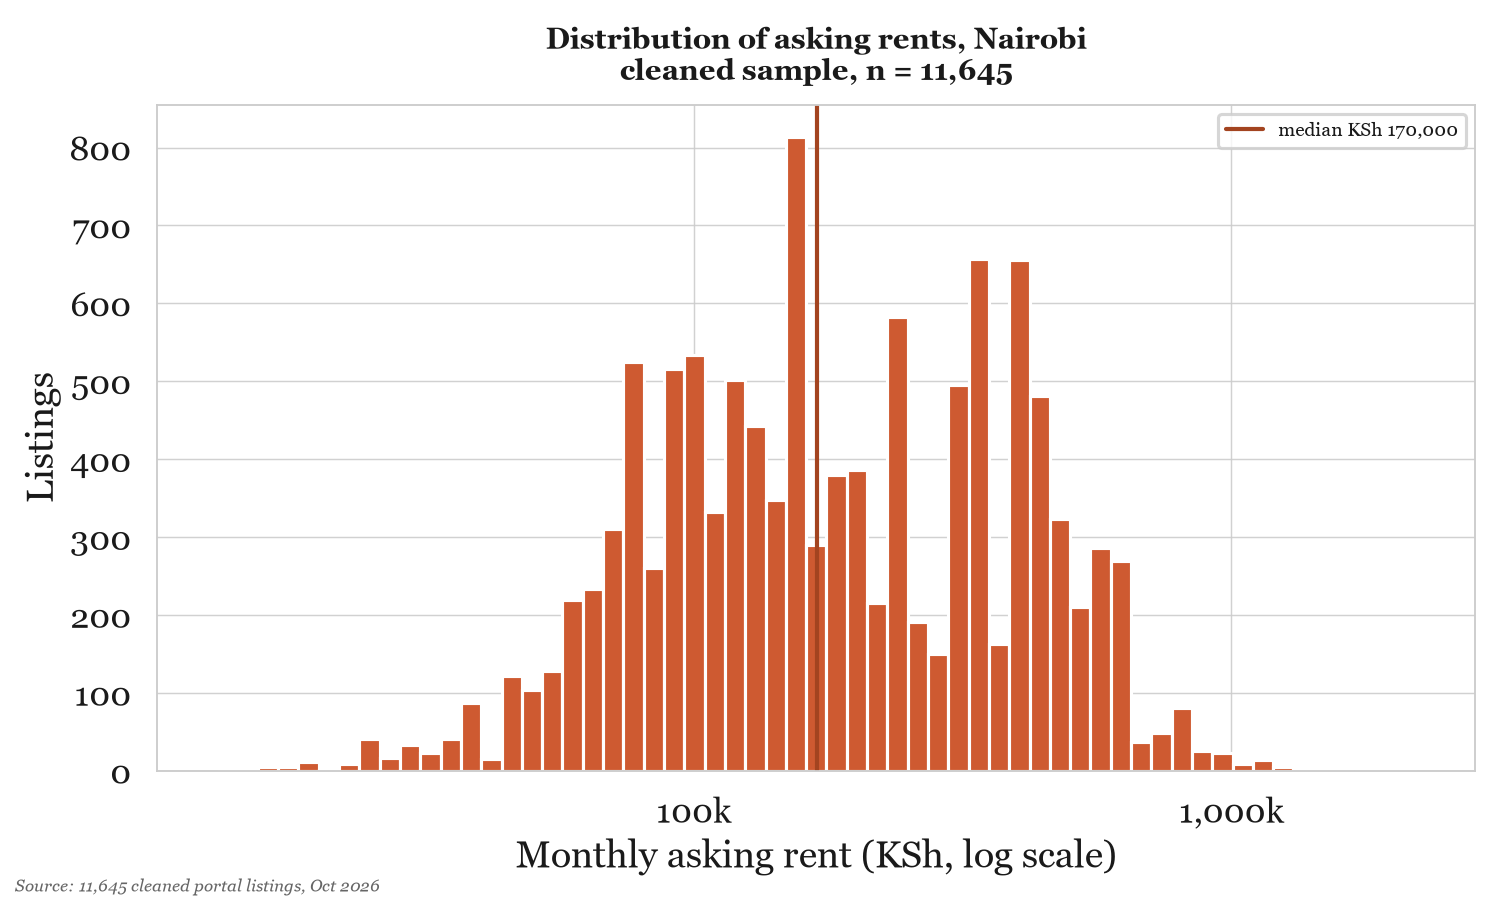

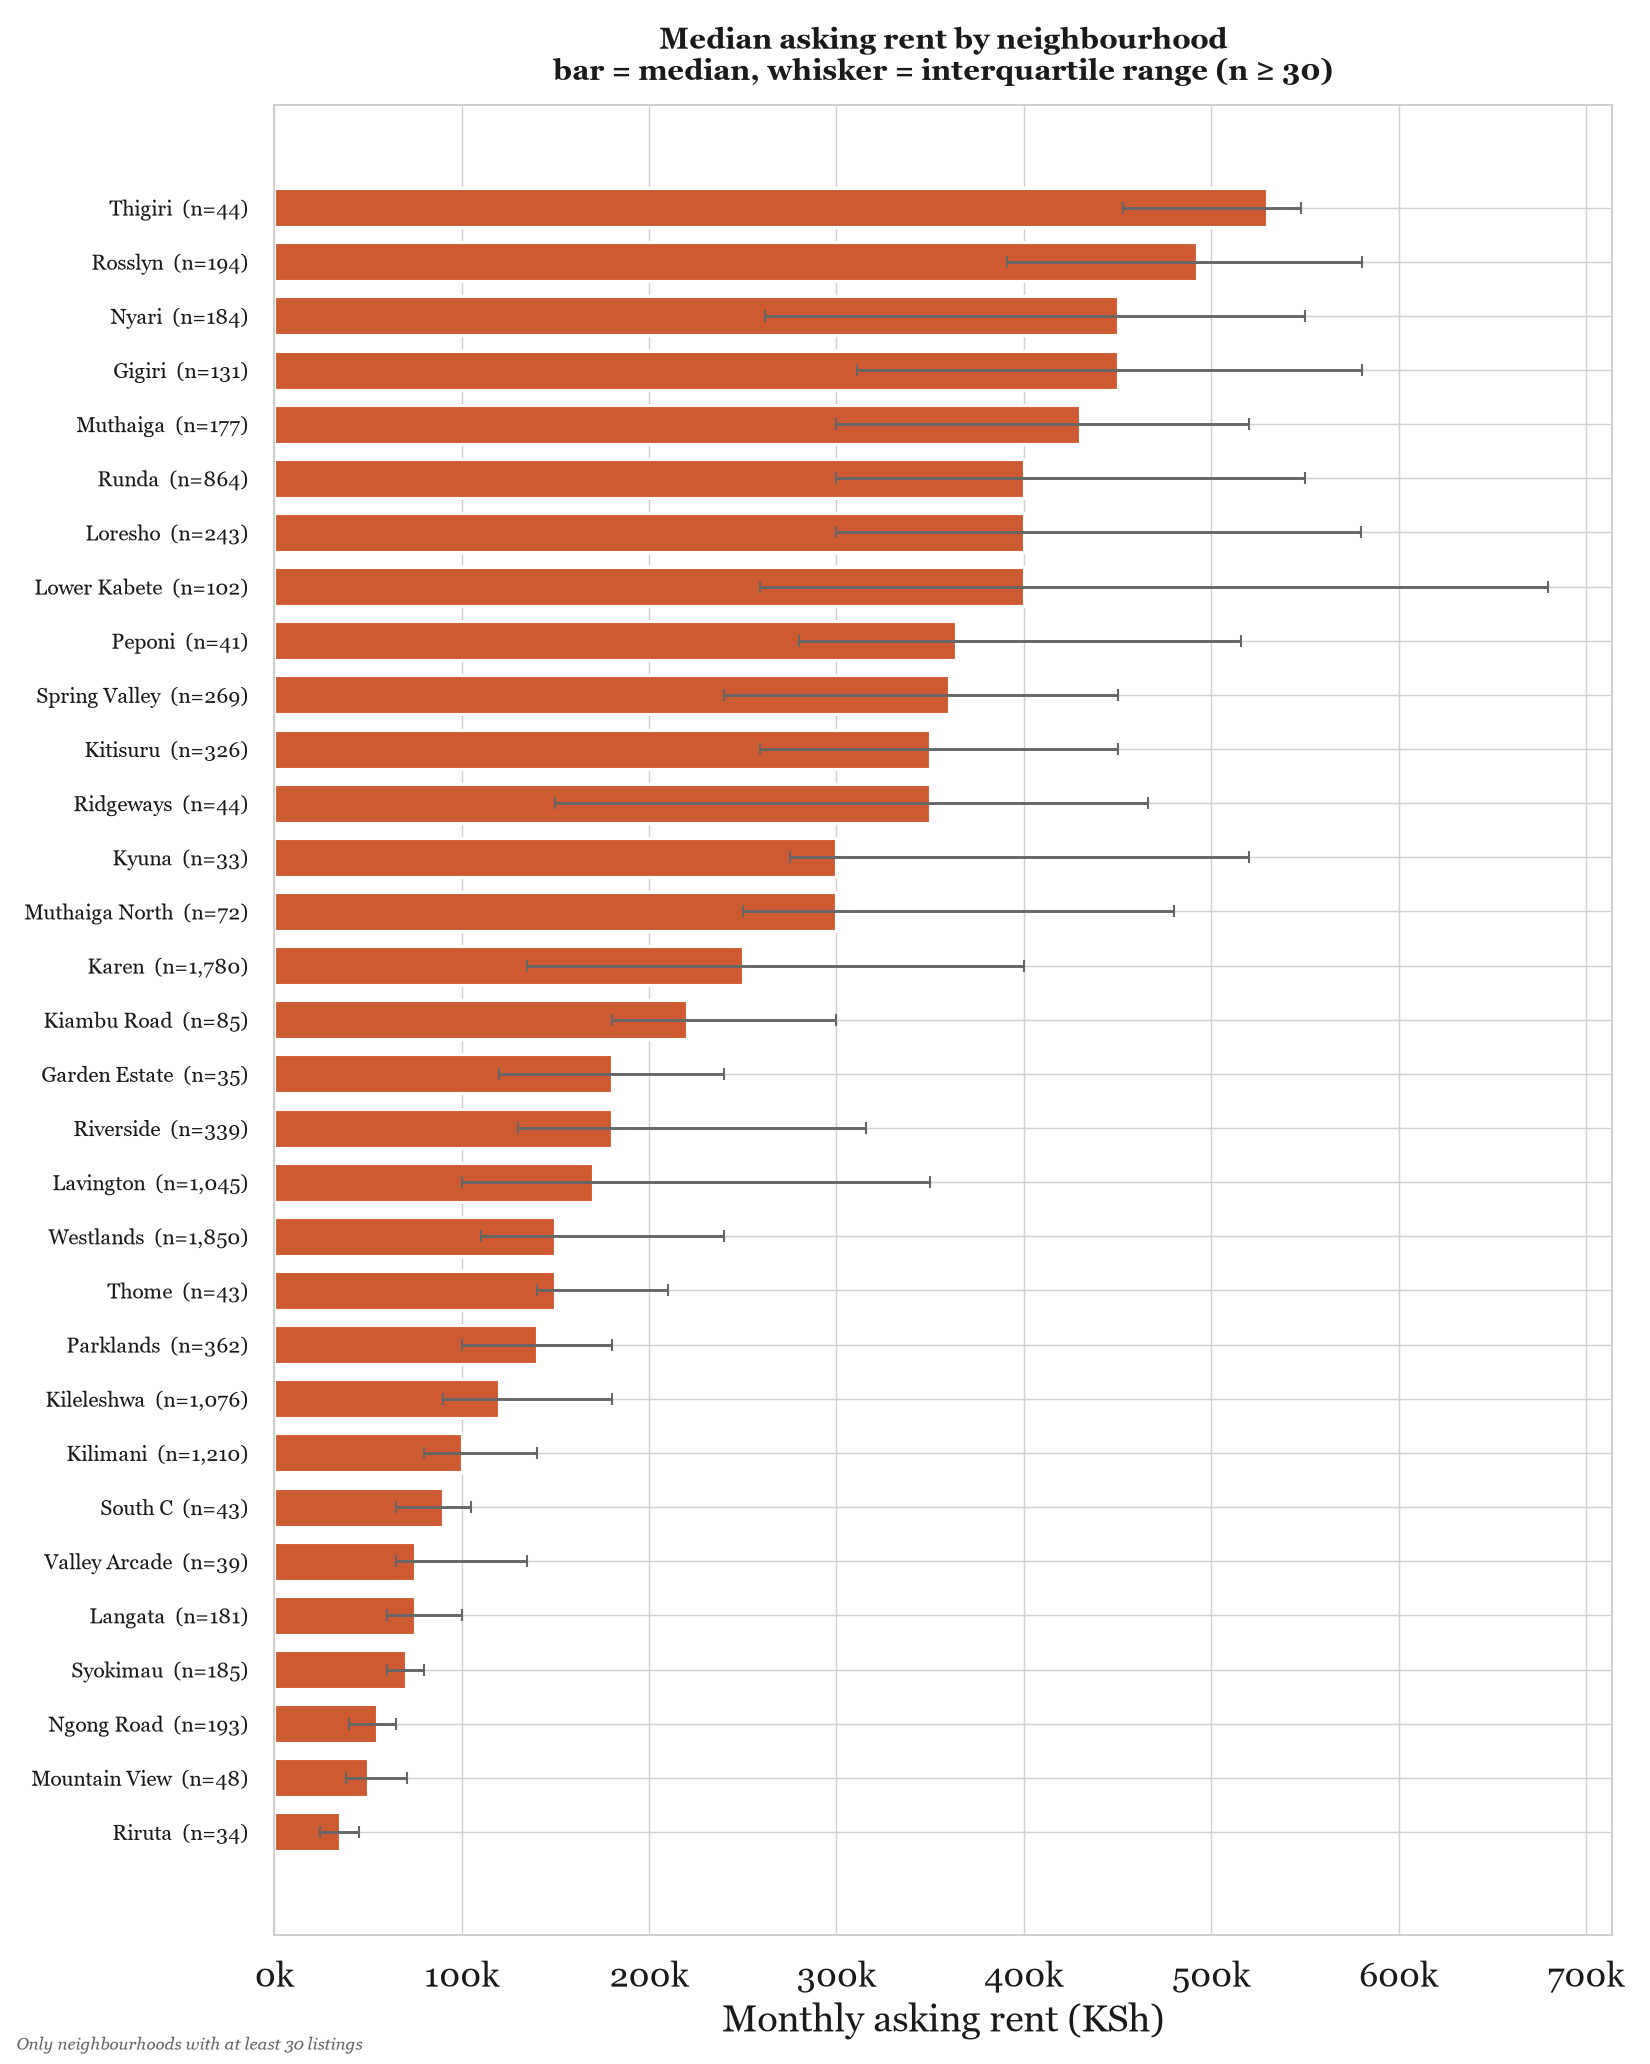

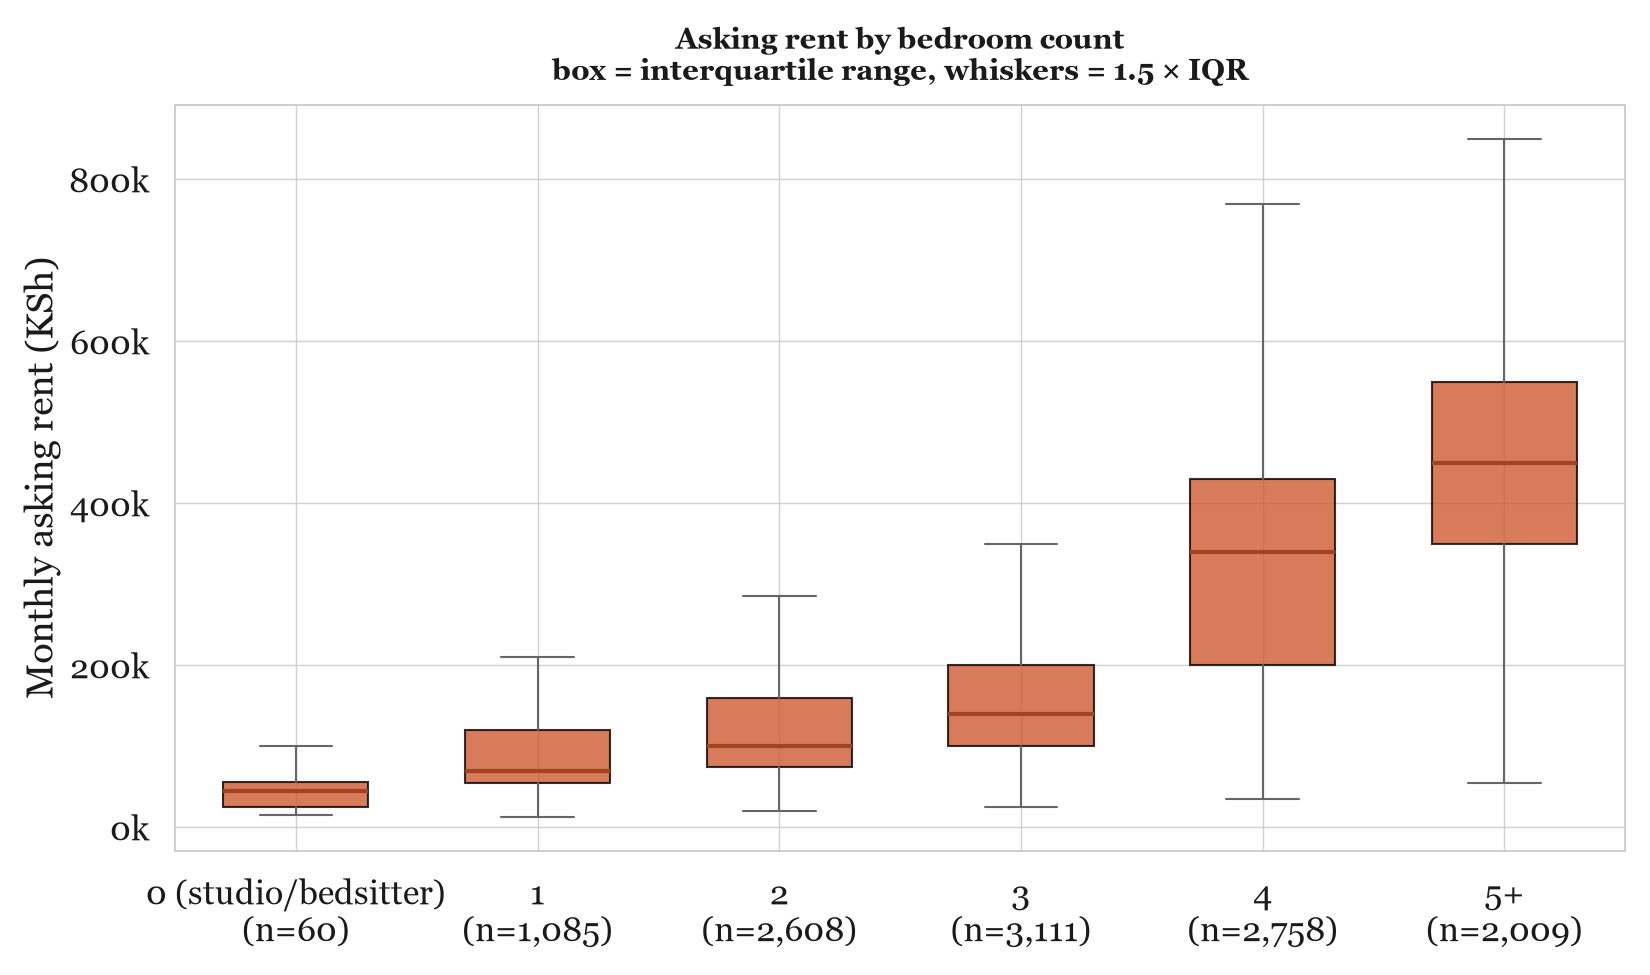

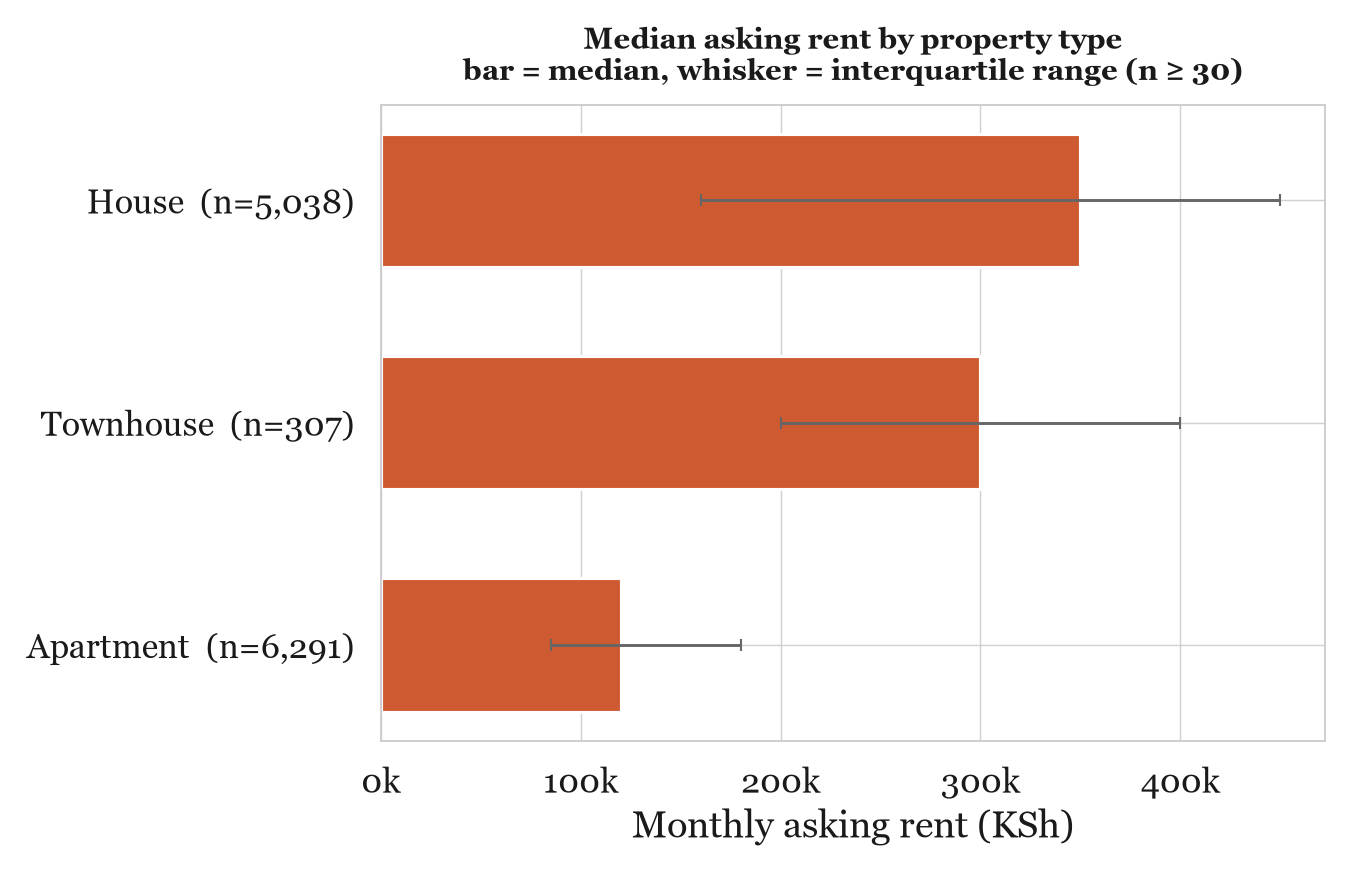

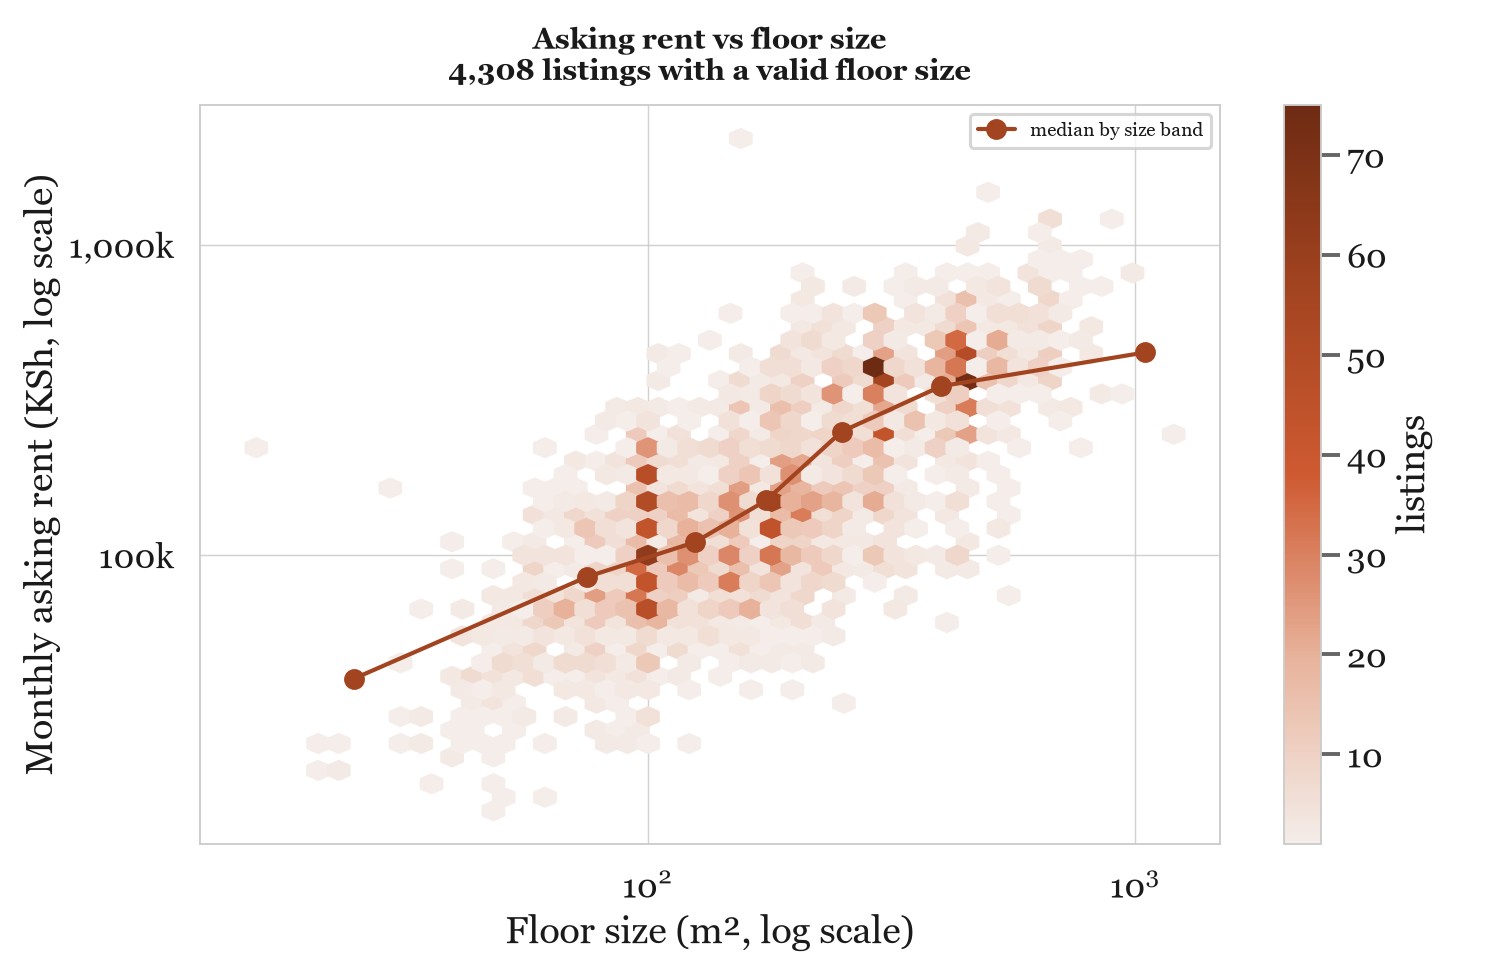

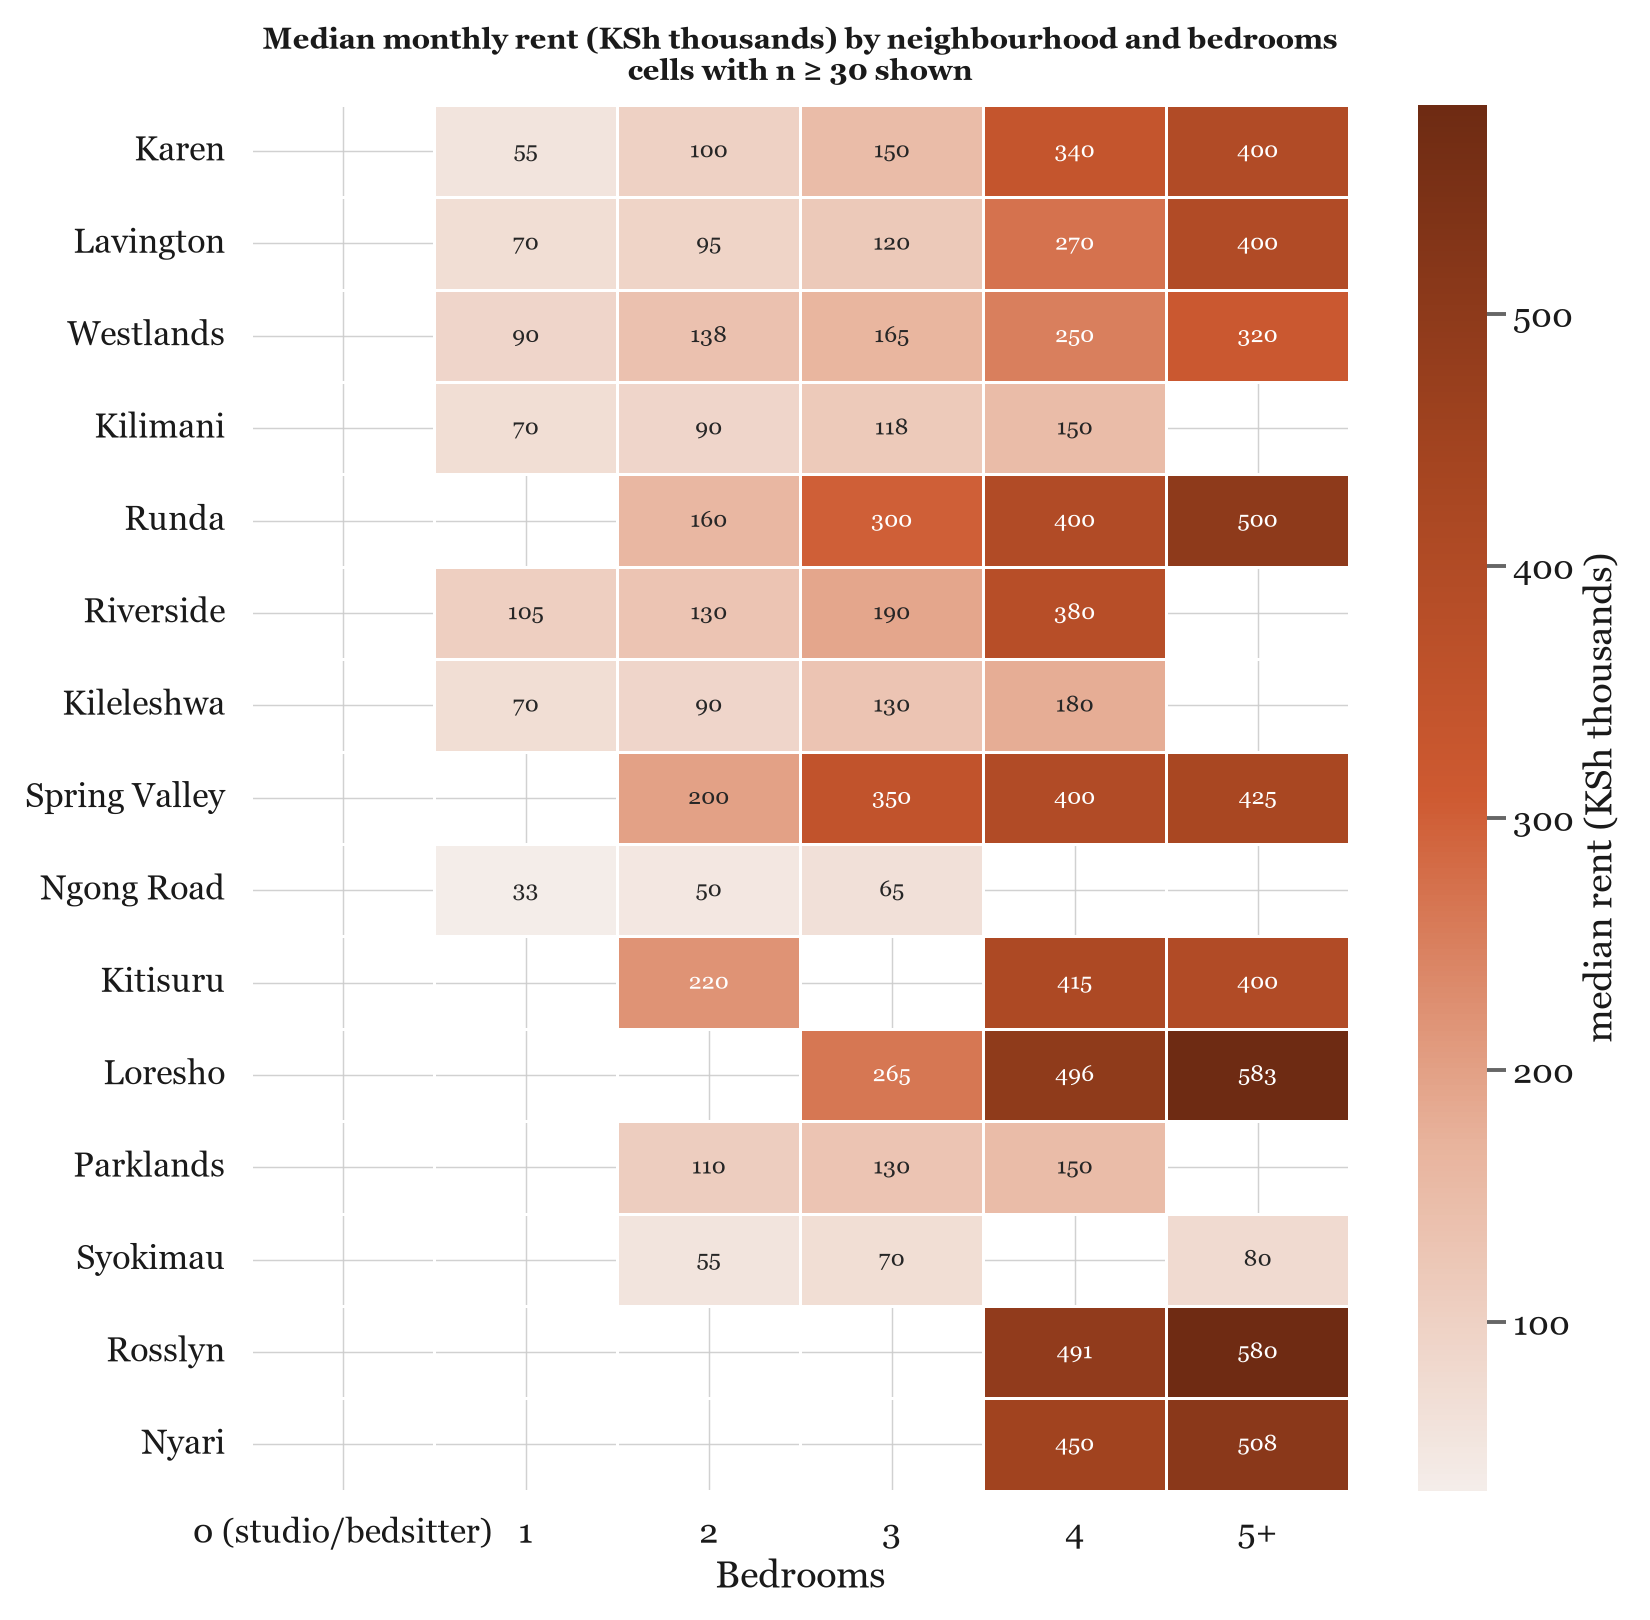

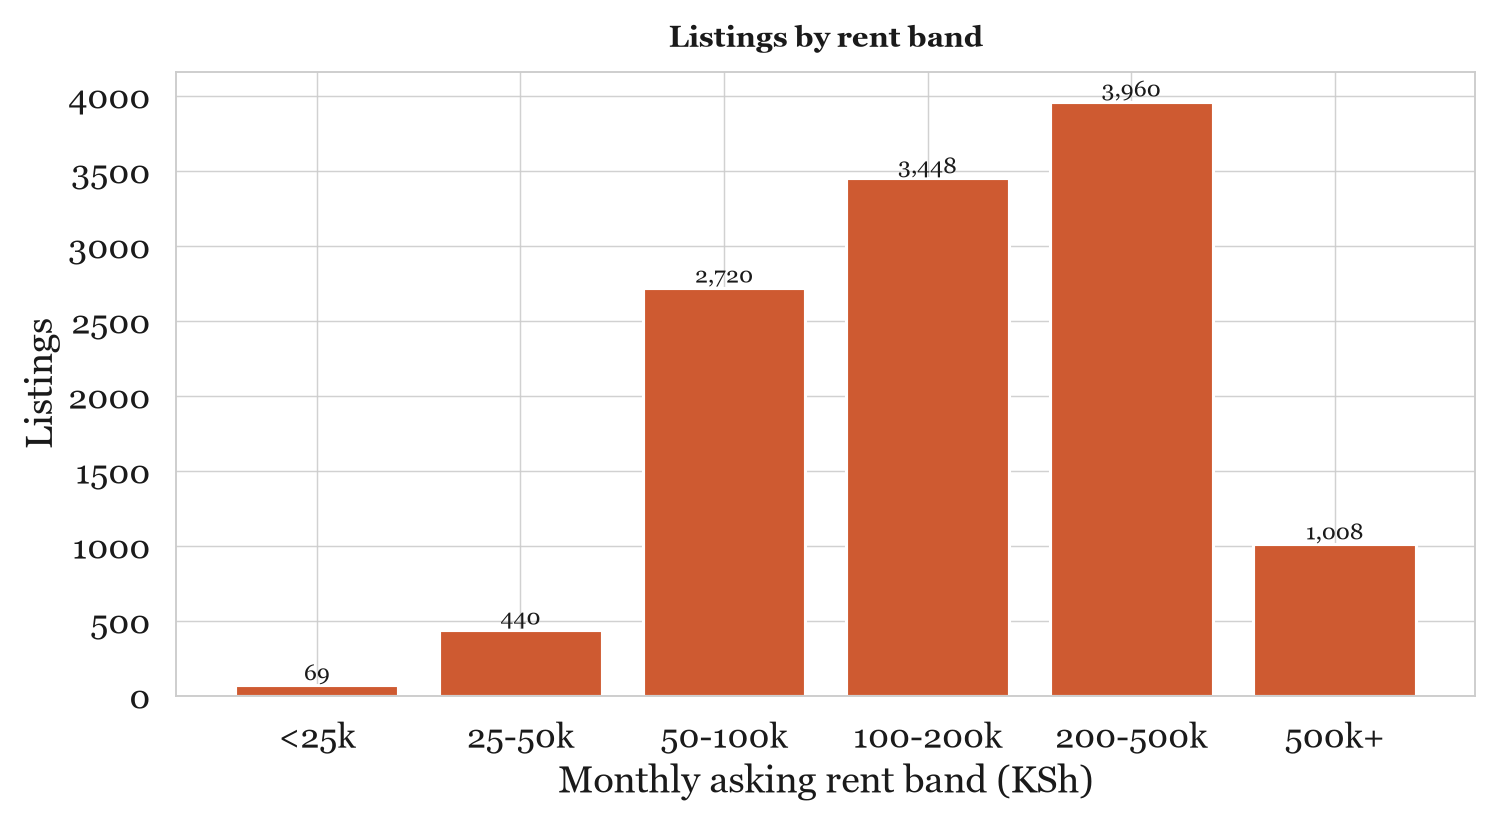

In [10]:
from IPython.display import Image, display

for name in ["fig_rent_distribution", "fig_rent_by_neighborhood",
             "fig_rent_by_bedrooms", "fig_rent_by_property_type",
             "fig_rent_vs_size", "fig_neighborhood_heatmap",
             "fig_price_bands"]:
    display(Image(filename=ROOT / "reports" / "figures" / f"{name}.png"))

## 4. Modelling (RQ2 and RQ3)

Leakage control: de-duplication before the split, imputation fitted inside each
training fold, and five out-of-fold folds for the value measures. Shilling
errors include Duan's smearing correction.

The predictive model is a blend of four small histogram gradient-boosted
models: two global (squared and absolute loss) and two structure-split models.
No grid search, no larger algorithm.

In [11]:
from __future__ import annotations

import argparse
import json
import platform
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.stats as st
import seaborn as sns
import shap
import sklearn
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (adjusted_rand_score, mean_absolute_error,
                             mean_squared_error, r2_score, silhouette_score)
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# --------------------------------------------------------------------------
# Protocol constants
# --------------------------------------------------------------------------
SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
MIN_N_NEIGHBORHOOD = 30    # neighbourhoods below this are pooled for modelling
MIN_N_GROUP_ERROR = 10     # minimum out-of-fold rows for an error-breakdown row
RANDOM_STATES = [0, 1, 2, 3, 4]

CORE_NUMERIC = ["bedrooms", "bathrooms", "parking", "size_sqm"]

AMENITIES = [
    "is_furnished", "has_dsq", "has_pool", "has_gym", "has_lift",
    "has_generator", "has_borehole", "is_ensuite", "has_garden",
    "has_balcony", "has_security",
]

# Keyword flags produced by rule C8 from the card text.
CARD_KEYWORDS = [
    "kw_penthouse", "kw_duplex", "kw_maisonette", "kw_villa", "kw_bungalow",
    "kw_jacuzzi", "kw_study", "kw_fireplace", "kw_servant_quarter",
    "kw_gated", "kw_serviced", "kw_newly_built", "kw_modern", "kw_spacious",
    "kw_luxury", "kw_cctv", "kw_all_ensuite", "kw_multi_parking",
    "kw_high_floor", "kw_off_plan",
]
STREET_MIN_ROWS = 40      # streets seen fewer times are pooled
BOOST_PARAMS = dict(
    learning_rate=0.06, max_leaf_nodes=127, min_samples_leaf=5,
    l2_regularization=2.0, max_iter=400, early_stopping=True,
    validation_fraction=0.1, n_iter_no_change=20, random_state=SEED,
)
BOOST_WEIGHTS = {"segment_squared": 0.4, "global_squared": 0.3,
                 "global_absolute": 0.3}

# Human-readable feature labels for charts and tables.
FRIENDLY = {
    "bedrooms": "Bedrooms",
    "bathrooms": "Bathrooms",
    "parking": "Parking spaces",
    "size_sqm": "Floor size (m²)",
    "bathrooms_missing": "Bathrooms not stated",
    "parking_missing": "Parking not stated",
    "size_missing": "Floor size not stated",
    "is_furnished": "Furnished / serviced",
    "has_dsq": "Staff quarters (DSQ)",
    "has_pool": "Swimming pool",
    "has_gym": "Gym",
    "has_lift": "Lift",
    "has_generator": "Backup generator",
    "has_borehole": "Borehole",
    "is_ensuite": "All en-suite",
    "has_garden": "Garden",
    "has_balcony": "Balcony / terrace",
    "has_security": "Gated / 24-hour security",
}


def friendly(feature: str) -> str:
    if feature in FRIENDLY:
        return FRIENDLY[feature]
    if feature.startswith("kw_"):
        return "Text: " + feature[3:].replace("_", " ")
    if feature.startswith("st_"):
        return "Street: " + feature[3:].replace("_", " ").title()
    if feature.startswith("fk_"):
        return "Detailed type: " + feature[3:].replace("_", " ").title()
    if feature.startswith("nb_other_neighborhood"):
        return "Other neighbourhoods (pooled)"
    if feature.startswith("nb_"):
        return "Neighbourhood: " + feature[3:].replace("_", " ").title()
    if feature.startswith("kind_"):
        return "Type: " + feature[5:].replace("_", " ").title()
    if feature == "_apt":
        return "Apartment segment"
    return feature.replace("_", " ").capitalize()


# --------------------------------------------------------------------------
# Fold-internal imputation (no leakage)
# --------------------------------------------------------------------------

class FoldImputer(BaseEstimator, TransformerMixin):
    """Fold-internal imputation of the numeric design columns.

    * `size_sqm` and `bathrooms`: median for that bedroom count, fitted on the
      training fold only;
    * `parking`: zero, because "not stated" is not "no parking" and the design
      matrix already carries `parking_missing`.

    Fitted inside a Pipeline, so statistics never include validation rows.
    """

    def __init__(self, bed_col: str = "bedrooms"):
        self.bed_col = bed_col

    def fit(self, X: pd.DataFrame, y=None):
        frame = pd.DataFrame(X)
        self.medians_ = {}
        for col in ("size_sqm", "bathrooms"):
            if col not in frame.columns:
                continue
            med = frame.groupby(self.bed_col)[col].median()
            global_med = float(frame[col].median())
            if not np.isfinite(global_med):
                global_med = 0.0
            self.medians_[col] = med.fillna(global_med).to_dict()
            self.medians_[col]["__global__"] = global_med
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        frame = pd.DataFrame(X).copy()
        for col, med in self.medians_.items():
            if col not in frame.columns:
                continue
            fill = frame[self.bed_col].map(med).fillna(med["__global__"])
            frame[col] = frame[col].fillna(fill)
        if "parking" in frame.columns:
            frame["parking"] = frame["parking"].fillna(0.0)
        return frame


# --------------------------------------------------------------------------
# Frame preparation
# --------------------------------------------------------------------------

def prepare_frame(df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Rows usable for modelling + a log of every decision."""
    notes: dict[str, object] = {}
    n0 = len(df)

    missing_beds = df["bedrooms"].isna()
    df = df[~missing_beds].copy()
    notes["dropped_missing_bedrooms"] = int(missing_beds.sum())

    counts = df["neighborhood"].value_counts()
    rare = set(counts[counts < MIN_N_NEIGHBORHOOD].index)
    df["neighborhood_model"] = df["neighborhood"].where(
        ~df["neighborhood"].isin(rare), "other_neighborhood")
    notes["pooled_neighborhoods"] = sorted(rare)
    notes["pooled_rows"] = int(df["neighborhood"].isin(rare).sum())
    notes["rows_used"] = int(len(df))
    notes["rows_in"] = int(n0)
    return df, notes


def category_levels(df: pd.DataFrame) -> dict[str, list[str]]:
    """Fixed dummy levels so train/test and subsets share columns."""
    street_counts = df["street"].astype(str).value_counts()
    streets = sorted(street_counts[street_counts >= STREET_MIN_ROWS].index)
    if "unknown" not in streets:
        streets.append("unknown")
    return {
        "kind_group": sorted(df["kind_group"].astype(str).unique()),
        "neighborhood_model": sorted(
            df["neighborhood_model"].astype(str).unique()),
        "kind": sorted(df["kind"].astype(str).unique()),
        "street": streets,
    }


def design_matrix(df: pd.DataFrame,
                  categories: dict | None = None,
                  include_neighborhood: bool = True,
                  include_amenities: bool = True,
                  include_kind: bool = True,
                  include_extra: bool = False,
                  include_street: bool = True
                  ) -> tuple[pd.DataFrame, pd.Series]:
    """Design matrix shared by the linear and boosting models.

    The returned frame holds raw `size_sqm` (NaNs preserved); imputation is a
    Pipeline step so it is fitted per training fold. `include_extra` adds the
    cheap C8 signals the boosted model uses: card-text keyword flags, detailed
    property kind, and a street token.
    """
    X = pd.DataFrame(index=df.index)
    for col in CORE_NUMERIC:
        X[col] = pd.to_numeric(df[col], errors="coerce").astype(float)

    # Missingness indicators are computed from the data, not fitted.
    X["bathrooms_missing"] = df["bathrooms"].isna().astype(float)
    X["parking_missing"] = df["parking"].isna().astype(float)
    X["size_missing"] = df["size_sqm"].isna().astype(float)

    if include_amenities:
        for name in AMENITIES:
            X[name] = df[name].astype(float)

    if include_kind:
        levels = (categories["kind_group"] if categories
                  else sorted(df["kind_group"].astype(str).unique()))
        cols = [f"kind_{c}" for c in levels if c != "house"]
        dummies = pd.get_dummies(df["kind_group"], prefix="kind", dtype=float)
        X = pd.concat([X, dummies.reindex(columns=cols, fill_value=0.0)], axis=1)

    if include_neighborhood:
        levels = (categories["neighborhood_model"] if categories
                  else sorted(df["neighborhood_model"].astype(str).unique()))
        cols = [f"nb_{c}" for c in levels if c != "westlands"]
        dummies = pd.get_dummies(df["neighborhood_model"], prefix="nb",
                                 dtype=float)
        X = pd.concat([X, dummies.reindex(columns=cols, fill_value=0.0)], axis=1)

    if include_extra:
        for name in CARD_KEYWORDS:
            X[name] = df[name].astype(float)
        X["kw_count"] = df["kw_count"].astype(float)

        kind_levels = (categories["kind"] if categories
                       else sorted(df["kind"].astype(str).unique()))
        kind_cols = [f"fk_{c}" for c in kind_levels if c != "house"]
        kind = pd.get_dummies(df["kind"].astype(str), prefix="fk", dtype=float)
        X = pd.concat([X, kind.reindex(columns=kind_cols, fill_value=0.0)],
                      axis=1)

        if include_street:
            street_levels = (categories["street"] if categories
                             else sorted(df["street"].astype(str).unique()))
            street_cols = [f"st_{s}" for s in street_levels if s != "unknown"]
            street = pd.get_dummies(df["street"].astype(str), prefix="st",
                                    dtype=float)
            X = pd.concat([X, street.reindex(columns=street_cols,
                                             fill_value=0.0)], axis=1)

        # Structural segment used to route the split model.
        X["_apt"] = df["kind_group"].isin(
            ["apartment", "bedsitter"]).astype(float)

    y = df["log_rent"].astype(float)
    return X, y


def make_pipeline(model, index: pd.Index) -> Pipeline:
    """Impute size by bedroom-band median, then fit the model."""
    return Pipeline([("fold_imputer", FoldImputer()), ("model", model)])


# --------------------------------------------------------------------------
# Metrics with Duan's smearing correction
# --------------------------------------------------------------------------

def smearing_factor(y_log: np.ndarray, pred_log: np.ndarray) -> float:
    """Duan's smearing estimator: mean(exp(residual)) on the training fit."""
    resid = np.asarray(y_log, float) - np.asarray(pred_log, float)
    return float(np.mean(np.exp(resid)))


def metrics(y_true_log, y_pred_log, smear: float = 1.0) -> dict:
    """Error on the log scale (modelling) and in shillings (reporting).

    `smear` is Duan's factor fitted on the training data; applying it removes
    the systematic downward bias of naive exp() back-transformation.
    """
    y_true_log = np.asarray(y_true_log, dtype=float)
    y_pred_log = np.asarray(y_pred_log, dtype=float)
    actual = np.exp(y_true_log)
    pred = np.exp(y_pred_log) * smear
    return {
        "rmse_log": float(np.sqrt(mean_squared_error(y_true_log, y_pred_log))),
        "mae_log": float(mean_absolute_error(y_true_log, y_pred_log)),
        "r2_log": float(r2_score(y_true_log, y_pred_log)),
        "rmse_ksh": float(np.sqrt(mean_squared_error(actual, pred))),
        "mae_ksh": float(mean_absolute_error(actual, pred)),
        "r2_ksh": float(r2_score(actual, pred)),
        "mape_pct": float(np.mean(np.abs(actual - pred) / actual) * 100),
        "mdape_pct": float(np.median(np.abs(actual - pred) / actual) * 100),
        "n": int(len(y_true_log)),
        "smearing_factor": float(smear),
    }


# --------------------------------------------------------------------------
# Explanatory model: OLS with robust (HC1) standard errors
# --------------------------------------------------------------------------

def ols_hc1(X: pd.DataFrame, y: pd.Series) -> pd.DataFrame:
    """OLS coefficients with heteroskedasticity-robust (HC1) standard errors."""
    Xm = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    yv = y.to_numpy(dtype=float)
    n, k = Xm.shape
    beta, *_ = np.linalg.lstsq(Xm, yv, rcond=None)
    resid = yv - Xm @ beta
    xtx_inv = np.linalg.pinv(Xm.T @ Xm)
    meat = Xm.T @ (Xm * (resid ** 2)[:, None])
    cov = xtx_inv @ meat @ xtx_inv * (n / (n - k))
    se = np.sqrt(np.diag(cov))
    dof = n - k
    tstat = beta / se
    pval = 2 * st.t.sf(np.abs(tstat), dof)
    tcrit = st.t.ppf(0.975, dof)
    lo, hi = beta - tcrit * se, beta + tcrit * se

    table = pd.DataFrame({
        "term": ["intercept"] + list(X.columns),
        "coef_log": beta,
        "robust_se": se,
        "t": tstat,
        "p_value": pval,
        "ci95_low_log": lo,
        "ci95_high_log": hi,
    })
    table["pct_effect"] = (np.exp(table["coef_log"]) - 1) * 100
    table["pct_ci95_low"] = (np.exp(table["ci95_low_log"]) - 1) * 100
    table["pct_ci95_high"] = (np.exp(table["ci95_high_log"]) - 1) * 100
    table["label"] = table["term"].map(
        lambda t: "Intercept" if t == "intercept" else friendly(t))
    table.attrs["n"] = n
    table.attrs["r2"] = float(r2_score(yv, Xm @ beta))
    return table


# --------------------------------------------------------------------------
# Predictive model: a small, fast boosted-tree blend
# --------------------------------------------------------------------------

class BoostBlend(BaseEstimator, RegressorMixin):
    """Four histogram gradient-boosted models, averaged.

    Two global models (squared and absolute loss on log rent) and two
    structure-split models (apartments/bedsitters vs houses/townhouses,
    squared loss). All are small, fast and trained inside the same fold.
    Squared loss protects the shilling-scale fit; absolute loss sharpens the
    typical percentage error.

    The split is a plain two-way rule on `kind_group` carried as `_apt`, so the
    estimator works with `cross_val_predict` and cannot leak across folds.
    """

    def __init__(self, params: dict | None = None,
                 weights: dict | None = None):
        self.params = params
        self.weights = weights

    def _model(self, loss: str) -> Pipeline:
        params = dict(BOOST_PARAMS if self.params is None else self.params)
        return Pipeline([
            ("fold_imputer", FoldImputer()),
            ("model", HistGradientBoostingRegressor(loss=loss, **params)),
        ])

    def fit(self, X: pd.DataFrame, y: pd.Series):
        self.global_squared_ = self._model("squared_error").fit(X, y)
        self.global_absolute_ = self._model("absolute_error").fit(X, y)

        seg = X["_apt"].to_numpy().astype(bool)
        self.segment_models_ = {}
        for label, mask in (("apartment", seg), ("house", ~seg)):
            if mask.sum() >= 100:
                self.segment_models_[label] = self._model("squared_error") \
                    .fit(X[mask], y[mask])
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        weights = dict(BOOST_WEIGHTS if self.weights is None else self.weights)
        pred = (weights["global_squared"] * self.global_squared_.predict(X)
                + weights["global_absolute"] * self.global_absolute_.predict(X))

        seg = X["_apt"].to_numpy().astype(bool)
        seg_pred = np.empty(len(X), dtype=float)
        for label, mask in (("apartment", seg), ("house", ~seg)):
            model = self.segment_models_.get(label)
            if model is None:
                seg_pred[mask] = self.global_squared_.predict(X[mask])
            else:
                seg_pred[mask] = model.predict(X[mask])
        return pred + weights["segment_squared"] * seg_pred


def fit_boost(X_train: pd.DataFrame, y_train: pd.Series,
              verbose: bool = True) -> tuple[BoostBlend, dict]:
    """Fit the blend with fixed, pre-declared parameters."""
    model = BoostBlend().fit(X_train, y_train)
    if verbose:
        print(f"  Boost blend: {BOOST_WEIGHTS} "
              f"({len(model.segment_models_)} structure models)")
    return model, {
        "params": {k: v for k, v in BOOST_PARAMS.items()},
        "weights": dict(BOOST_WEIGHTS),
        "n_models": 2 + len(model.segment_models_),
    }


# --------------------------------------------------------------------------
# Segmentation
# --------------------------------------------------------------------------

def cluster_features(df: pd.DataFrame) -> pd.DataFrame:
    """Rent, size and location features for segmentation.

    Descriptive clustering by design, so rent itself is a feature here. Size is
    imputed with the sample median by bedroom band, which is acceptable because
    no target model is trained on this frame.
    """
    size = df["size_sqm"].fillna(
        df.groupby("bedrooms")["size_sqm"].transform("median"))
    return pd.DataFrame({
        "log_rent": df["log_rent"].astype(float),
        "bedrooms": df["bedrooms"].astype(float),
        "size_sqm": size,
        "location_premium": df["neighborhood"].map(
            df.groupby("neighborhood")["log_rent"].median()),
    }).fillna(df["log_rent"].median())


def choose_k(X: pd.DataFrame, ks: range = range(2, 11)) -> pd.DataFrame:
    """Elbow (inertia) and silhouette for k = 2..10."""
    Xs = StandardScaler().fit_transform(X)
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
        labels = km.fit_predict(Xs)
        sil = silhouette_score(Xs, labels, sample_size=4000, random_state=SEED)
        rows.append({"k": k, "inertia": float(km.inertia_),
                     "silhouette": float(sil)})
    return pd.DataFrame(rows)


def stability_ari(X: pd.DataFrame, k: int) -> dict:
    """Segment stability across random seeds."""
    Xs = StandardScaler().fit_transform(X)
    runs = []
    for rs in RANDOM_STATES:
        runs.append(KMeans(n_clusters=k, n_init=10,
                           random_state=rs).fit_predict(Xs))
    aris = [adjusted_rand_score(runs[0], r) for r in runs[1:]]
    return {"k": k, "runs": len(runs),
            "mean_ari_vs_seed0": float(np.mean(aris)),
            "min_ari_vs_seed0": float(np.min(aris))}


def cluster_profiles(df: pd.DataFrame, labels: np.ndarray) -> pd.DataFrame:
    """Plain-language cluster profiles."""
    work = df.copy()
    work["cluster"] = labels
    rows = []
    for c, sub in work.groupby("cluster"):
        top_nb = sub["neighborhood"].value_counts().head(3)
        rows.append({
            "cluster": int(c),
            "n": int(len(sub)),
            "share_pct": round(100 * len(sub) / len(work), 1),
            "median_rent": float(sub["price_kes"].median()),
            "p25_rent": float(sub["price_kes"].quantile(0.25)),
            "p75_rent": float(sub["price_kes"].quantile(0.75)),
            "median_bedrooms": float(sub["bedrooms"].median()),
            "median_size_sqm": float(sub["size_sqm"].median()),
            "size_present_pct": round(100 * sub["size_sqm"].notna().mean(), 1),
            "top_neighborhoods": ", ".join(
                f"{i} ({n})" for i, n in top_nb.items()),
            "kind_mix": ", ".join(
                f"{i} {round(100 * v / len(sub))}%"
                for i, v in sub["kind_group"].value_counts().head(3).items()),
        })
    return pd.DataFrame(rows).sort_values("median_rent").reset_index(drop=True)


# --------------------------------------------------------------------------
# Value measures (both from out-of-fold predictions)
# --------------------------------------------------------------------------

def value_frames(df: pd.DataFrame,
                 structural_pred_log: np.ndarray,
                 full_pred_log: np.ndarray,
                 structural_smear: float) -> pd.DataFrame:
    """Two pre-declared value measures, per listing.

    (1) structural_value: actual rent / (rent expected from structure alone,
        city-wide) - 1. Negative means the dwelling is cheaper than the city
        norm for that structure, i.e. more dwelling per shilling.

    (2) full_value: actual rent / (rent expected from the full model, which
        also knows the neighbourhood) - 1. Negative means cheaper than other
        listings in the same area with the same attributes.
    """
    out = df[["neighborhood", "price_kes", "bedroom_band", "kind_group",
              "bedrooms", "size_sqm", "is_satellite_town"]].copy()
    out["structural_expected_rent"] = np.exp(structural_pred_log) * structural_smear
    out["full_expected_rent"] = np.exp(full_pred_log)
    out["structural_value"] = out["price_kes"] / out["structural_expected_rent"] - 1.0
    out["full_value"] = out["price_kes"] / out["full_expected_rent"] - 1.0
    return out


def value_by_neighborhood(value: pd.DataFrame,
                          min_n: int = MIN_N_NEIGHBORHOOD) -> pd.DataFrame:
    rows = []
    for nb, sub in value.groupby("neighborhood"):
        rows.append({
            "neighborhood": nb,
            "n": int(len(sub)),
            "reported": len(sub) >= min_n,
            "is_satellite_town": bool(sub["is_satellite_town"].iloc[0]),
            "median_structural_value": float(sub["structural_value"].median()),
            "pct_structurally_cheap": float(
                100 * (sub["structural_value"] < -0.15).mean()),
            "median_full_value": float(sub["full_value"].median()),
            "pct_bargain_in_area": float(
                100 * (sub["full_value"] < -0.15).mean()),
            "median_actual_rent": float(sub["price_kes"].median()),
            "median_structural_expected": float(
                sub["structural_expected_rent"].median()),
        })
    out = pd.DataFrame(rows)
    # Best value = most negative structural value (most dwelling per shilling).
    return out.sort_values("median_structural_value").reset_index(drop=True)


# --------------------------------------------------------------------------
# Error breakdowns
# --------------------------------------------------------------------------

def error_breakdown(df: pd.DataFrame, y_true_log, pred_log: dict[str, np.ndarray],
                    group_col: str, smears: dict[str, float],
                    min_n: int = MIN_N_GROUP_ERROR) -> pd.DataFrame:
    actual = np.exp(np.asarray(y_true_log, dtype=float))
    rows = []
    groups = df[group_col].astype(str)
    for g in groups.unique():
        mask = (groups == g).to_numpy()
        if mask.sum() < min_n:
            continue
        row = {"group": g, "dimension": group_col, "n": int(mask.sum())}
        for model, pred in pred_log.items():
            p = np.exp(np.asarray(pred, dtype=float))[mask] * smears.get(model, 1.0)
            a = actual[mask]
            row[f"{model}_rmse_ksh"] = float(np.sqrt(mean_squared_error(a, p)))
            row[f"{model}_mae_ksh"] = float(mean_absolute_error(a, p))
            row[f"{model}_mape_pct"] = float(
                np.mean(np.abs(a - p) / a) * 100)
        rows.append(row)
    out = pd.DataFrame(rows)
    if len(out):
        first = list(pred_log)[0]
        out = out.sort_values(f"{first}_mape_pct").reset_index(drop=True)
    return out


# --------------------------------------------------------------------------
# Figures
# --------------------------------------------------------------------------

def fig_predicted_vs_actual(y_true, preds: dict[str, np.ndarray],
                            smears: dict[str, float], out: Path) -> None:
    fig, axes = plt.subplots(1, len(preds), figsize=(6.5 * len(preds), 6),
                             sharex=True, sharey=True)
    if len(preds) == 1:
        axes = [axes]
    lims = [np.exp(y_true).min() * 0.7, np.exp(y_true).max() * 1.4]
    for ax, (name, pred) in zip(axes, preds.items()):
        a = np.exp(y_true)
        p = np.exp(pred) * smears.get(name, 1.0)
        ax.scatter(a, p, s=8, alpha=0.3, color=brand.PRIMARY, edgecolors="none")
        ax.plot(lims, lims, "--", color=brand.TEXT, lw=1.2,
                label="perfect prediction")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlim(lims); ax.set_ylim(lims)
        m = metrics(y_true, pred, smears.get(name, 1.0))
        ax.set_title(f"{name}\nRMSE KSh {m['rmse_ksh']:,.0f} | "
                     f"MAPE {m['mape_pct']:.1f}% | R² {m['r2_ksh']:.2f}",
                     fontsize=13)
        ax.set_xlabel("Actual rent (KSh)")
        ax.legend(frameon=True, fontsize=10)
    axes[0].set_ylabel("Predicted rent (KSh)")
    fig.suptitle("Held-out predictions vs actual asking rent", y=1.02)
    fig.tight_layout()
    fig.savefig(out, dpi=150, bbox_inches="tight")
    plt.close(fig)


def fig_shap(model: Pipeline, X: pd.DataFrame, out: Path,
             max_rows: int = 2000) -> pd.DataFrame:
    """SHAP beeswarm + mean |SHAP| table with human-readable labels."""
    # Apply the fitted imputer first so the explainer sees numeric values.
    X_imp = model.named_steps["fold_imputer"].transform(X)
    sample = X_imp.sample(min(max_rows, len(X_imp)), random_state=SEED)
    sample = sample.rename(columns={c: friendly(c) for c in sample.columns})
    est = model.named_steps["model"]
    explainer = shap.TreeExplainer(est)
    sv = explainer.shap_values(sample)

    shap.summary_plot(sv, sample, show=False, max_display=15,
                      plot_size=(11, 8), cmap=brand.diverging_cmap())
    plt.title("How each feature moves the rent prediction (SHAP)\n"
              "boosted blend (global model), mean |SHAP| ordering", fontsize=13,
              fontweight="bold")
    plt.xlabel("SHAP value: effect on log rent (0.10 ≈ +10%)")
    brand.enforce_fonts(plt.gcf())
    plt.tight_layout()
    plt.savefig(out, dpi=150, bbox_inches="tight")
    plt.close()

    importance = pd.DataFrame({
        "feature": list(X_imp.columns),
        "label": [friendly(c) for c in X_imp.columns],
        "mean_abs_shap": np.abs(sv).mean(axis=0),
    }).sort_values("mean_abs_shap", ascending=False)
    importance["share_pct"] = (
        100 * importance["mean_abs_shap"] / importance["mean_abs_shap"].sum())
    return importance.reset_index(drop=True)


def fig_k_selection(k_table: pd.DataFrame, out: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    axes[0].plot(k_table["k"], k_table["inertia"], "o-",
                 color=brand.PRIMARY)
    axes[0].set_xlabel("k (number of segments)"); axes[0].set_ylabel("Inertia")
    axes[0].set_title("Elbow")
    axes[1].plot(k_table["k"], k_table["silhouette"], "o-",
                 color=brand.PRIMARY)
    axes[1].set_xlabel("k (number of segments)"); axes[1].set_ylabel("Silhouette")
    axes[1].set_title("Silhouette (4,000-row sample)")
    fig.suptitle("Choosing the number of market segments")
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


def fig_value(value_nb: pd.DataFrame, out: Path,
              min_n: int = MIN_N_NEIGHBORHOOD) -> None:
    """Structural value by neighbourhood: more dwelling per shilling = left."""
    rep = value_nb[value_nb["reported"]].sort_values("median_structural_value")
    fig, ax = plt.subplots(figsize=(11, 0.38 * len(rep) + 2.8))
    colors = [brand.PRIMARY if v < 0 else brand.MUTED
              for v in rep["median_structural_value"]]
    y = np.arange(len(rep))
    ax.barh(y, rep["median_structural_value"] * 100, color=colors, height=0.7)
    ax.set_yticks(y, [f"{i.title()}  (n={int(n):,})"
                      for i, n in zip(rep["neighborhood"], rep["n"])],
                  fontsize=10)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Median structural value (%, actual vs structure-expected rent)")
    ax.set_title("Value for money by neighbourhood\n"
                 "negative = rent below the city norm for the same structure "
                 f"(n ≥ {min_n})", fontsize=13)
    fig.tight_layout()
    fig.savefig(out, dpi=150, bbox_inches="tight")
    plt.close(fig)


def fig_error_by_band(band_err: pd.DataFrame, out: Path) -> None:
    models = [c[:-9] for c in band_err.columns if c.endswith("_mape_pct")]
    order = ["<25k", "25-50k", "50-100k", "100-200k", "200-500k", "500k+"]
    band_err = band_err.set_index("group").reindex(order).dropna(how="all") \
        .reset_index()
    x = np.arange(len(band_err))
    width = 0.38
    fig, ax = plt.subplots(figsize=(11, 5.5))
    series_colors = [brand.MUTED, brand.PRIMARY]
    for i, m in enumerate(models):
        bars = ax.bar(x + (i - 0.5) * width, band_err[f"{m}_mape_pct"],
                      width, label=m.replace("_", " ").title(),
                      color=series_colors[i % len(series_colors)])
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
    ax.set_xticks(x, band_err["group"])
    ax.set_ylabel("MAPE (% of rent)")
    ax.set_title("Prediction error by rent band (out-of-fold)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out, dpi=150)
    plt.close(fig)


# --------------------------------------------------------------------------
# Driver
# --------------------------------------------------------------------------

def run(df_raw: pd.DataFrame, figdir: Path, tabledir: Path,
        verbose: bool = True) -> dict:
    """Full modelling pipeline. Returns a dict of artefacts + numbers."""
    tabledir.mkdir(parents=True, exist_ok=True)
    figdir.mkdir(parents=True, exist_ok=True)

    df, prep_notes = prepare_frame(df_raw)
    if verbose:
        print(f"Modelling frame: {prep_notes['rows_in']:,} -> "
              f"{prep_notes['rows_used']:,} rows "
              f"(missing bedrooms dropped: "
              f"{prep_notes['dropped_missing_bedrooms']}; pooled rare "
              f"neighbourhoods: {len(prep_notes['pooled_neighborhoods'])})")

    # ---- hold-out split after de-duplication ---------------------------
    idx = np.arange(len(df))
    tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE,
                                      random_state=SEED)
    train, test = df.iloc[tr_idx].copy(), df.iloc[te_idx].copy()
    cat_levels = category_levels(df)
    cv = KFold(CV_FOLDS, shuffle=True, random_state=SEED)

    # Linear model uses the interpretable set; the boosted blend also uses the
    # cheap C8 keyword, detailed-kind and street signals.
    X_lin_tr, y_tr = design_matrix(train, categories=cat_levels)
    X_lin_te, y_te = design_matrix(test, categories=cat_levels)
    X_tr, _ = design_matrix(train, categories=cat_levels, include_extra=True)
    X_te, _ = design_matrix(test, categories=cat_levels, include_extra=True)
    if verbose:
        print(f"  train {len(X_tr):,} | test {len(X_te):,} | "
              f"features linear {X_lin_tr.shape[1]} / boost {X_tr.shape[1]}")

    # ---- explanatory models ---------------------------------------------
    # OLS needs a complete numeric frame; the imputer is fitted on the
    # training split only (no leakage) and reused for the test frame.
    imputer = FoldImputer().fit(X_lin_tr)
    X_lin_tr_imp = imputer.transform(X_lin_tr)
    X_lin_te_imp = imputer.transform(X_lin_te)

    # Core hedonic set without the amenity indicators.
    Xc_tr, _ = design_matrix(train, categories=cat_levels,
                             include_amenities=False)
    Xc_te, _ = design_matrix(test, categories=cat_levels,
                             include_amenities=False)
    Xc_tr_imp = imputer.transform(Xc_tr)
    Xc_te_imp = imputer.transform(Xc_te)

    coef_core = ols_hc1(Xc_tr_imp, y_tr)
    coef_core.to_csv(tabledir / "model_linear_coefficients_core.csv", index=False)

    # Amenity-enriched set.
    coef_full = ols_hc1(X_lin_tr_imp, y_tr)
    coef_full.to_csv(tabledir / "model_linear_coefficients.csv", index=False)

    # ---- models on the held-out split -----------------------------------
    lin_pipe = make_pipeline(LinearRegression(), X_lin_tr.index)
    lin_pipe.fit(X_lin_tr, y_tr)
    gbm_pipe, gbm_info = fit_boost(X_tr, y_tr, verbose=verbose)

    pred_lin_te = lin_pipe.predict(X_lin_te)
    pred_gbm_te = gbm_pipe.predict(X_te)
    lin_smear = smearing_factor(y_tr, lin_pipe.predict(X_lin_tr))
    gbm_smear = smearing_factor(y_tr, gbm_pipe.predict(X_tr))

    feature_note = ("structure + amenities + text keywords + detailed kind + "
                    "street + neighbourhood")
    metrics_rows = []
    for name, pred, smear in [
            ("linear_baseline", pred_lin_te, lin_smear),
            ("gradient_boosting", pred_gbm_te, gbm_smear)]:
        m = metrics(y_te.to_numpy(), pred, smear)
        m.update({"model": name, "evaluation": "holdout_20pct",
                  "features": feature_note})
        metrics_rows.append(m)

    # 5-fold CV on the training split.
    cv_preds = {}
    for name, pipe, X_cv in [
            ("linear_baseline", make_pipeline(LinearRegression(),
                                              X_lin_tr.index), X_lin_tr),
            ("gradient_boosting", clone(gbm_pipe), X_tr)]:
        oof = cross_val_predict(clone(pipe), X_cv, y_tr, cv=cv, n_jobs=-1)
        cv_preds[name] = oof
        m = metrics(y_tr.to_numpy(), oof, 1.0)
        m.update({"model": name, "evaluation": f"{CV_FOLDS}fold_cv_train",
                  "features": feature_note})
        metrics_rows.append(m)

    metrics_tab = pd.DataFrame(metrics_rows)
    metrics_tab.to_csv(tabledir / "model_metrics.csv", index=False)

    # Core-feature linear baseline, for an honest "does enrichment help?" row.
    core_pipe = Pipeline([("model", LinearRegression())])
    core_pipe.fit(Xc_tr_imp, y_tr)
    core_pred = core_pipe.predict(Xc_te_imp)
    core_smear = smearing_factor(y_tr, core_pipe.predict(Xc_tr_imp))
    core_m = metrics(y_te.to_numpy(), core_pred, core_smear)
    core_m.update({"model": "linear_core_features", "evaluation": "holdout_20pct",
                   "features": "bedrooms, bathrooms, parking, size, kind, area"})
    metrics_tab = pd.concat([metrics_tab, pd.DataFrame([core_m])],
                            ignore_index=True)
    metrics_tab.to_csv(tabledir / "model_metrics.csv", index=False)

    lin_m = metrics_tab[(metrics_tab.model == "linear_baseline")
                        & (metrics_tab.evaluation == "holdout_20pct")].iloc[0]
    gbm_m = metrics_tab[(metrics_tab.model == "gradient_boosting")
                        & (metrics_tab.evaluation == "holdout_20pct")].iloc[0]
    improvement = {
        "mape_pct": float(lin_m["mape_pct"] - gbm_m["mape_pct"]),
        "rmse_ksh": float(lin_m["rmse_ksh"] - gbm_m["rmse_ksh"]),
        "r2_ksh": float(gbm_m["r2_ksh"] - lin_m["r2_ksh"]),
    }

    # ---- error breakdowns (out-of-fold, training split) ------------------
    smears = {"linear": 1.0, "gbm": 1.0}
    err_nb = error_breakdown(train, y_tr.to_numpy(), cv_preds,
                             "neighborhood", smears)
    err_nb.to_csv(tabledir / "model_error_by_neighborhood.csv", index=False)
    err_band = error_breakdown(train, y_tr.to_numpy(), cv_preds,
                               "price_band", smears)
    err_band.to_csv(tabledir / "model_error_by_price_band.csv", index=False)

    # ---- SHAP ------------------------------------------------------------
    brand.apply_theme()
    shap_imp = fig_shap(gbm_pipe.global_squared_, X_tr,
                        figdir / "fig_model_shap.png")
    shap_imp.to_csv(tabledir / "model_shap_importance.csv", index=False)

    brand.apply_theme()
    fig_predicted_vs_actual(
        y_te.to_numpy(),
        {"Linear baseline": pred_lin_te, "Gradient boosting": pred_gbm_te},
        {"Linear baseline": lin_smear, "Gradient boosting": gbm_smear},
        figdir / "fig_model_pred_vs_actual.png")

    # ---- segmentation -----------------------------------------------------
    X_cl = cluster_features(df)
    k_table = choose_k(X_cl)
    k_table.to_csv(tabledir / "model_k_selection.csv", index=False)
    k_best = int(k_table.sort_values(["silhouette", "k"],
                                     ascending=[False, True]).iloc[0]["k"])
    stab = stability_ari(X_cl, k_best)
    Xs = StandardScaler().fit_transform(X_cl)
    labels = KMeans(n_clusters=k_best, n_init=10,
                    random_state=SEED).fit_predict(Xs)
    profiles = cluster_profiles(df, labels)
    profiles.to_csv(tabledir / "model_cluster_profiles.csv", index=False)
    brand.apply_theme()
    fig_k_selection(k_table, figdir / "fig_model_k_selection.png")

    # ---- value measures: 5-fold out-of-fold on the whole frame -----------
    full_X, full_y = design_matrix(df, categories=cat_levels,
                                   include_extra=True)
    struct_X, _ = design_matrix(df, categories=cat_levels,
                                include_neighborhood=False,
                                include_extra=True, include_street=False)
    oof_full = cross_val_predict(
        clone(gbm_pipe), full_X, full_y, cv=cv, n_jobs=-1)
    # The structural benchmark is a single global model: it only needs the
    # structure signal, and one model per fold keeps the OOF run quick.
    struct_pipe = make_pipeline(
        HistGradientBoostingRegressor(loss="squared_error", **BOOST_PARAMS),
        struct_X.index)
    oof_struct = cross_val_predict(
        struct_pipe, struct_X, full_y, cv=cv, n_jobs=-1)
    # Smearing for the structural model: mean exp(residual) on the full fit.
    struct_pipe.fit(struct_X, full_y)
    struct_smear = smearing_factor(full_y, struct_pipe.predict(struct_X))

    value = value_frames(df, oof_struct, oof_full, struct_smear)
    value.to_csv(tabledir / "model_value_scores.csv", index=False)
    value_nb = value_by_neighborhood(value)
    value_nb.to_csv(tabledir / "model_value_by_neighborhood.csv", index=False)
    brand.apply_theme()
    fig_value(value_nb, figdir / "fig_model_value_by_neighborhood.png")
    brand.apply_theme()
    fig_error_by_band(err_band, figdir / "fig_model_error_by_band.png")

    # ---- Q1 robustness: Property24 only ----------------------------------
    p24 = df[df["source"] == "property24"]
    idx24 = np.arange(len(p24))
    tr24, te24 = train_test_split(idx24, test_size=TEST_SIZE, random_state=SEED)
    p24_tr, p24_te = p24.iloc[tr24].copy(), p24.iloc[te24].copy()
    cat24 = category_levels(p24)
    X24tr, y24tr = design_matrix(p24_tr, categories=cat24,
                                 include_extra=True)
    X24te, y24te = design_matrix(p24_te, categories=cat24,
                                 include_extra=True)
    lin24 = make_pipeline(LinearRegression(), X24tr.index).fit(X24tr, y24tr)
    gbm24, _ = fit_boost(X24tr, y24tr, verbose=False)
    s24_lin = smearing_factor(y24tr, lin24.predict(X24tr))
    s24_gbm = smearing_factor(y24tr, gbm24.predict(X24tr))
    robust_rows = []
    for name, pred, smear in [
            ("linear_baseline", lin24.predict(X24te), s24_lin),
            ("gradient_boosting", gbm24.predict(X24te), s24_gbm)]:
        m = metrics(y24te.to_numpy(), pred, smear)
        m.update({"model": name, "evaluation": "property24_only_holdout"})
        robust_rows.append(m)
    robust = pd.DataFrame(robust_rows)
    robust.to_csv(tabledir / "model_robustness_property24.csv", index=False)

    # ---- city-only sensitivity (satellite towns excluded) ----------------
    city = df[~df["is_satellite_town"]]
    idxc = np.arange(len(city))
    trc, tec = train_test_split(idxc, test_size=TEST_SIZE, random_state=SEED)
    c_tr, c_te = city.iloc[trc].copy(), city.iloc[tec].copy()
    catc = category_levels(city)
    Xc2tr, yc2tr = design_matrix(c_tr, categories=catc,
                                 include_extra=True)
    Xc2te, yc2te = design_matrix(c_te, categories=catc,
                                 include_extra=True)
    linc = make_pipeline(LinearRegression(), Xc2tr.index).fit(Xc2tr, yc2tr)
    gbmc, _ = fit_boost(Xc2tr, yc2tr, verbose=False)
    sc_lin = smearing_factor(yc2tr, linc.predict(Xc2tr))
    sc_gbm = smearing_factor(yc2tr, gbmc.predict(Xc2tr))
    city_rows = []
    for name, pred, smear in [
            ("linear_baseline", linc.predict(Xc2te), sc_lin),
            ("gradient_boosting", gbmc.predict(Xc2te), sc_gbm)]:
        m = metrics(yc2te.to_numpy(), pred, smear)
        m.update({"model": name, "evaluation": "nairobi_county_only_holdout"})
        city_rows.append(m)
    pd.DataFrame(city_rows).to_csv(
        tabledir / "model_robustness_nairobi_county.csv", index=False)

    artefacts = {
        "prep_notes": prep_notes,
        "gbm_info": gbm_info,
        "holdout": {"linear": dict(lin_m), "gbm": dict(gbm_m),
                    "core": dict(core_m), "improvement": improvement},
        "chosen_k": k_best,
        "stability": stab,
        "n_bargain_listings": int((value["full_value"] < -0.15).sum()),
        "n_structurally_cheap": int((value["structural_value"] < -0.15).sum()),
        "smearing": {"linear": lin_smear, "gbm": gbm_smear,
                     "structural": struct_smear},
    }
    return {
        "artefacts": artefacts,
        "metrics": metrics_tab,
        "coefficients": coef_full,
        "coefficients_core": coef_core,
        "error_neighborhood": err_nb,
        "error_band": err_band,
        "shap_importance": shap_imp,
        "k_table": k_table,
        "clusters": profiles,
        "value_nb": value_nb,
        "robustness": robust,
        "city": pd.DataFrame(city_rows),
        "value": value,
    }


def write_report(results: dict, path: Path) -> None:
    a = results["artefacts"]
    hold = a["holdout"]
    lines = [
        "# Modelling report",
        "",
        f"Generated {pd.Timestamp.now(tz='UTC'):%Y-%m-%d %H:%M UTC}; "
        f"seed {SEED}; hold-out {int(TEST_SIZE * 100)}%; {CV_FOLDS}-fold CV; "
        f"library versions in `reports/library_versions.json`.",
        "",
        "## Data used for modelling",
        "",
        f"- Rows in: {a['prep_notes']['rows_in']:,}; rows modelled: "
        f"{a['prep_notes']['rows_used']:,} "
        f"(-{a['prep_notes']['dropped_missing_bedrooms']} missing bedrooms).",
        f"- Neighbourhoods with fewer than {MIN_N_NEIGHBORHOOD} listings "
        f"pooled to `other_neighborhood`: "
        f"{len(a['prep_notes']['pooled_neighborhoods'])} areas, "
        f"{a['prep_notes']['pooled_rows']:,} rows.",
        "- De-duplication happened before the split (cleaning rules "
        "C2a/C2b/C4), so no listing appears in train and test.",
        "- Every imputation statistic is fitted inside the training fold "
        "(`FoldImputer` inside a Pipeline); no test statistic is "
        "used in training.",
        "",
        "## Headline metrics, held-out 20%",
        "",
        "| Model | RMSE (KSh) | MAE (KSh) | MAPE (%) | R² (KSh) | "
        "RMSE (log) | R² (log) |",
        "|---|---:|---:|---:|---:|---:|---:|",
    ]
    labels = {"linear": "linear_baseline", "gbm": "gradient_boosting"}
    for key in ("linear", "gbm"):
        m = hold[key]
        lines.append(
            f"| {labels[key]} | {float(m['rmse_ksh']):,.0f} | "
            f"{float(m['mae_ksh']):,.0f} | {float(m['mape_pct']):.1f} | "
            f"{float(m['r2_ksh']):.3f} | {float(m['rmse_log']):.4f} | "
            f"{float(m['r2_log']):.3f} |")
    core = hold["core"]
    lines.append(
        f"| linear_core_features | {float(core['rmse_ksh']):,.0f} | "
        f"{float(core['mae_ksh']):,.0f} | {float(core['mape_pct']):.1f} | "
        f"{float(core['r2_ksh']):.3f} | {float(core['rmse_log']):.4f} | "
        f"{float(core['r2_log']):.3f} |")
    imp = hold["improvement"]
    lines += [
        "",
        f"Boosting vs the enriched linear baseline: MAPE "
        f"{imp['mape_pct']:+.1f} points, RMSE {imp['rmse_ksh']:+,.0f} KSh, "
        f"R² {imp['r2_ksh']:+.3f} (shilling scale). Reported honestly, "
        f"including when small.",
        "",
        f"Shilling-scale predictions apply Duan's smearing factor fitted on the "
        f"training split (linear {a['smearing']['linear']:.4f}, boosting "
        f"{a['smearing']['gbm']:.4f}).",
        "",
        f"Boosted blend: {a['gbm_info']['n_models']} histogram gradient-boosted "
        f"models - two global models (squared and absolute loss on log rent) and "
        f"two structure-split models (apartments/bedsitters and "
        f"houses/townhouses) - averaged with weights {a['gbm_info']['weights']}.",
        "",
        f"Boost parameters: {a['gbm_info']['params']}.",
        "",
        "## Top linear effects (% change in rent vs reference level)",
        "",
        "| Term | % effect on rent | 95% CI | p |",
        "|---|---:|---:|---:|",
    ]
    coef = results["coefficients"]
    sel = coef[(coef.term != "intercept") & (coef.p_value < 0.05)].copy()
    sel = sel.reindex(sel["pct_effect"].abs().sort_values(ascending=False).index)
    for _, r in sel.head(15).iterrows():
        lines.append(
            f"| {r['label']} | {r['pct_effect']:+.1f}% | "
            f"[{r['pct_ci95_low']:+.1f}%, {r['pct_ci95_high']:+.1f}%] | "
            f"{r['p_value']:.3g} |")
    lines += ["", "## Top SHAP drivers", "",
              "| Feature | mean |SHAP| | share (%) |", "|---|---:|---:|"]
    for _, r in results["shap_importance"].head(12).iterrows():
        lines.append(f"| {r['label']} | {r['mean_abs_shap']:.4f} | "
                     f"{r['share_pct']:.1f} |")
    lines += [
        "",
        "## Error by price band (out-of-fold, training split)",
        "",
        "| Band | n | linear MAPE % | GBM MAPE % |",
        "|---|---:|---:|---:|",
    ]
    for _, r in results["error_band"].iterrows():
        lines.append(f"| {r['group']} | {int(r['n']):,} | "
                     f"{r['linear_baseline_mape_pct']:.1f} | "
                     f"{r['gradient_boosting_mape_pct']:.1f} |")
    lines += [
        "",
        f"## Segmentation (k = {a['chosen_k']})",
        "",
        f"- Chosen by highest silhouette on k = 2..10 (`model_k_selection.csv`); "
        f"stability across {a['stability']['runs']} seeds: mean ARI "
        f"{a['stability']['mean_ari_vs_seed0']:.3f} "
        f"(min {a['stability']['min_ari_vs_seed0']:.3f}).",
        "",
        "| Segment | n | median rent | median beds | size present | top areas |",
        "|---|---:|---:|---:|---:|---|",
    ]
    for _, r in results["clusters"].iterrows():
        lines.append(
            f"| {int(r['cluster'])} | {int(r['n']):,} | "
            f"{r['median_rent']:,.0f} | {r['median_bedrooms']:.0f} | "
            f"{r['size_present_pct']:.0f}% | {r['top_neighborhoods']} |")
    lines += [
        "",
        "## Value measures (definitions stated before use)",
        "",
        "Both measures use 5-fold out-of-fold predictions, so every listing is "
        "scored by a model that never saw it, and each fold model is trained on "
        "80% of the sample.",
        "",
        "1. **Structural value** = actual rent / rent expected from *structure "
        "alone* (bedrooms, bathrooms, parking, floor size, property type and "
        "amenities, city-wide) - 1. Negative means more dwelling per shilling "
        "than the city norm for that structure.",
        "2. **Bargain share** = % of listings priced more than 15% below the "
        "*full* model expectation (which also knows the neighbourhood), i.e. "
        "under-priced relative to similar homes in the same area.",
        "",
        f"- Listings more than 15% below the full expectation: "
        f"{a['n_bargain_listings']:,}.",
        f"- Listings more than 15% below the structural expectation: "
        f"{a['n_structurally_cheap']:,}.",
        "",
        f"Best value by structure (n ≥ {MIN_N_NEIGHBORHOOD}):",
        "",
        "| Neighbourhood | n | median structural value | % structurally cheap | "
        "median rent | median structural expectation |",
        "|---|---:|---:|---:|---:|---:|",
    ]
    for _, r in results["value_nb"][results["value_nb"]["reported"]].head(10) \
            .iterrows():
        lines.append(
            f"| {r['neighborhood']} | {int(r['n']):,} | "
            f"{r['median_structural_value']:+.3f} | "
            f"{r['pct_structurally_cheap']:.0f}% | "
            f"{r['median_actual_rent']:,.0f} | "
            f"{r['median_structural_expected']:,.0f} |")
    lines += [
        "",
        "## Q1 robustness check: Property24 only",
        "",
        "| Model | MAPE (%) | RMSE (KSh) | R² (KSh) |",
        "|---|---:|---:|---:|",
    ]
    for _, r in results["robustness"].iterrows():
        lines.append(f"| {r['model']} | {r['mape_pct']:.1f} | "
                     f"{r['rmse_ksh']:,.0f} | {r['r2_ksh']:.3f} |")
    lines += [
        "",
        "## Nairobi County only (satellite towns excluded)",
        "",
        "| Model | MAPE (%) | RMSE (KSh) | R² (KSh) |",
        "|---|---:|---:|---:|",
    ]
    for _, r in results["city"].iterrows():
        lines.append(f"| {r['model']} | {r['mape_pct']:.1f} | "
                     f"{r['rmse_ksh']:,.0f} | {r['r2_ksh']:.3f} |")
    lines.append("")
    path.write_text("\n".join(lines), encoding="utf-8")


def run_model(argv: list[str] | None = None) -> int:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--clean",
                        default=str(ROOT / "data" / "clean" /
                                    "listings_clean.csv"))
    parser.add_argument("--tabledir", default=str(ROOT / "reports" / "tables"))
    parser.add_argument("--figdir", default=str(ROOT / "reports" / "figures"))
    args = parser.parse_args(argv)

    clean_path = Path(args.clean)
    if not clean_path.exists():
        print(f"ERROR: {clean_path} not found - run the cleaning stage first",
              file=sys.stderr)
        return 1

    df = pd.read_csv(clean_path, low_memory=False)
    print(f"Loaded {len(df):,} cleaned rows")
    results = run(df, Path(args.figdir), Path(args.tabledir))
    write_report(results, ROOT / "reports" / "model_report.md")

    versions = {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "scikit-learn": sklearn.__version__,
        "shap": shap.__version__,
        "matplotlib": matplotlib.__version__,
        "seaborn": sns.__version__,
        "random_seed": SEED,
    }
    (ROOT / "reports" / "library_versions.json").write_text(
        json.dumps(versions, indent=2), encoding="utf-8")

    h = results["artefacts"]["holdout"]
    print(f"Wrote reports/model_report.md, model tables and figures")
    print(f"  holdout: linear MAPE {h['linear']['mape_pct']:.1f}% | "
          f"gbm MAPE {h['gbm']['mape_pct']:.1f}% | "
          f"k={results['artefacts']['chosen_k']}")
    return 0

_t0 = time.perf_counter()
_exit_code = run_model([])
print(f"stage 'model' exit {_exit_code} in "
      f"{time.perf_counter() - _t0:.1f} s")

Loaded 11,645 cleaned rows
Modelling frame: 11,645 -> 11,631 rows (missing bedrooms dropped: 14; pooled rare neighbourhoods: 42)


  train 9,304 | test 2,327 | features linear 52 / boost 125


  Boost blend: {'segment_squared': 0.4, 'global_squared': 0.3, 'global_absolute': 0.3} (2 structure models)


Wrote reports/model_report.md, model tables and figures
  holdout: linear MAPE 31.1% | gbm MAPE 22.3% | k=2
stage 'model' exit 0 in 301.7 s


### Model results

Held-out performance, significant linear effects, SHAP drivers and error by
price band.

In [12]:
metrics = pd.read_csv(T / "model_metrics.csv")
display(metrics[["model", "evaluation", "n", "rmse_ksh", "mae_ksh",
                 "mape_pct", "r2_ksh", "r2_log"]])

coef = pd.read_csv(T / "model_linear_coefficients.csv")
sig = coef[(coef.term != "intercept") & (coef.p_value < 0.05)]
display(sig[["label", "pct_effect", "pct_ci95_low", "pct_ci95_high", "p_value"]]
        .reindex(sig["pct_effect"].abs().sort_values(ascending=False).index)
        .head(10))

shap_imp = pd.read_csv(T / "model_shap_importance.csv")
display(shap_imp.head(10)[["label", "mean_abs_shap", "share_pct"]])

display(pd.read_csv(T / "model_error_by_price_band.csv")
        [["group", "n", "linear_baseline_mape_pct", "gradient_boosting_mape_pct"]])

,model,evaluation,n,rmse_ksh,mae_ksh,mape_pct,r2_ksh,r2_log
0,linear_baseline,holdout_20pct,2327,"116,083.34","67,796.49",31.11,0.60,0.78
1,gradient_boosting,holdout_20pct,2327,"88,094.15","50,902.42",22.33,0.77,0.85
2,linear_baseline,5fold_cv_train,9304,"106,376.74","65,046.79",29.21,0.65,0.77
3,gradient_boosting,5fold_cv_train,9304,"88,398.80","50,635.11",22.51,0.76,0.85
4,linear_core_features,holdout_20pct,2327,"113,735.92","71,708.97",35.69,0.62,0.74


,label,pct_effect,pct_ci95_low,pct_ci95_high,p_value
49,Neighbourhood: Syokimau,-67.47,-69.83,-64.93,0.00
41,Neighbourhood: Peponi,65.61,45.39,88.63,0.00
43,Neighbourhood: Riruta,-65.33,-69.13,-61.06,0.00
8,Furnished / serviced,64.83,61.05,68.70,0.00
20,Type: Bedsitter,-64.80,-74.26,-51.86,0.00
50,Neighbourhood: Thigiri,63.40,47.42,81.11,0.00
34,Neighbourhood: Mountain View,-55.79,-60.31,-50.75,0.00
30,Neighbourhood: Langata,-53.62,-56.28,-50.79,0.00
37,Neighbourhood: Ngong Road,-52.70,-55.17,-50.10,0.00
35,Neighbourhood: Muthaiga,50.08,41.42,59.26,0.00


,label,mean_abs_shap,share_pct
0,Bedrooms,0.24,20.31
1,Floor size (m²),0.14,11.96
2,Bathrooms,0.12,10.31
3,Furnished / serviced,0.11,8.88
4,Type: Apartment,0.05,4.45
5,Neighbourhood: Kilimani,0.03,2.31
6,Text: luxury,0.03,2.18
7,Neighbourhood: Syokimau,0.03,2.17
8,Other neighbourhoods (pooled),0.02,2.08
9,Text: spacious,0.02,1.94


,group,n,linear_baseline_mape_pct,gradient_boosting_mape_pct
0,100-200k,2785,24.63,21.58
1,200-500k,3165,26.19,19.72
2,500k+,783,28.11,22.73
3,50-100k,2168,34.23,24.83
4,25-50k,342,51.65,32.37
5,<25k,61,105.50,68.73


### Segments and value measures

In [13]:
display(pd.read_csv(T / "model_cluster_profiles.csv")
        [["cluster", "n", "share_pct", "median_rent", "median_bedrooms",
          "kind_mix", "top_neighborhoods"]])

value = pd.read_csv(T / "model_value_by_neighborhood.csv")
display(value[value["reported"]]
        .sort_values("median_structural_value")
        [["neighborhood", "n", "median_structural_value",
          "pct_structurally_cheap", "median_actual_rent"]]
        .head(10))

,cluster,n,share_pct,median_rent,median_bedrooms,kind_mix,top_neighborhoods
0,1,7099,61.00,"115,000.00",2.00,"apartment 78%, house 21%, townhouse 1%","westlands (1567), kilimani (1176), kileleshwa ..."
1,0,4532,39.00,"400,000.00",4.00,"house 78%, apartment 16%, townhouse 6%","karen (1048), runda (767), lavington (460)"


,neighborhood,n,median_structural_value,pct_structurally_cheap,median_actual_rent
17,riruta,34,-0.42,100.00,"35,000.00"
19,garden estate,35,-0.39,77.14,"180,000.00"
20,syokimau,185,-0.38,86.49,"70,000.00"
23,thome,43,-0.37,86.05,"150,000.00"
28,kiambu road,85,-0.34,68.24,"220,000.00"
32,mountain view,48,-0.32,79.17,"50,000.00"
36,ngong road,192,-0.25,65.62,"52,500.00"
38,muthaiga north,72,-0.22,62.50,"300,000.00"
40,langata,181,-0.21,61.33,"75,000.00"
43,parklands,362,-0.14,49.45,"140,000.00"


### Model figures

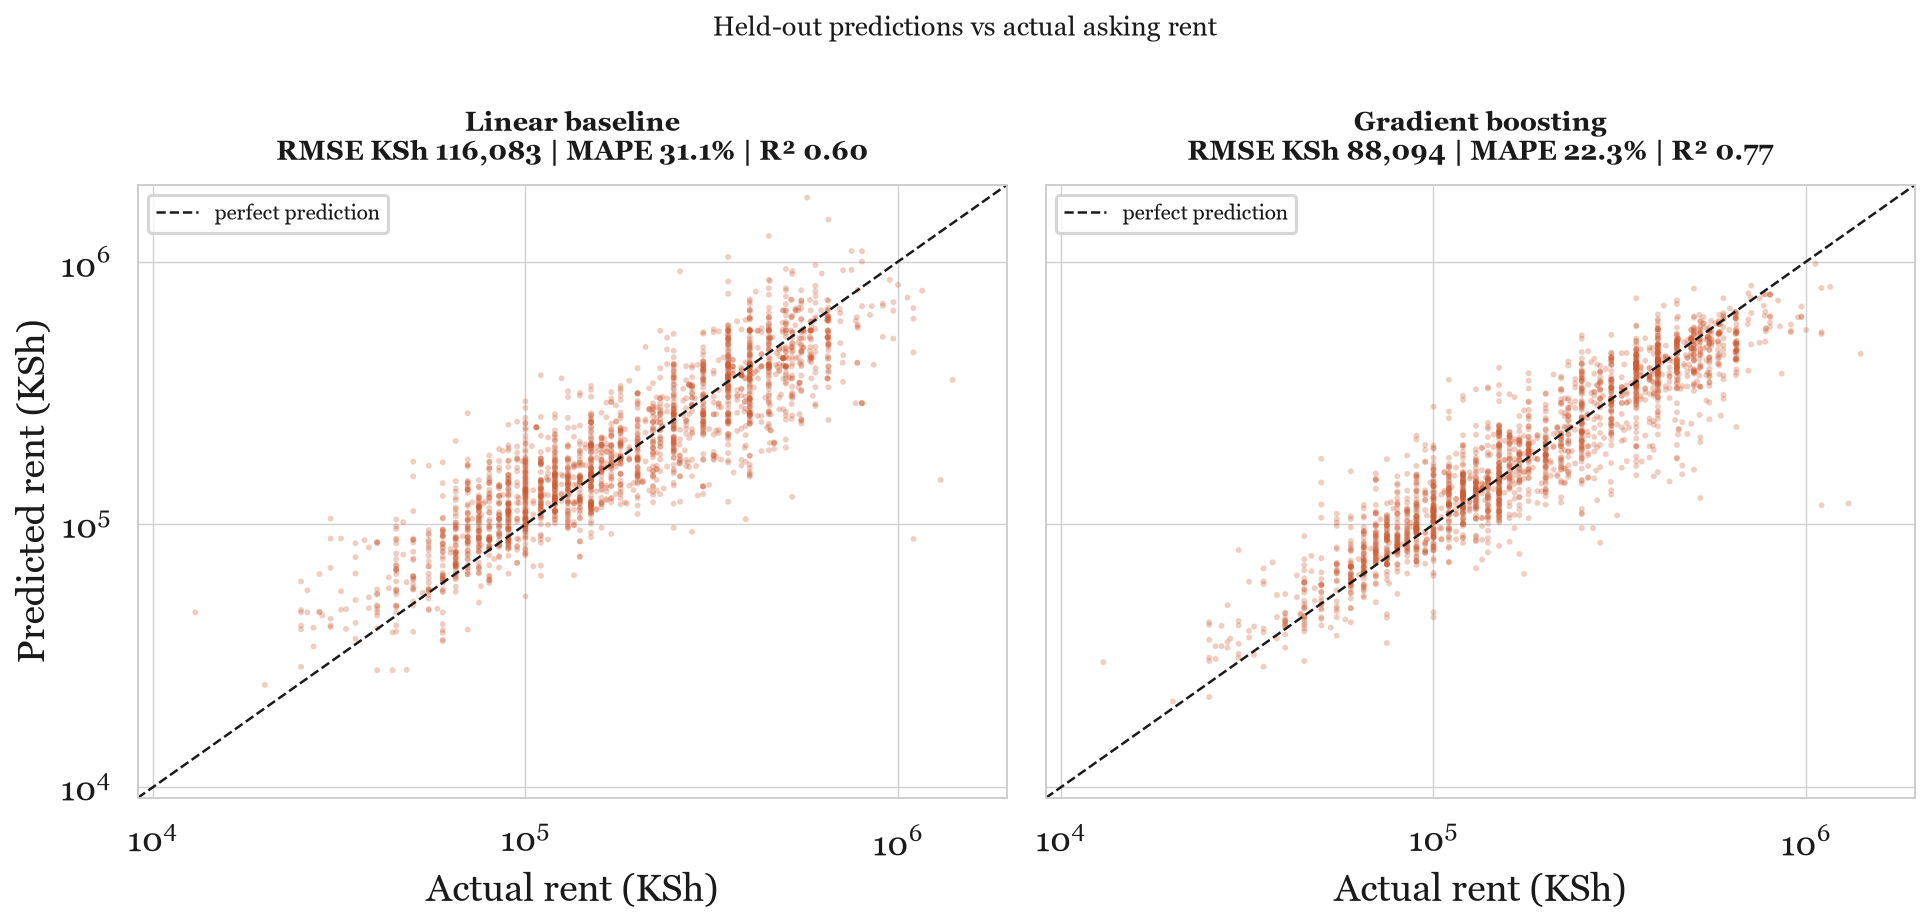

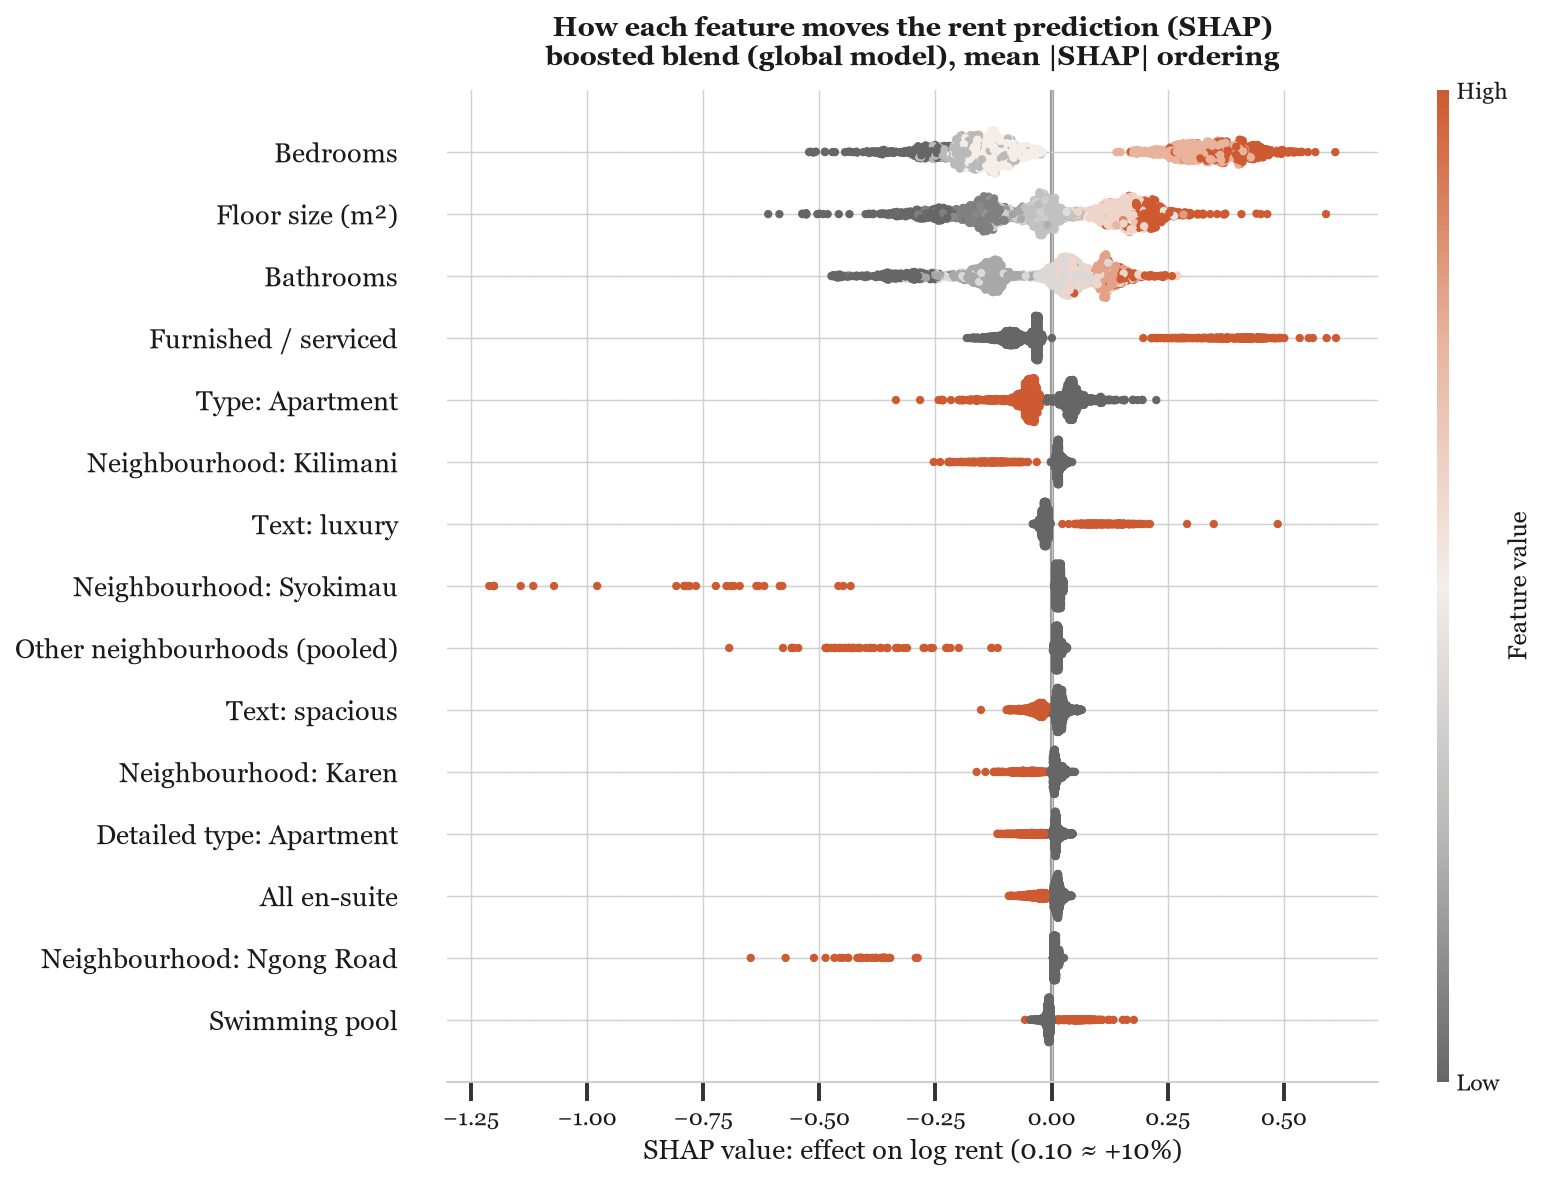

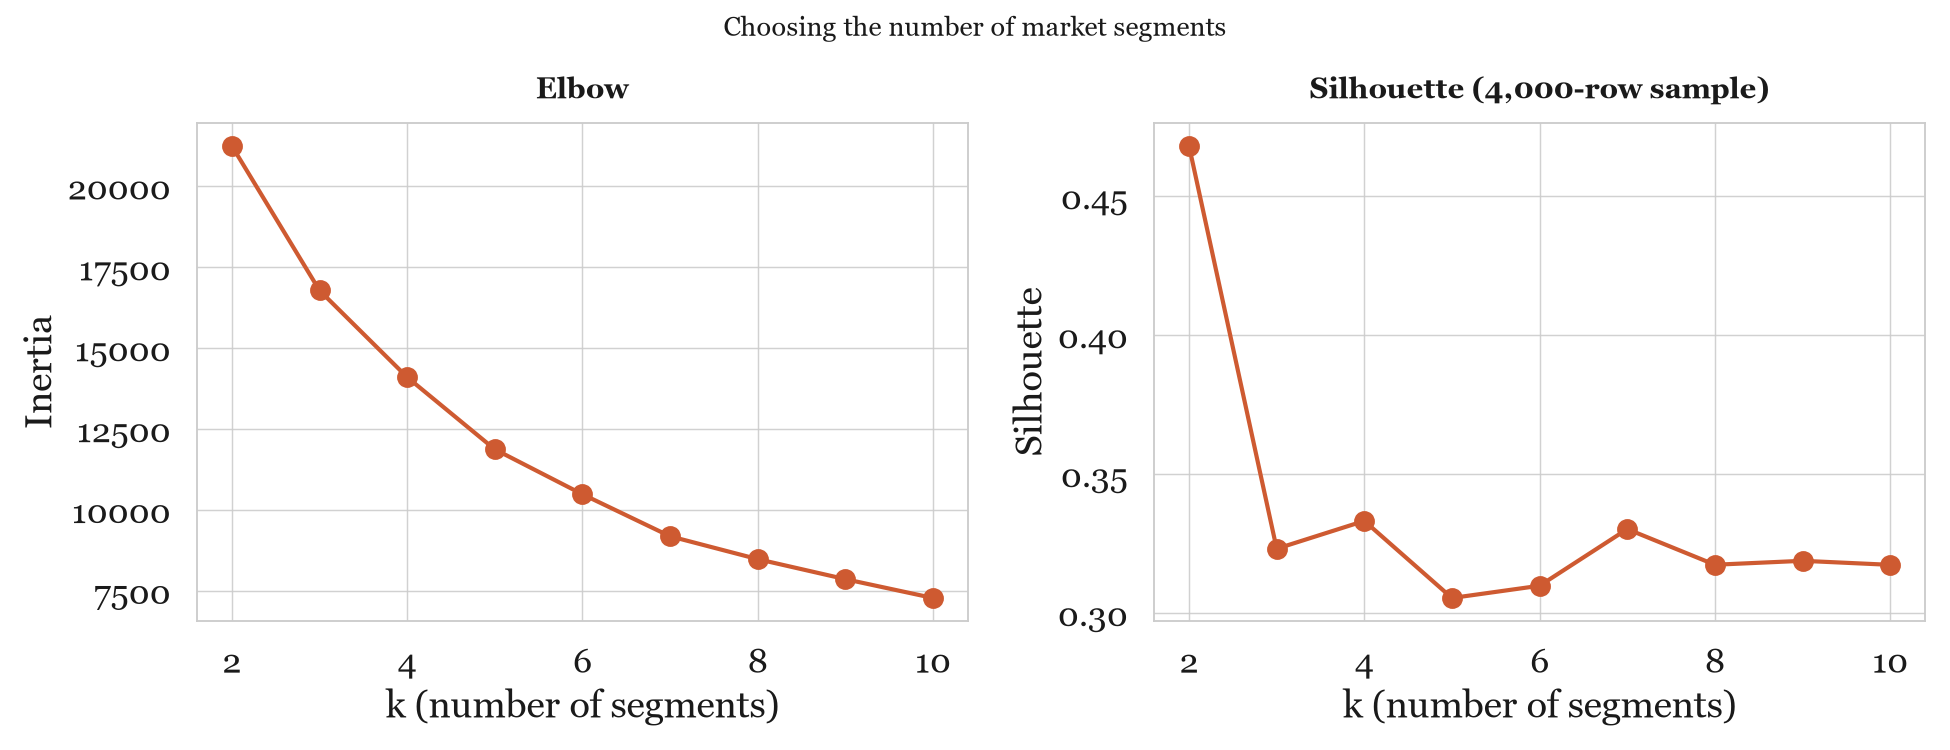

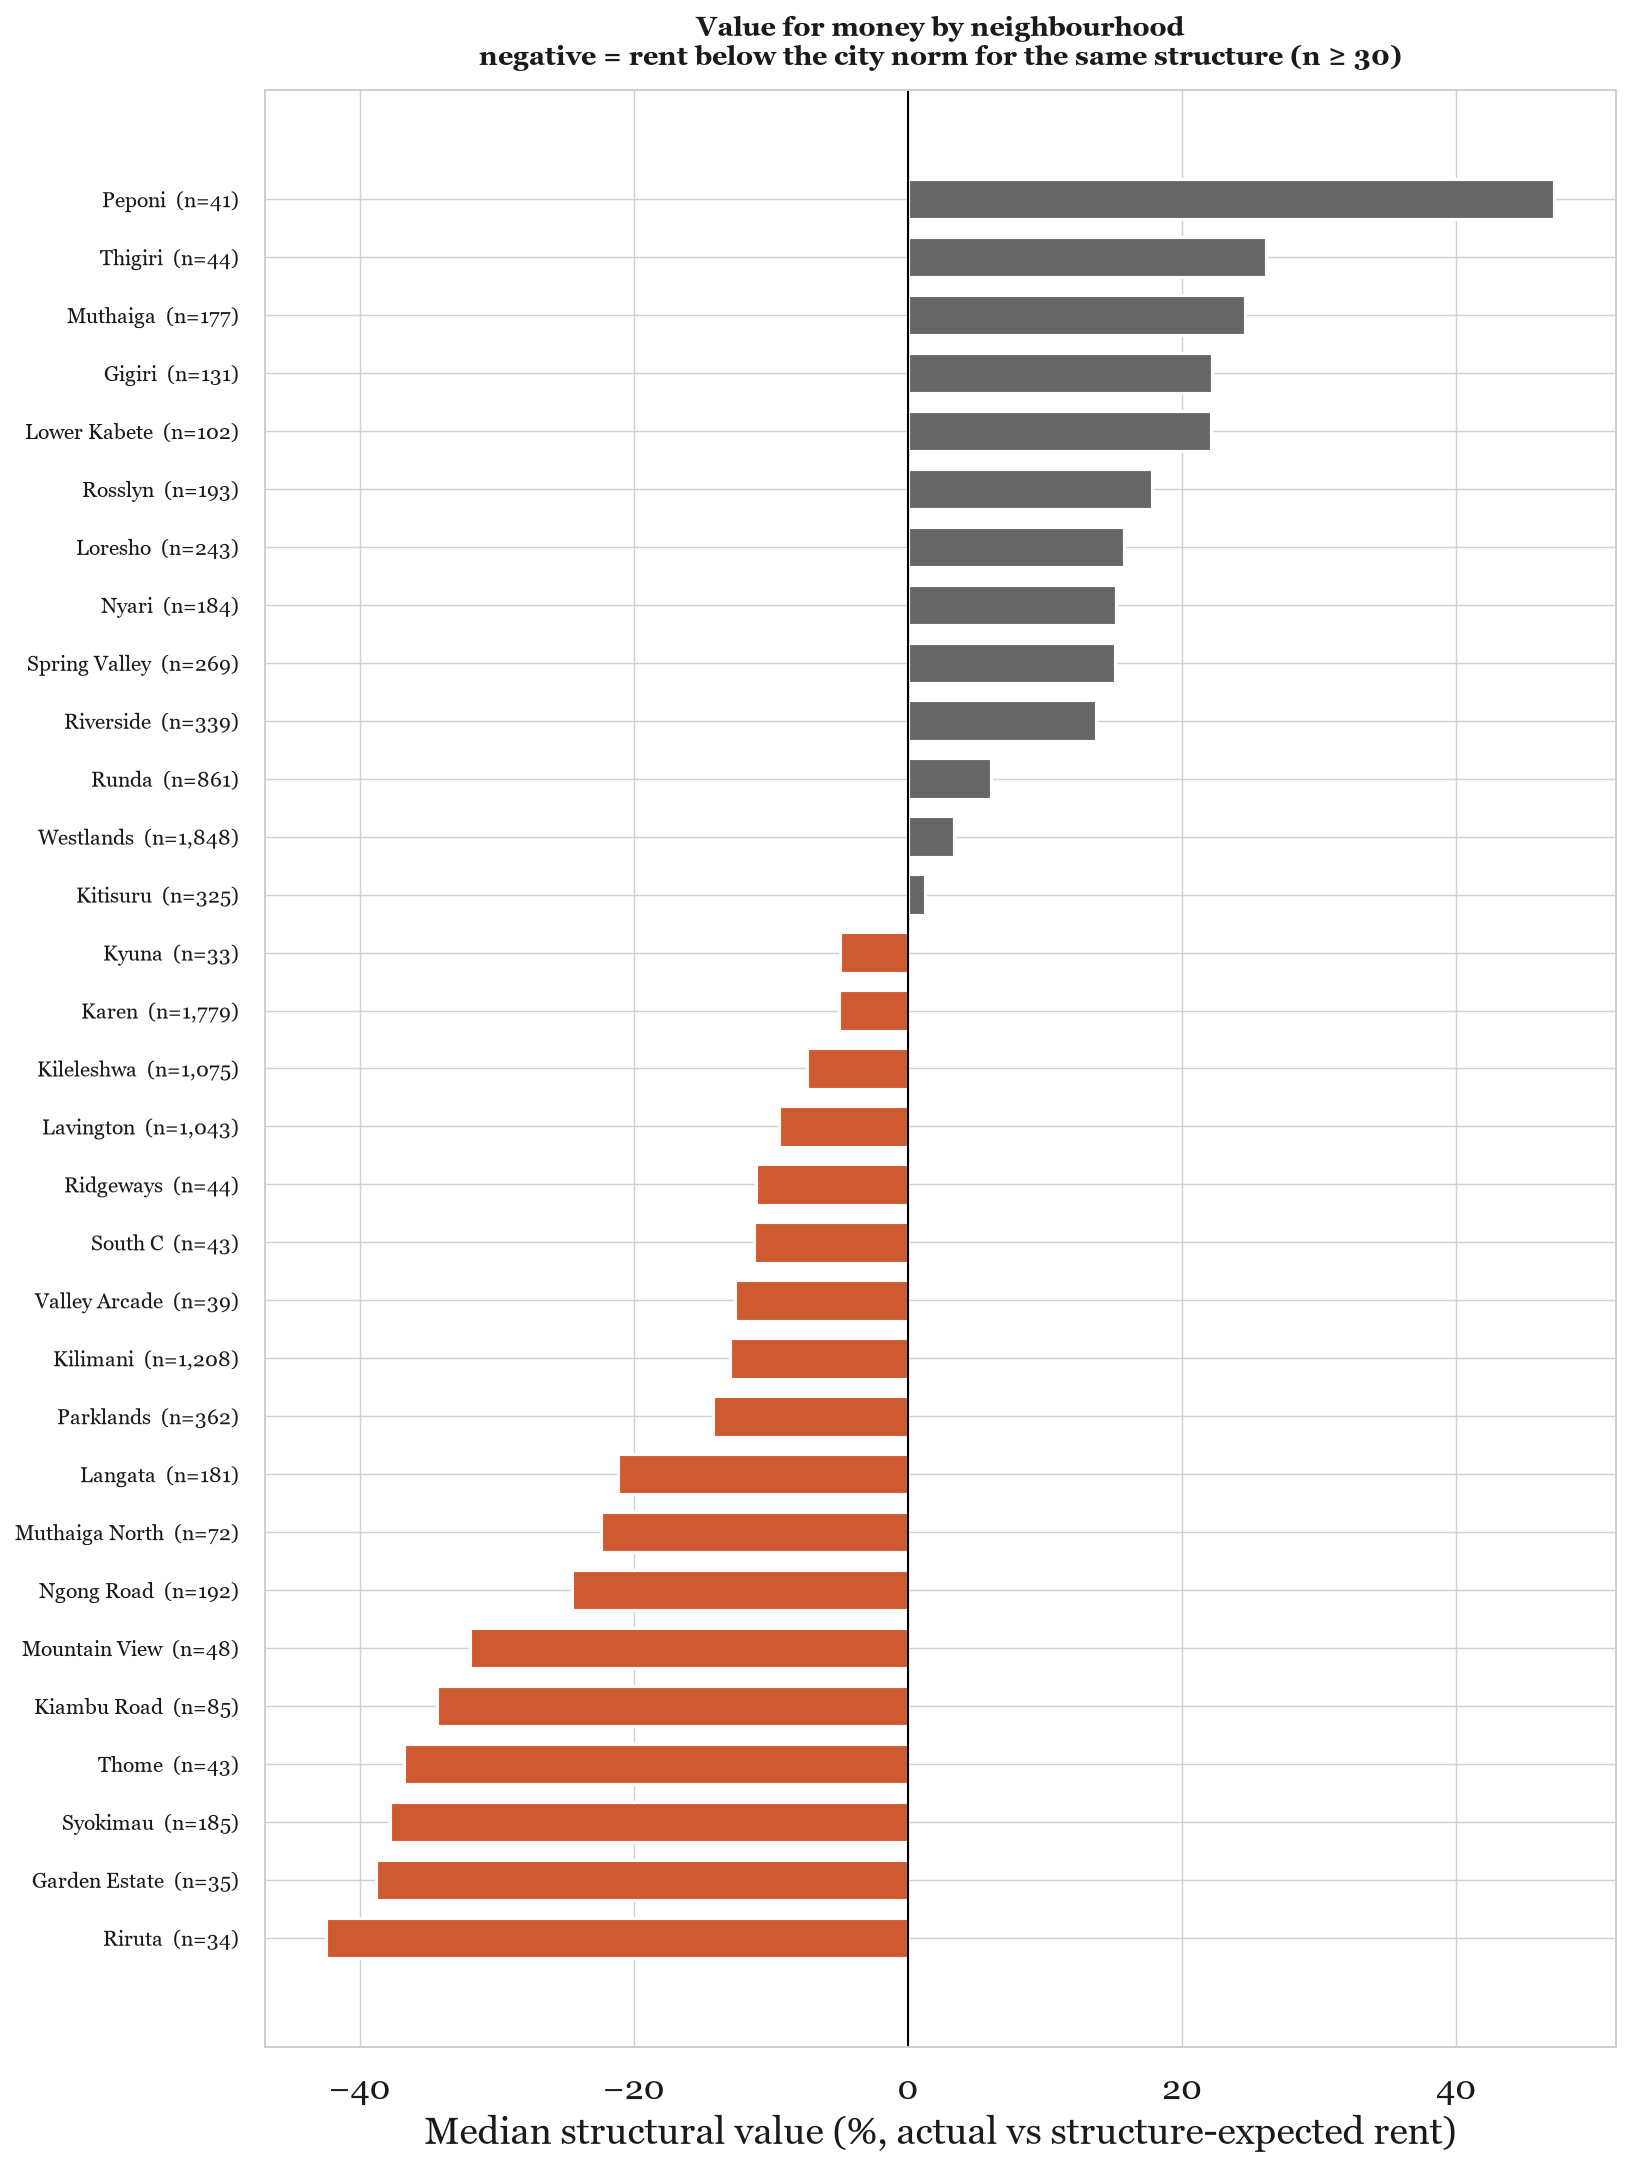

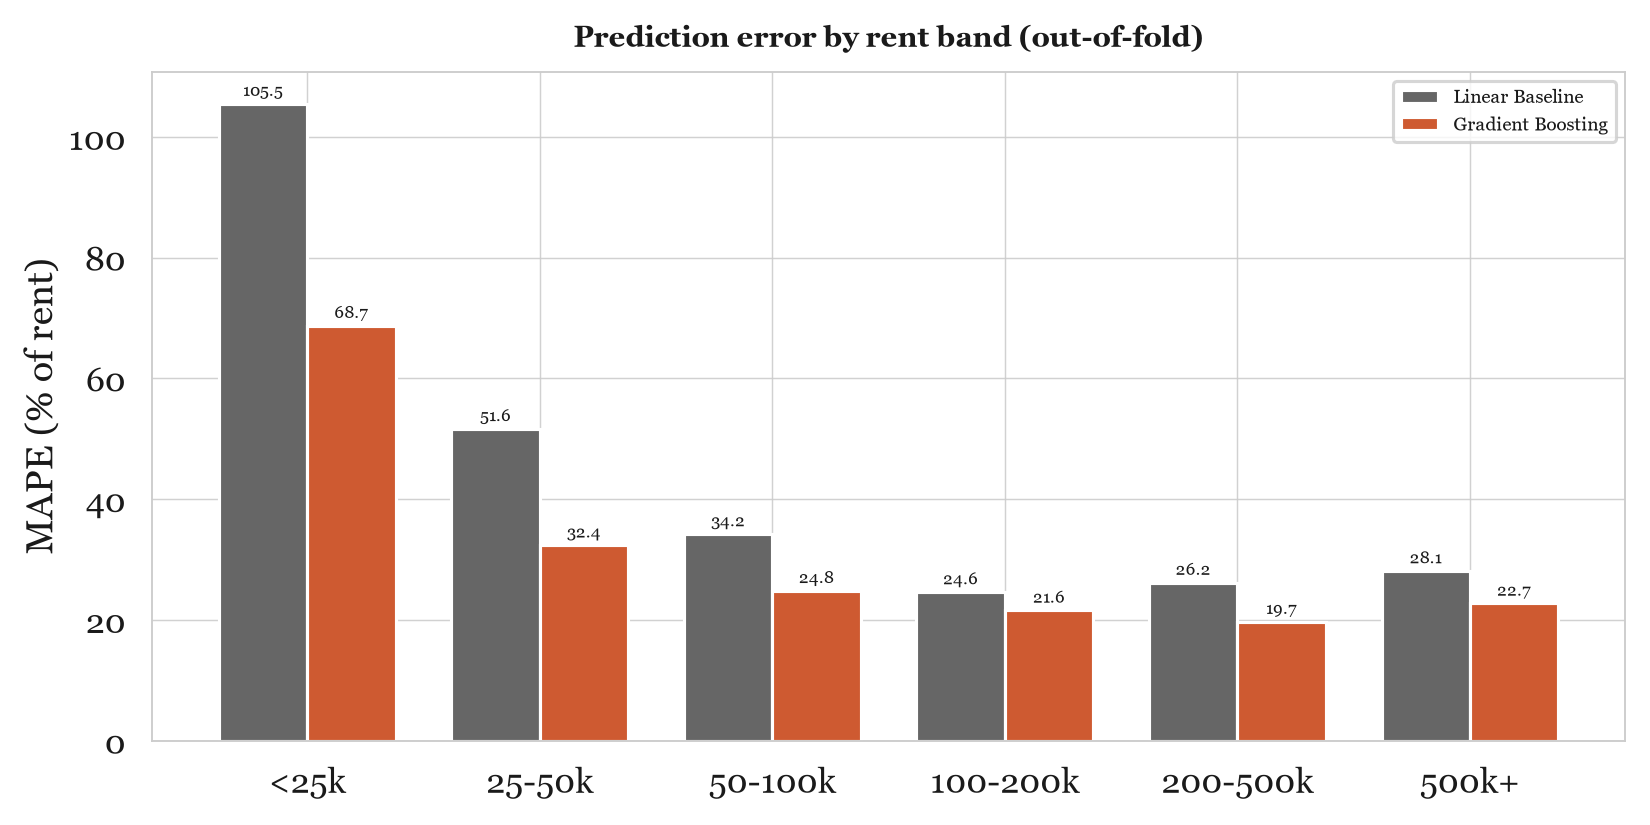

In [14]:
for name in ["fig_model_pred_vs_actual", "fig_model_shap",
             "fig_model_k_selection", "fig_model_value_by_neighborhood",
             "fig_model_error_by_band"]:
    display(Image(filename=ROOT / "reports" / "figures" / f"{name}.png"))

## 5. Rent guide

Plain-language tables for renters, built from the same cleaned table and
suppression rules.

In [15]:
from __future__ import annotations

import sys
from pathlib import Path

import pandas as pd

MIN_N = 30          # minimum reported group size
OUT = ROOT / "reports" / "rent_guide"

BEDROOM_ORDER = ["0 (studio/bedsitter)", "1", "2", "3", "4", "5+"]


def ksh(v: float) -> str:
    return f"KSh {v:,.0f}"


def place(v: str) -> str:
    return " ".join(w.capitalize() for w in str(v).split())


def run_guide(argv: list[str] | None = None) -> int:
    clean_path = ROOT / "data" / "clean" / "listings_clean.csv"
    if not clean_path.exists():
        print("ERROR: run the cleaning stage first", file=sys.stderr)
        return 1

    df = pd.read_csv(clean_path, low_memory=False)
    OUT.mkdir(parents=True, exist_ok=True)

    # ---- Table 1: typical rent by neighbourhood (n >= MIN_N) ------------
    nb = (df.groupby("neighborhood")["price_kes"]
            .agg(n="size",
                 p25=lambda s: s.quantile(0.25),
                 median="median",
                 p75=lambda s: s.quantile(0.75))
            .reset_index())
    nb = nb[nb["n"] >= MIN_N].sort_values("median", ascending=False)
    nb["typical_range"] = (nb["p25"].round(-3).astype(int).astype(str)
                           + " - "
                           + nb["p75"].round(-3).astype(int).astype(str))
    nb.to_csv(OUT / "guide_typical_rent_by_neighborhood.csv", index=False)

    # ---- Table 2: typical rent by bedroom count -------------------------
    bed = (df.groupby("bedroom_band")["price_kes"]
             .agg(n="size",
                  p25=lambda s: s.quantile(0.25),
                  median="median",
                  p75=lambda s: s.quantile(0.75))
             .reset_index())
    bed["_o"] = bed["bedroom_band"].map({b: i for i, b in enumerate(BEDROOM_ORDER)})
    bed = bed.sort_values("_o").drop(columns="_o")
    bed = bed[bed["n"] >= MIN_N]
    bed.to_csv(OUT / "guide_typical_rent_by_bedroom.csv", index=False)

    # ---- Table 3: best-value areas (structural value) -------------------
    value_src = ROOT / "reports" / "tables" / "model_value_by_neighborhood.csv"
    value_ok = value_src.exists()
    if value_ok:
        val = pd.read_csv(value_src)
        val = val[val["reported"]].sort_values("median_structural_value")
        val.head(15).to_csv(OUT / "guide_value_areas.csv", index=False)

    # ---- Table 4: most affordable areas per bedroom count ---------------
    aff_rows = []
    for band in BEDROOM_ORDER:
        sub = df[df["bedroom_band"] == band]
        if len(sub) < MIN_N:
            continue
        g = (sub.groupby("neighborhood")["price_kes"]
                .agg(n="size", median="median").reset_index())
        g = g[g["n"] >= MIN_N].nsmallest(5, "median")
        g.insert(0, "bedroom_band", band)
        aff_rows.append(g)
    aff = pd.concat(aff_rows, ignore_index=True)
    aff.to_csv(OUT / "guide_affordable_by_bedroom.csv", index=False)

    # ---- Assembled draft -------------------------------------------------
    lines = [
        "# Rent guide - Nairobi asking rents (draft numbers)",
        "",
        "Generated by `main.ipynb` from "
        "`data/clean/listings_clean.csv`. **Every figure below is produced "
        "by code and traceable to a table file** - the owner writes the "
        "final wording.",
        "",
        f"Coverage: {len(df):,} cleaned listings; groups below "
        f"{MIN_N} listings are not reported.",
        "",
        "## 1. What does rent cost in Nairobi?",
        "",
        f"- Overall median asking rent: **{ksh(df['price_kes'].median())}** "
        f"per month; the middle 50% of listings run from "
        f"{ksh(df['price_kes'].quantile(0.25))} to "
        f"{ksh(df['price_kes'].quantile(0.75))}.",
        "",
        "Typical rent by number of bedrooms:",
        "",
        "| Bedrooms | Listings | Typical range (middle 50%) | Median |",
        "|---|---:|---|---:|",
    ]
    for _, r in bed.iterrows():
        lines.append(
            f"| {r['bedroom_band']} | {int(r['n']):,} | "
            f"{ksh(r['p25'])} - {ksh(r['p75'])} | {ksh(r['median'])} |")
    lines += [
        "",
        "Source: `guide_typical_rent_by_bedroom.csv` "
        "(from `reports/tables/by_bedroom_band.csv`); figure: "
        "`reports/figures/fig_rent_by_bedrooms.png`.",
        "",
        "## 2. Typical rent by neighbourhood",
        "",
        f"{len(nb)} neighbourhoods have at least {MIN_N} listings. "
        "Full list: `guide_typical_rent_by_neighborhood.csv`. Most "
        "searched-for areas:",
        "",
        "| Neighbourhood | Listings | Median | Typical range (middle 50%) |",
        "|---|---:|---:|---|",
    ]
    top = nb.sort_values("n", ascending=False).head(12)
    for _, r in top.iterrows():
        lines.append(
            f"| {place(r['neighborhood'])} | {int(r['n']):,} | "
            f"{ksh(r['median'])} | {ksh(r['p25'])} - {ksh(r['p75'])} |")
    lines += [
        "",
        f"Priciest and cheapest by median (n >= {MIN_N}):",
        "",
        "| Neighbourhood | Median | Typical range |",
        "|---|---:|---|",
    ]
    for _, r in pd.concat([nb.head(5), nb.tail(5)]).iterrows():
        lines.append(
            f"| {place(r['neighborhood'])} | {ksh(r['median'])} | "
            f"{ksh(r['p25'])} - {ksh(r['p75'])} |")
    lines += [
        "",
        "Source: `guide_typical_rent_by_neighborhood.csv`; figure: "
        "`reports/figures/fig_rent_by_neighborhood.png`.",
        "",
        "## 3. Where is the best value?",
        "",
        "Value here compares what a listing costs with what the **same kind of "
        "dwelling** (same bedrooms, bathrooms, floor size, property type and "
        "amenities) costs city-wide. A negative score means the area gives you "
        "more dwelling per shilling than the city norm for that structure "
        "measure 1).",
        "",
    ]
    if value_ok:
        val_lines = [
            "| Neighbourhood | Listings | Median value vs structure | "
            "Listings more than 15% below |",
            "|---|---:|---:|---:|",
        ]
        for _, r in val.head(12).iterrows():
            val_lines.append(
                f"| {place(r['neighborhood'])} | {int(r['n']):,} | "
                f"{r['median_structural_value']:+.1%} | "
                f"{r['pct_structurally_cheap']:.0f}% |")
        lines += val_lines + [
            "",
            "Source: `guide_value_areas.csv` (from "
            "`reports/tables/model_value_by_neighborhood.csv`); figure: "
            "`reports/figures/fig_model_value_by_neighborhood.png`.",
        ]
    else:
        lines.append("_Value table unavailable - run the modelling stage first._")
    lines += [
        "",
        "## 4. Five most affordable areas for each home size",
        "",
        "| Bedrooms | Five cheapest areas (by median) |",
        "|---|---|",
    ]
    for band in aff["bedroom_band"].unique():
        sub = aff[aff["bedroom_band"] == band]
        cells = ", ".join(f"{place(r.neighborhood)} "
                          f"({ksh(r.median)})" for r in sub.itertuples())
        lines.append(f"| {band} | {cells} |")
    lines += [
        "",
        "Source: `guide_affordable_by_bedroom.csv`.",
        "",
        "## Figures for the guide",
        "",
        "| Figure | Shows |",
        "|---|---|",
        "| `reports/figures/fig_rent_distribution.png` | spread of asking rents |",
        "| `reports/figures/fig_rent_by_neighborhood.png` | median and IQR by neighbourhood |",
        "| `reports/figures/fig_rent_by_bedrooms.png` | rent by bedroom count |",
        "| `reports/figures/fig_rent_by_property_type.png` | apartments vs houses vs townhouses |",
        "| `reports/figures/fig_neighborhood_heatmap.png` | neighbourhood x bedrooms matrix |",
        "| `reports/figures/fig_model_value_by_neighborhood.png` | value for money ranking |",
        "",
        "## Caveats to repeat in the guide",
        "",
        "- These are **asking rents from portal listings, not signed "
        "leases**; a negotiated rent may differ.",
        "- The sample is the portals' own ordering of their first search "
        "pages - not a random sample of all Nairobi housing, and informal "
        "housing is under-represented.",
        "- USD-quoted listings were excluded, so the very top of the market "
        "is under-represented.",
        f"- Anything below {MIN_N} listings in an area is not reported.",
        "- Some results cover metropolitan satellite towns (Syokimau, "
        "Mlolongo, Ruaka, Lower Kabete) that the Nairobi-wide portal search "
        "also returned; they are flagged in `listings_clean.csv` "
        "(`is_satellite_town`) and the report shows a Nairobi-County-only "
        "sensitivity check.",
        "- A negative value score is a comparison with the city norm for the "
        "same structure, not a promise that a specific listing is fairly "
        "priced; always inspect the unit.",
    ]
    (OUT / "RENT_GUIDE.md").write_text("\n".join(lines), encoding="utf-8")

    for f in sorted(OUT.iterdir()):
        print(f"  {f.relative_to(ROOT)}")
    print(f"neighbourhoods reported: {len(nb)} | bedroom bands: {len(bed)}"
          f" | affordable rows: {len(aff)}")
    return 0

_t0 = time.perf_counter()
_exit_code = run_guide([])
print(f"stage 'guide' exit {_exit_code} in "
      f"{time.perf_counter() - _t0:.1f} s")

  reports\rent_guide\guide_affordable_by_bedroom.csv
  reports\rent_guide\guide_typical_rent_by_bedroom.csv
  reports\rent_guide\guide_typical_rent_by_neighborhood.csv
  reports\rent_guide\guide_value_areas.csv
  reports\rent_guide\RENT_GUIDE.md
neighbourhoods reported: 31 | bedroom bands: 6 | affordable rows: 25
stage 'guide' exit 0 in 0.3 s


### Deliverables

In [16]:
guide = ROOT / "reports" / "rent_guide"
display(pd.read_csv(guide / "guide_typical_rent_by_bedroom.csv")
        [["bedroom_band", "n", "p25", "median", "p75"]])

artefacts = sorted(
    [p for p in (ROOT / "reports").rglob("*") if p.is_file()]
    + [p for p in (ROOT / "data" / "clean").rglob("*") if p.is_file()])
manifest = pd.DataFrame({
    "path": [str(p.relative_to(ROOT)) for p in artefacts],
    "KB": [round(p.stat().st_size / 1024, 1) for p in artefacts],
})
print(f"generated artefacts: {len(manifest)}")
display(manifest.head(12))

,bedroom_band,n,p25,median,p75
0,0 (studio/bedsitter),60,"24,500.00","45,000.00","56,250.00"
1,1,1085,"55,000.00","70,000.00","120,000.00"
2,2,2608,"75,000.00","100,000.00","160,000.00"
3,3,3111,"100,000.00","140,000.00","200,000.00"
4,4,2758,"200,000.00","340,000.00","430,000.00"
5,5+,2009,"350,000.00","450,000.00","550,000.00"


generated artefacts: 48


,path,KB
0,data\clean\cleaning_log.csv,3.00
1,data\clean\cleaning_log_rows.csv,974.10
2,data\clean\cleaning_summary.md,4.50
3,data\clean\listings_clean.csv,"11,935.60"
4,reports\data_profile.json,0.70
5,reports\data_profile.md,6.10
6,reports\figures\fig_model_error_by_band.png,63.50
7,reports\figures\fig_model_k_selection.png,105.30
8,reports\figures\fig_model_pred_vs_actual.png,300.50
9,reports\figures\fig_model_shap.png,195.70


## 6. Audit

The closing checks confirm the cleaned table, the model comparison and the
artefact counts. A failure raises, so a green run means the numbers in the
report can be trusted.

In [17]:
checks = {}

def check(label, condition):
    checks[label] = bool(condition)
    print(("PASS  " if condition else "FAIL  ") + label)

raw = pd.read_csv(ROOT / "data" / "raw" / "rentals.csv", low_memory=False)
clean = pd.read_csv(ROOT / "data" / "clean" / "listings_clean.csv",
                    low_memory=False)

check("raw export has 15,750 rows", len(raw) == 15750)
check("cleaned table has 11,645 rows", len(clean) == 11645)
check("cleaned table has 78 columns", clean.shape[1] == 78)
check("every price is monthly", set(clean["period"].astype(str)) == {"month"})
check("no duplicate listing URLs", int(clean["url"].duplicated().sum()) == 0)
check("prices inside the declared bounds",
      clean["price_kes"].between(8000, 5_000_000).all())
check("bedrooms capped at 10", clean["bedrooms"].max() <= 10)
check("floor sizes inside 12 to 1,500 m2",
      clean["size_sqm"].dropna().between(12, 1500).all())
check("73 neighbourhoods", clean["neighborhood"].nunique() == 73)
check("satellite towns flagged", int(clean["is_satellite_town"].sum()) == 556)

hold = (pd.read_csv(T / "model_metrics.csv")
        .query("evaluation == 'holdout_20pct'").set_index("model"))
check("boosting beats linear on MAPE",
      hold.loc["gradient_boosting", "mape_pct"]
      < hold.loc["linear_baseline", "mape_pct"])
check("boosting R2 above 0.70",
      hold.loc["gradient_boosting", "r2_ksh"] > 0.70)
check("12 figures written",
      len(list((ROOT / "reports" / "figures").glob("*.png"))) == 12)
check("5 rent-guide files written",
      len(list((ROOT / "reports" / "rent_guide").glob("*"))) == 5)

failed = [name for name, ok in checks.items() if not ok]
print(f"\n{len(checks)} checks, {len(checks) - len(failed)} passed")
if failed:
    raise AssertionError(failed)

PASS  raw export has 15,750 rows


PASS  cleaned table has 11,645 rows
PASS  cleaned table has 78 columns


PASS  every price is monthly
PASS  no duplicate listing URLs
PASS  prices inside the declared bounds
PASS  bedrooms capped at 10
PASS  floor sizes inside 12 to 1,500 m2
PASS  73 neighbourhoods
PASS  satellite towns flagged
PASS  boosting beats linear on MAPE
PASS  boosting R2 above 0.70
PASS  12 figures written
PASS  5 rent-guide files written

14 checks, 14 passed


## 7. Private bundle for the deployed dashboard

The deployed dashboard cannot read local files, and the cleaned table must not
be published. This cell writes one zip containing the columns the dashboard
uses plus its five model tables. Upload it to private storage and point the
Streamlit app at it with a `DATA_URL` secret; see `README.md`.

In [18]:
SAFE_COLS = [
    "source", "price_kes", "bedrooms", "bathrooms", "parking", "size_sqm",
    "kind", "kind_group", "neighborhood", "bedroom_band", "price_band",
    "size_band", "ptype", "flag_price_luxury", "flag_short_stay",
    "flag_size_missing", "flag_parking_missing", "is_satellite_town",
    "is_furnished", "has_dsq", "has_pool", "has_gym",
]
MODEL_TABLES = [
    "model_metrics", "model_cluster_profiles", "model_value_by_neighborhood",
    "model_shap_importance", "model_error_by_price_band",
]

deploy = ROOT / "data" / "deploy"
deploy.mkdir(parents=True, exist_ok=True)
bundle = deploy / "dashboard_bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as zipped:
    zipped.writestr("listings_clean.csv",
                    clean[SAFE_COLS].to_csv(index=False))
    for name in MODEL_TABLES:
        zipped.write(ROOT / "reports" / "tables" / f"{name}.csv",
                     f"tables/{name}.csv")

print(f"wrote {bundle.relative_to(ROOT)} | "
      f"{bundle.stat().st_size / 1e6:.2f} MB | "
      f"{len(SAFE_COLS)} columns, {len(MODEL_TABLES)} tables")

wrote data\deploy\dashboard_bundle.zip | 0.12 MB | 22 columns, 5 tables


## Done

Running this notebook top to bottom rebuilds every table, figure, model result
and document, audits them, and packages the dashboard data. Nothing outside
the notebook is needed to reproduce the analysis.